# How should a model send back its edits to a long document?

## Asking a model to change one number

Suppose you look after a 40-page regulation, about 12,000 words, and one figure in it is wrong: a paragraph says
comments are due within 30 days where it should say 45. You paste the document into a chat with a language model
and ask it to make the change. Making the change is easy for the model. The harder question is what it should
send back.

The obvious answer is the whole document with the number changed. That is what a person returns after editing a
file, and it needs no special software: you replace the old file with the new one. But to change two characters
the model has to write out all 12,000 words again. That takes two or three minutes, costs as much output as
writing the document from scratch, and gives the model 12,000 chances to change something nobody asked it to
change: a curly quotation mark straightened, a paragraph left out, a sentence reworded. Nobody rereads 40 pages
to check that only one number moved.

The other answer is to send back only the change, something like "replace `within 30 days` with `within 45 days`".
That reply is a dozen words long. But now a program has to merge it into the document: find the place the model
meant and make the change there and nowhere else. Programmers have done this for decades with diff and patch
tools, which describe a change by the lines it removes and adds. Code editors built on language models face the
same problem every time they apply a suggested change to a file, and they have settled on different answers.
Some have the model rewrite the whole file, some ask for search-and-replace pairs, and some ask for a patch.

## A small example, and where it goes wrong

Here is an illustrative case, made up for this explanation. A five-paragraph notice says, in its third paragraph,
"Comments must be received within 30 days of publication." The request is to change 30 to 45. A
search-and-replace reply looks like this:

```
<<<<<<< SEARCH
received within 30 days
=======
received within 45 days
>>>>>>> REPLACE
```

The merging program looks for `received within 30 days`, finds it exactly once, and swaps in the new text. The
other four paragraphs are never touched, so they cannot be damaged.

Now add one complication. The fourth paragraph contains the words "the agency’s address", with a curly
apostrophe, and a second request asks for that phrase to become "the office’s address". The model quotes it with
a straight apostrophe: `the agency's address`. An exact search finds nothing, and the edit fails. A forgiving
program could compare the texts after straightening quotes and collapsing spaces, or accept the most similar
passage when no exact match exists, and so rescue the edit.

Forgiveness has a price. If the fifth paragraph also said "within 30 days", a program that accepts "the most
similar passage" might change the wrong one. A failed edit announces itself, because the program reports that it
could not find the text. A misplaced edit does not: the document comes back looking finished. A merging rule
therefore trades failures you can see against mistakes you cannot.

There is a middle way between strict and forgiving. When an edit fails, tell the model what went wrong ("the text
in block 2 was not found in the document") and let it try once more. That costs another call but keeps the
merging rule strict.

## Two decisions

Getting an edit into a long document therefore involves two decisions. The first is the reply format: how the
model writes the edit. The second is the merge method: how a program, or a second model, turns that reply into
the edited document.

This notebook compares seven reply formats. In plain terms they are:

- the whole edited document, written out again;
- find-and-replace pairs, written either as marked blocks like the one above or as a JSON list;
- a unified diff, the standard format programmers use, which marks removed lines with `-` and added lines with `+`
  and states the line number where each change starts, so the model has to count lines;
- OpenAI's patch format, which looks like a diff but has no line numbers and finds each change by the unchanged
  lines around it, optionally helped by a locator line that names a nearby heading;
- commands by line number ("replace line 41 with ..."), with the document shown to the model with its lines
  numbered;
- an edit sketch: only the changed passages, with a marker such as `[... unchanged ...]` wherever text is left out,
  which a program or a second model then merges into the full document, the way some code editors apply
  suggestions.

For each format it compares the merge methods that format allows: an exact match; a match that ignores
differences in spacing and quotation marks; a fuzzy match that accepts the most similar passage; the standard
command-line tools `git apply` and GNU `patch`; placing a diff's changes by their surrounding lines while ignoring
its line numbers; a second model that writes out the merged document; and one retry with the error message.

## The question

When a model edits a long document, which reply format, merged in which way, most often gives exactly the
document that was asked for, and what does each choice cost in output, time and damage to text that should not
change?

The test uses nine US Federal Register rules and proposed rules published between 19 and 29 October 2026, after
every model's training data was collected, ranging from 1,842 to 12,762 words. Each document gets four edit
requests (a single change, six mixed changes, renaming an abbreviation everywhere, and twenty small changes), 36
requests with 241 individual edits in all. The exact text to insert is always given, so every request has one
correct result, computed in code. Five models write every request in every format: GPT-6.1 Sol, Claude Sonnet 5.5,
Claude Haiku 5.5, DeepSeek V4.1 Flash and Qwen3.8 27B. That is 1,440 replies (the OpenAI patch format was tested
with two wordings of its instructions), each merged by every method its format allows.

A useful answer tells someone building an editing tool which format to ask for, which merging code to write, and
when to pay for a retry or a second model.

## Study summary

The main measure is the share of requests whose merged document is exactly the expected one, out of 180 per format
(36 requests by 5 models). Asking for find-and-replace pairs and merging them with an exact string match did best:
SEARCH/REPLACE blocks gave the exact document for 148 of 180 requests (82%) and JSON pairs for 151 (84%), rising to
153 (85%) and 154 (86%) when a failed reply got one retry. Rewriting the whole document came close at 146 (81%), and so
did a unified diff placed by its context lines rather than its line numbers, 142 (79%) with a retry. Line-number edits
reached 141 (78%). Edit sketches (115, 64%) and OpenAI's patch format (106, 59% at best) trailed.

The merge method mattered for diffs and patches, not for find-and-replace. Plain `git apply` merged only 74 of the
180 diffs, mostly because models drop a hunk's last blank line; GNU `patch` merged 126 and the most forgiving method
139 from the same replies. For find-and-replace, forgiving matches rescued nothing: models quoted text exactly, and
their failures were edits left out. A second model (Claude Haiku 5.5) writing out the merged document did worse than
code (103 of 180 against 148 for SEARCH/REPLACE), skipping blocks and once keeping "Act of 1995" when the edit said
2000.

The format also sets the cost. A find-and-replace reply took a median of 17 seconds and about 1,500 output tokens at
every length; a whole rewrite took 31 seconds on short documents and 115 on long ones; diffs and patches cost about as
much as rewriting (around 70 seconds), because the models reasoned at length to write them.

In the original situation: ask for find-and-replace pairs, apply them with an exact match, and send failures back
once. The number changes in seconds, the other 11,999 words stay untouched in 97% of replies, and failures are mostly
omissions a simple check can catch. The exception is renaming a term everywhere (51% at best), where a rewrite did
better (84%).

The main caveat is that the model mattered more than the format. GPT-6.1 Sol was exact on all 36 requests in three
formats, so for it the test is at its ceiling and cannot rank them; Qwen3.8 27B ranged from 44% (whole rewrite) to 78%
(JSON pairs with a retry). The ranking is decided by the four models below the ceiling.

## Contents

1. [Setup and configuration](#1-setup-and-configuration)
2. [The documents](#2-the-documents)
3. [The edit requests](#3-the-edit-requests)
4. [The reply formats](#4-the-reply-formats)
5. [The merge methods](#5-the-merge-methods)
6. [How a reply is scored](#6-how-a-reply-is-scored)
7. [Checking the merge methods](#7-checking-the-merge-methods)
8. [The models](#8-the-models)
9. [Running the edits, retries and merges](#9-running-the-edits-retries-and-merges)
10. [Results](#10-results)
11. [Error analysis](#11-error-analysis)
12. [Spend](#12-spend)
13. [Limitations](#13-limitations)
14. [How to reproduce](#14-how-to-reproduce)
15. [Future work and further reading](#15-future-work-and-further-reading)

How one request travels through the study:

```mermaid
flowchart TD
    fr["Federal Register API<br/>137 rules and proposed rules, 19-29 Oct 2026"] --> docs["9 documents, 3 per length band<br/>1,842 to 12,762 words, converted to Markdown"]
    docs --> tasks["36 edit requests: 4 bundles x 9 documents<br/>241 edits, one exact expected document each"]
    tasks --> prompts["288 prompts<br/>36 requests x 8 format instructions"]
    prompts --> gen["1,440 replies<br/>5 models x 288 prompts"]
    gen --> det["Deterministic merge methods<br/>exact, tolerant, fuzzy, git apply, GNU patch, context search, ..."]
    gen -->|"strict method failed"| retry["439 retries<br/>same model, shown its reply and the errors"]
    retry --> det
    gen -->|"sketch, SEARCH/REPLACE and diff replies"| llm["525 LLM merges<br/>Claude Haiku 5.5 writes the whole document"]
    det --> score["Compare with the expected document<br/>exact / wrong / unreadable, edits done, collateral changes"]
    llm --> score
```

The model calls for one reply, and what each passes to the next:

```mermaid
flowchart LR
    p["Prompt<br/>document + numbered edits + format rules"] --> m["Model under test<br/>codex exec, claude -p or OpenRouter<br/>returns a reply in one format"]
    m --> s{"Strict merge<br/>exact match, git apply,<br/>reference rules, line numbers"}
    s -->|"every block placed"| d1["Merged document"]
    s -->|"a block failed"| r["Same model, second call<br/>original prompt + its reply + error lines<br/>returns a corrected reply"]
    r --> s2["Strict or fuzzy merge"] --> d2["Merged document"]
    m -->|"sketch, SEARCH/REPLACE, diff"| h["Claude Haiku 5.5, claude -p, low effort<br/>original document + the reply<br/>returns the whole merged document"]
    h --> d3["Merged document"]
```

The retry call waits for the strict merge to report a failure; the merge-model call runs on every sketch,
SEARCH/REPLACE and diff reply, independently of the retry.

## 1. Setup and configuration

The first cell sets the size knobs and the models, and defines small helpers that later cells use to find
paragraphs, split sentences and choose the phrases that edits change. `N_DOCS` (nine documents, three per length
band) and `MODELS` set the size of the run. `NB_LIVE=1` allows new model calls; without it every reply is read from
the caches in `data/`, and a missing reply stops the notebook with its request key. `PROTOCOL` is part of every
cache key, so a changed design cannot silently reuse old replies.

The system prompt, the same for every model and every format, is "You edit documents exactly as instructed. Reply
only in the format the user asks for."

In [1]:
import csv
import difflib
import gzip
import hashlib
import json
import os
import random
import re
import shutil
import subprocess
import tempfile
import threading
import time
import unicodedata
import xml.etree.ElementTree as ET
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import requests
from IPython.display import Markdown, display

ROOT = Path.cwd()
DATA = ROOT / 'data'
DATA.mkdir(exist_ok=True)
LIVE = os.environ.get('NB_LIVE') == '1'
MODELS = {
    'GPT-6.1 Sol': ('codex', 'gpt-6.1-sol'),
    'Claude Sonnet 5.5': ('claude', 'claude-sonnet-5-5'),
    'Claude Haiku 5.5': ('claude', 'claude-haiku-5-5'),
    'Qwen3.8 27B': ('openrouter', 'qwen/qwen3.8-27b'),
    'DeepSeek V4.1 Flash': ('openrouter', 'deepseek/deepseek-v4.1-flash-1017'),
}
ALL_MODELS = dict(MODELS)
MERGE_MODEL = ('Claude Haiku 5.5', 'claude', 'claude-haiku-5-5')
EFFORT = 'medium'
MERGE_EFFORT = 'low'
N_DOCS = int(os.environ.get('NB_N_DOCS', '9'))
FORMATS = ['full', 'search_replace', 'json_replace', 'udiff', 'apply_patch', 'line_edits', 'sketch', 'apply_patch_openai']
BUNDLES = ['one', 'mixed6', 'rename', 'many20']
MAX_CLI_CALLS = 3000
MAX_CLAUDE_USD = 80.0
MAX_OPENROUTER_USD = 15.0
PROTOCOL = 'nb38-v1'
SYSTEM = 'You edit documents exactly as instructed. Reply only in the format the user asks for.'
if os.environ.get('NB_MODELS'):
    labels = [s.strip() for s in os.environ['NB_MODELS'].split(',')]
    MODELS = {label: ALL_MODELS[label] for label in labels}
if N_DOCS < 3 or N_DOCS % 3:
    raise ValueError('NB_N_DOCS must be a positive multiple of 3 (equal length bins).')

# One plot style for this notebook (rcParams copied from notebook 29).
import matplotlib.pyplot as plt
import numpy as np

COLORS = {'blue': '#2468ac', 'orange': '#dc793a', 'green': '#3a9175', 'purple': '#8d63ad', 'grey': '#9a9a9a',
          'red': '#c0392b', 'light': '#d9d9d9', 'dark': '#333333'}
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight', 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2, 'axes.axisbelow': True,
                     'axes.titlelocation': 'left', 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'font.size': 9,
                     'figure.facecolor': 'white'})
MODEL_ORDER = ['GPT-6.1 Sol', 'Claude Sonnet 5.5', 'Claude Haiku 5.5', 'DeepSeek V4.1 Flash', 'Qwen3.8 27B']
MODEL_COLORS = dict(zip(MODEL_ORDER, [COLORS[c] for c in ['blue', 'orange', 'green', 'purple', 'dark']]))
MODEL_MARKERS = dict(zip(MODEL_ORDER, ['o', 's', '^', 'D', 'P']))
STATUS_COLORS = {s: COLORS[c] for s, c in [('exact', 'green'), ('wrong', 'red'), ('unreadable', 'grey')]}
STATUS_HATCHES = {'exact': '', 'wrong': '///', 'unreadable': '...'}


def write_text(path, text):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('w', encoding='utf-8', newline='\n') as f:
        f.write(text)


def canonical(obj):
    return json.dumps(obj, sort_keys=True, ensure_ascii=False, separators=(',', ':'))


def digest(obj):
    return hashlib.sha256(canonical(obj).encode('utf-8')).hexdigest()


def sha(text):
    return hashlib.sha256(text.encode('utf-8')).hexdigest()


def write_json(path, obj):
    write_text(path, json.dumps(obj, ensure_ascii=False, indent=2) + '\n')


def document_lines(text):
    # A final newline terminates the last line; it is not an extra blank line.
    return text.replace('\r\n', '\n').splitlines()


def lines_text(lines):
    return '\n'.join(lines) + '\n'


DOUBLE_QUOTES = set('"\u201c\u201d\u201e\u201f\u00ab\u00bb\u2033\u2036\uff02')


def no_quotes(text):
    return not any(c in DOUBLE_QUOTES for c in text)


def words(text):
    return re.findall(r'\S+', text)


def sentence_spans(text):
    """Offsets into the unmodified paragraph; keep common legal abbreviations intact."""
    abbreviations = {'sec.', 'secs.', 'no.', 'nos.', 'e.g.', 'i.e.', 'al.', 'inc.', 'fed.', 'reg.',
                     'mr.', 'mrs.', 'ms.', 'dr.', 'fig.', 'vol.', 'pp.', 'p.', 'etc.', 'cf.', 'vs.',
                     'st.', 'dept.', 'u.s.', 'u.s.c.', 'c.f.r.'}
    start, out = 0, []
    for m in re.finditer(r'[.!?][)\]\u2019\'\"]*\s+|[.!?][)\]\u2019\'\"]*$', text):
        end = m.start() + 1
        token = text[:end].rsplit(None, 1)[-1].lower()
        if text[m.start()] == '.' and (token in abbreviations or re.fullmatch(r'(?:[a-z]\.){1,}', token)):
            continue
        stop = m.start() + len(m.group().rstrip())
        if stop > start:
            out.append((start, stop))
        start = m.end()
    if start < len(text):
        out.append((start, len(text)))
    return out


def eligible_paragraphs(text):
    lines = document_lines(text)
    paras = [(i, s) for i, s in enumerate(lines) if s and not s.startswith('#') and len(words(s)) >= 20]
    out = []
    for rank, (line, s) in enumerate(paras):
        if not no_quotes(s):
            continue
        tokens = list(re.finditer(r'\S+', s))
        for n in range(8, min(14, len(tokens)) + 1):
            opening = s[:tokens[n - 1].end()]
            if sum(x.startswith(opening) for x in lines) == 1:
                out.append({'line': line, 'rank': rank, 'text': s, 'opening': opening, 'opening_n': n})
                break
    return out


PLAIN_PAIRS = [('shall', 'must'), ('approximately', 'about'), ('utilize', 'use'), ('prior to', 'before'),
               ('pursuant to', 'under'), ('in order to', 'to'), ('additional', 'more'), ('regarding', 'about'),
               ('subsequent to', 'after'), ('commence', 'start'), ('sufficient', 'enough'), ('numerous', 'many')]
RENAME_PAIRS = [('commenters', 'respondents'), ('requirements', 'conditions'), ('information', 'details'),
                ('provisions', 'clauses'), ('application', 'submission'), ('proposed', 'suggested'),
                ('Department', 'Bureau'), ('Secretary', 'Administrator'), ('regulations', 'rules')]


def preserve_case(old, new):
    return new.upper() if old.isupper() else new.capitalize() if old[0].isupper() else new


def phrase_candidates(text, para):
    s = para['text']
    ts = list(re.finditer(r'\S+', s))
    changes = []
    for m in re.finditer(r'(?<![\w.,])\d{1,3}(?:,\d{3})+(?![\w.,])|(?<![\w.,])\d+(?![\w.,])', s):
        changes.append((m.start(), m.end(), 'number', None))
    for old, new in PLAIN_PAIRS:
        for m in re.finditer(r'\b' + re.escape(old) + r'\b', s, re.I):
            changes.append((m.start(), m.end(), 'word', preserve_case(m.group(), new)))
    out = []
    for a, b, kind, replacement in changes:
        for width in range(3, 7):
            for start in range(max(10, para['opening_n']), len(ts) - width + 1):
                end = start + width
                lo, hi = ts[start].start(), ts[end - 1].end()
                if lo <= a and b <= hi:
                    old = s[lo:hi]
                    if no_quotes(old) and text.count(old) == 1:
                        out.append({'start': lo, 'end': hi, 'word_start': start, 'word_end': end,
                                    'old': old, 'kind': kind, 'change_start': a - lo,
                                    'change_end': b - lo, 'replacement': replacement})
                        break
            if out and out[-1]['change_start'] == a - out[-1]['start'] and out[-1]['start'] <= a < out[-1]['end']:
                break
    return out


def make_phrase(para, candidate, rng):
    c = dict(candidate)
    a, b = c.pop('change_start'), c.pop('change_end')
    replacement = c.pop('replacement')
    if c['kind'] == 'number':
        num = c['old'][a:b]
        changed = int(num.replace(',', '')) + rng.randint(1, 9)
        replacement = format(changed, ',') if ',' in num else str(changed).zfill(len(num))
    c['new'] = c['old'][:a] + replacement + c['old'][b:]
    c.update(type='replace_phrase', line=para['line'], opening=para['opening'])
    return c

## 2. The documents

The test needs long documents that no model can have memorised, and they should be real text rather than text a
model wrote, because model-written text is made of the phrasing models find easiest to copy. US Federal Register
documents meet both needs. They are long, they appear every working day, and as works of the US government they
are in the public domain.

The next cell asks the Federal Register API for every rule and proposed rule published from 19 to 29 October 2026
(137 documents) and converts each from the Register's XML into Markdown: the title as a `#` heading, section
headings as `##` to `####`, one paragraph per line and a blank line between blocks. Tables, images, formulas,
footnotes and signature blocks are dropped, and a document whose dropped tables held 500 words or more is
excluded. Nine documents are then drawn with a fixed seed, three from each length band (short, 1,200 to 2,500
words; medium, 4,000 to 6,500; long, 9,000 to 13,000), preferring different agencies. The converted files are
frozen in `data/documents/` with their hashes, so a re-run reads them instead of the network.

Every model in the study was released or stopped collecting training data before 19 October 2026: the training
cutoffs are April 2026 (GPT-6.1 Sol) and June 2026 (both Claude models), and the latest release is DeepSeek V4.1
Flash on 17 October. The table of dates and sources is printed in section 8.

In [2]:
FR_URL = 'https://www.federalregister.gov/api/v1/documents.json'
DATE_FROM, DATE_TO = '2026-10-19', '2026-10-29'
LENGTH_BINS = {'short': (1200, 2500), 'medium': (4000, 6500), 'long': (9000, 13000)}


def fr_get(url, **kwargs):
    # Collection has exactly one network destination family. Redirects are checked too.
    host = urlparse(url).hostname or ''
    if host not in {'www.federalregister.gov', 'www.govinfo.gov'}:
        raise ValueError(f'Unexpected Federal Register download host: {host}')
    for attempt in range(4):
        try:
            r = requests.get(url, timeout=90, **kwargs)
            r.raise_for_status()
            if (urlparse(r.url).hostname or '') not in {'www.federalregister.gov', 'www.govinfo.gov'}:
                raise ValueError('Federal Register redirected to an unexpected host')
            return r
        except requests.RequestException:
            if attempt == 3:
                raise
            time.sleep(2 ** attempt)


def xml_to_markdown(xml, title):
    root = ET.fromstring(xml)
    blocks, dropped, max_table_words = ['# ' + ' '.join(title.split())], Counter(), 0
    skip = {'GPOTABLE', 'GPH', 'MATH', 'MATHML', 'FORMULA', 'SIGNER', 'SIGNJOB', 'SIG', 'SIGNATURE',
            'BILLING', 'BILCOD', 'FRDOC', 'FTNT', 'FTNTID', 'SU', 'SUP', 'PRTPAGE'}

    def tag(e):
        return e.tag.rsplit('}', 1)[-1].upper()

    def inline(e):
        parts = [e.text or '']
        for child in e:
            if tag(child) not in skip:
                parts.append(inline(child))
            parts.append(child.tail or '')
        return ''.join(parts)

    def emit(s, prefix=''):
        s = ' '.join(s.split())
        if s:
            blocks.append(prefix + s)

    def walk(e):
        nonlocal max_table_words
        t = tag(e)
        if t in skip:
            dropped[t] += 1
            if t == 'GPOTABLE':
                max_table_words = max(max_table_words, len(words(' '.join(e.itertext()))))
            return
        if t == 'SECTION':
            heading = ' '.join(inline(c) for c in e if tag(c) in {'SECTNO', 'SUBJECT'})
            emit(heading, '### ')
            for child in e:
                if tag(child) not in {'SECTNO', 'SUBJECT'}:
                    walk(child)
        elif t == 'HD':
            level = re.search(r'\d+', e.get('SOURCE', 'HD1'))
            emit(inline(e), '#' * min(4, 1 + (int(level.group()) if level else 1)) + ' ')
        elif t in {'P', 'FP', 'AMDPAR', 'LI', 'ITEM'}:
            if any(tag(c) in {'P', 'FP', 'LI'} for c in e):
                for c in e:
                    walk(c)
            else:
                emit(inline(e))
        else:
            for child in e:
                walk(child)
    # The body is TEXT in FR XML; metadata abstracts and repeated titles are not body paragraphs.
    bodies = [e for e in root.iter() if tag(e) == 'TEXT']
    for body in bodies or [root]:
        walk(body)
    return '\n\n'.join(blocks) + '\n', {'dropped': dict(dropped), 'max_table_words': max_table_words}


def collect_documents(n_docs):
    scratch = DATA / 'tmp' / 'fr'  # git-ignored download scratch space
    scratch.mkdir(parents=True, exist_ok=True)
    snapshot = scratch / 'listing.json'
    if snapshot.exists():
        records = json.loads(snapshot.read_text(encoding='utf-8'))
    else:
        fields = ['document_number', 'title', 'type', 'agencies', 'publication_date', 'html_url',
                  'full_text_xml_url', 'page_length']
        params = {'conditions[publication_date][gte]': DATE_FROM, 'conditions[publication_date][lte]': DATE_TO,
                  'conditions[type][]': ['RULE', 'PRORULE'], 'fields[]': fields, 'per_page': 100}
        records, url = [], FR_URL
        while url:
            page = fr_get(url, params=params).json()
            records.extend(page['results'])
            url, params = page.get('next_page_url'), None
        records.sort(key=lambda d: d['document_number'])
        write_json(snapshot, records)
    candidates, pool, audit = [], [], []
    for index, rec in enumerate(records):
        if not rec.get('full_text_xml_url'):
            continue
        p = scratch / (rec['document_number'] + '.xml')
        if p.exists():
            xml = p.read_bytes()
        else:
            xml = fr_get(rec['full_text_xml_url']).content
            p.write_bytes(xml)
        text, conversion = xml_to_markdown(xml, rec['title'])
        wc = len(words(text))
        bin_name = next((k for k, (a, b) in LENGTH_BINS.items() if a <= wc <= b), '')
        ps = eligible_paragraphs(text)
        row = {**rec, 'agency': '; '.join(a.get('name') or a.get('raw_name', '') for a in rec['agencies']),
               'xml_sha256': hashlib.sha256(xml).hexdigest(), 'md_sha256': sha(text), 'words': wc,
               'lines': len(document_lines(text)),
               'paragraphs': sum(bool(s) and not s.startswith('#') and len(words(s)) >= 20 for s in document_lines(text)),
               'eligible_paragraphs': len(ps), 'length_bin': bin_name,
               'conversion': conversion, 'text': text}
        pool.append(row)
        # A dropped table of >=500 words is a long missing run, fixed before selection.
        reason = 'outside_length_bins' if not bin_name else 'too_few_targets' if len(ps) < 12 else (
            'long_dropped_table' if conversion['max_table_words'] >= 500 else '')
        if not reason:
            # Check feasibility of all bundle constraints before a document can be sampled.
            try:
                build_tasks_for_document(row, {'paragraphs': [], 'sentences': []}, feasibility=True)
            except ValueError as exc:
                reason = 'bundle_constraints: ' + str(exc)
        audit.append({k: row[k] for k in ['document_number', 'words', 'paragraphs', 'eligible_paragraphs', 'length_bin', 'agency']} |
                     {'excluded': reason, **conversion})
        if not reason:
            candidates.append(row)
        if (index + 1) % 25 == 0:
            print(f'Federal Register: converted {index + 1}/{len(records)} documents', flush=True)
    rng, selected, used = random.Random(38), [], set()
    for bin_name in LENGTH_BINS:
        options = sorted((r for r in candidates if r['length_bin'] == bin_name), key=lambda r: r['document_number'])
        rng.shuffle(options)
        for _ in range(n_docs // 3):
            available = [r for r in options if r['agency'] not in used] or options
            if not available:
                raise ValueError(f'Not enough {bin_name} candidates for {n_docs} documents')
            pick = available[0]
            selected.append(pick)
            used.add(pick['agency'])
            options.remove(pick)
    chosen = {r['document_number'] for r in selected}
    donor_paras, donor_sents = [], []
    seen = set()
    for r in sorted(pool, key=lambda r: r['document_number']):
        if r['document_number'] in chosen:
            continue
        for line in document_lines(r['text']):
            if not line or line.startswith('#') or not no_quotes(line):
                continue
            source = {'document_number': r['document_number'], 'publication_date': r['publication_date'],
                      'html_url': r['html_url']}
            if 30 <= len(words(line)) <= 80 and line not in seen:
                donor_paras.append({'text': line, **source})
                seen.add(line)
            for a, b in sentence_spans(line):
                s = line[a:b]
                if 12 <= len(words(s)) <= 35 and s.endswith(('.', '?', '!')) and s not in seen:
                    donor_sents.append({'text': s, **source})
                    seen.add(s)
    rng.shuffle(donor_paras)
    rng.shuffle(donor_sents)
    if min(len(donor_paras), len(donor_sents)) < 60:
        raise ValueError('Fewer than 60 usable donors of each kind')
    donors = {'paragraphs': donor_paras[:60], 'sentences': donor_sents[:60]}
    cols = ['document_number', 'title', 'agency', 'type', 'publication_date', 'html_url', 'xml_sha256',
            'md_sha256', 'words', 'lines', 'paragraphs', 'eligible_paragraphs', 'length_bin']
    for r in selected:
        write_text(DATA / 'documents' / (r['document_number'] + '.md'), r['text'])
    with (DATA / 'documents.csv').open('w', encoding='utf-8', newline='\n') as f:
        w = csv.DictWriter(f, fieldnames=cols, lineterminator='\n')
        w.writeheader()
        w.writerows({k: r[k] for k in cols} for r in selected)
    write_json(DATA / 'donors.json', donors)
    write_json(DATA / 'source_manifest.json', {'protocol': PROTOCOL, 'collected_at': datetime.now(timezone.utc).isoformat(),
        'date_filter': [DATE_FROM, DATE_TO], 'licence': 'US federal government works, public domain (17 USC 105)',
        'listing': records, 'candidates': audit, 'selection_seed': 38,
        'conversion': 'Drop footnotes entirely, including reference markers; drop tables >=500 words from candidate set.'})


def load_documents():
    rows = list(csv.DictReader((DATA / 'documents.csv').open(encoding='utf-8', newline='')))
    for r in rows:
        r['text'] = (DATA / 'documents' / (r['document_number'] + '.md')).read_bytes().decode('utf-8')
        assert sha(r['text']) == r['md_sha256'], f"Frozen document hash mismatch: {r['document_number']}"
        for k in ['words', 'lines', 'paragraphs', 'eligible_paragraphs']:
            r[k] = int(r[k])
        assert DATE_FROM <= r['publication_date'] <= DATE_TO
        assert r['words'] == len(words(r['text']))
    if N_DOCS > len(rows):
        raise ValueError('NB_N_DOCS exceeds the frozen collection; archive it before collecting a larger one.')
    return [
        r for bin_name in LENGTH_BINS for r in [x for x in rows if x['length_bin'] == bin_name][:N_DOCS // 3]]

Nine documents from eight agencies: a Coast Guard race zone, an FAA airworthiness correction, an IRS payment rule,
an NRC reactor-review rule, an FCC robocall rule, a National Park Service off-road vehicle proposal, an EPA coal ash
permit approval, an HHS child-support rule and an OPM personnel rule. The longest, the OPM rule, is about 89,000
characters, roughly 20,000 tokens: long enough that writing it out again takes a model two to three minutes. A line
in these files is a heading, a paragraph or a blank separator, so a "line" in a diff is usually a whole paragraph,
sometimes 150 words long.

## 3. The edit requests

Each request is a numbered list of edits in plain words, and the exact text to insert is always given, so there is
exactly one correct result. The edits are generated in code from the document itself, which gives the expected
document for every request. There are six kinds of edit:

| Kind | Example instruction (from the shortest document) | What it tests |
|---|---|---|
| Change a phrase | In the paragraph that begins "On July 22, 2026, Electric Sea Racing Limited", change "and involve approximately" to "and involve about". | A small change in one place |
| Replace a sentence | Replace the sentence "Below we summarize our analyses based on a number of these statutes and Executive orders." with this sentence: "..." | Quoting a whole sentence correctly |
| Delete a paragraph | Delete the paragraph that begins "Under section 213(a) of the Small Business Regulatory". | Removing a long line |
| Insert a paragraph | Immediately after the paragraph that begins "Also, this proposed rule does not have tribal", insert this new paragraph: "..." | Placing new text |
| Move a paragraph | Move the paragraph that begins "The Coast Guard is proposing to establish a" so that it comes immediately after the paragraph that begins "Personal information. We accept anonymous comments. Comments we". | Removing and inserting the same text far apart |
| Rename an abbreviation everywhere | Replace every occurrence of the abbreviation "COTP" with "COTA". | Many small changes spread across the document |

A phrase change either alters a number (a year, a count, a section number) or swaps a formal word for a plainer one,
such as "approximately" for "about" or "shall" for "must". Paragraphs are named by their first eight or more words,
chosen so the opening occurs only once in the document, and no edit changes an opening, so every instruction stays
valid while the others are applied. Inserted paragraphs and replacement sentences are taken from other Federal
Register documents of the same fortnight, so every word in the study is government text rather than text written
by a model. They do not fit their new context: they test placement, not editing judgement.

Each document gets four requests, one per bundle:

- `one`: a single phrase change (9 requests, 9 edits);
- `mixed6`: two phrase changes, a sentence replacement, a deletion, an insertion and a move (9 requests, 54 edits);
- `rename`: one abbreviation renamed everywhere, 8 to 39 occurrences (9 requests);
- `many20`: twenty phrase changes in twenty different paragraphs, the kind of list a plain-language pass produces
  (9 requests, 169 edits; the three shortest documents had room for only 12, 20 and 17).

Edits in one request touch different paragraphs that are not next to each other (in the shortest documents'
`many20` requests a paragraph may hold two changes at least three words apart), so the order of application does
not matter. For every edit the code also stores a check that can be run on any output on its own: for a phrase
change, the new phrase with up to 25 characters of its expected surroundings is present and the old one is gone;
for a move, the paragraph appears exactly once, right after the named paragraph; for a rename, no occurrence of the
old abbreviation is left and the new one appears the expected number of times.

In [3]:
def separated(p, selected):
    return all(abs(p['rank'] - q['rank']) >= 2 for q in selected)


def render_edit(e):
    t = e['type']
    if t == 'replace_phrase':
        return f'In the paragraph that begins "{e["opening"]}", change "{e["old"]}" to "{e["new"]}".'
    if t == 'rewrite_sentence':
        return f'Replace the sentence "{e["old"]}" with this sentence: "{e["new"]}"'
    if t == 'delete_paragraph':
        return f'Delete the paragraph that begins "{e["opening"]}".'
    if t == 'insert_paragraph':
        return f'Immediately after the paragraph that begins "{e["opening"]}", insert this new paragraph: "{e["new"]}"'
    if t == 'move_paragraph':
        return f'Move the paragraph that begins "{e["opening"]}" so that it comes immediately after the paragraph that begins "{e["anchor_opening"]}".'
    unit = e['unit']
    return f'Replace every occurrence of the {unit} "{e["old"]}" with "{e["new"]}".'


def whole_pattern(word):
    return r'(?<![A-Za-z0-9])' + re.escape(word) + r'(?![A-Za-z0-9])'


def rename_pattern(word):
    # Match only the base; the optional lowercase plural suffix remains in the text.
    return r'(?<![A-Za-z0-9])' + re.escape(word) + r'(?=s?(?![A-Za-z0-9]))'


def rename_edit(text):
    tokens = set(re.findall(r'(?<![A-Za-z0-9])[A-Z]{2,6}(?![A-Za-z0-9])', text))
    opts = sorted(((len(re.findall(whole_pattern(x), text)), x) for x in tokens), key=lambda p: (abs(p[0] - 15), p[1]))
    for count, x in opts:
        if 6 <= count <= 40:
            for letter in 'ABCDEFGHIJKLMNOPQRSTUVWXYZ':
                y = x[:-1] + letter
                if y != x and y not in text:
                    return {'type': 'rename', 'old': x, 'new': y,
                            'count': len(re.findall(rename_pattern(x), text)), 'unit': 'abbreviation', 'line': -1}
    for x, y in RENAME_PAIRS:
        count = len(re.findall(whole_pattern(x), text))
        if 6 <= count <= 40 and not re.search(whole_pattern(y), text):
            return {'type': 'rename', 'old': x, 'new': y,
                    'count': len(re.findall(rename_pattern(x), text)), 'unit': 'word', 'line': -1}
    raise ValueError('No eligible rename')


def expected_document(text, edits):
    lines = document_lines(text)
    if edits[0]['type'] == 'rename':
        e = edits[0]
        return re.sub(rename_pattern(e['old']), lambda m: e['new'], text)
    replacements, removed, after = {}, set(), {}
    for e in edits:
        i = e['line']
        if e['type'] in {'replace_phrase', 'rewrite_sentence'}:
            replacements.setdefault(i, []).append(e)
        elif e['type'] in {'delete_paragraph', 'move_paragraph'}:
            removed.add(i)
            # The following blank is preferred, otherwise the preceding one.
            if i + 1 < len(lines) and lines[i + 1] == '':
                removed.add(i + 1)
            elif i > 0 and lines[i - 1] == '':
                removed.add(i - 1)
        if e['type'] == 'insert_paragraph':
            after[i] = e['new']
        elif e['type'] == 'move_paragraph':
            after[e['anchor_line']] = lines[i]
    out = []
    for i, line in enumerate(lines):
        if i in removed:
            continue
        for e in sorted(replacements.get(i, []), key=lambda e: e['start'], reverse=True):
            assert line[e['start']:e['end']] == e['old']
            line = line[:e['start']] + e['new'] + line[e['end']:]
        out.append(line)
        if i in after:
            out.extend(['', after[i]])
    return lines_text(out)


def add_checks(text, edits):
    lines = document_lines(text)
    for e in edits:
        t = e['type']
        if t in {'replace_phrase', 'rewrite_sentence'}:
            others = [x for x in edits if x is not e and x.get('line') == e['line'] and 'start' in x]
            lower = max([0] + [x['end'] for x in others if x['end'] <= e['start']])
            upper = min([len(lines[e['line']])] + [x['start'] for x in others if x['start'] >= e['end']])
            e['check'] = {'type': 'window', 'left': lines[e['line']][max(lower, e['start'] - 25):e['start']],
                          'right': lines[e['line']][e['end']:min(upper, e['end'] + 25)],
                          'old': e['old'], 'new': e['new']}
        elif t == 'delete_paragraph':
            e['check'] = {'type': 'absent_line', 'line': lines[e['line']]}
        elif t in {'insert_paragraph', 'move_paragraph'}:
            e['check'] = {'type': 'after', 'line': e['new'] if t == 'insert_paragraph' else lines[e['line']],
                          'anchor': e['opening'] if t == 'insert_paragraph' else e['anchor_opening']}
        else:
            e['check'] = {'type': 'rename', 'old': e['old'], 'new': e['new'],
                          'count': len(re.findall(rename_pattern(e['old']), text))}


def build_tasks_for_document(doc, donors, feasibility=False):
    text, docid = doc['text'], doc['document_number']
    ps = eligible_paragraphs(text)
    candidates = {p['line']: phrase_candidates(text, p) for p in ps}
    sentences = {p['line']: [(a, b) for a, b in sentence_spans(p['text'])[1:]
                             if 10 <= len(words(p['text'][a:b])) <= 40 and no_quotes(p['text'][a:b])
                             and text.count(p['text'][a:b]) == 1 and a >= len(p['opening'])
                             and p['text'][a:b].endswith(('.', '?', '!'))] for p in ps}
    tasks = []
    for bundle in BUNDLES:
        rng = random.Random(f'{PROTOCOL}:{docid}:{bundle}')
        edits = []
        if bundle == 'rename':
            edits = [rename_edit(text)]
        elif bundle == 'one':
            wanted = rng.choice(['number', 'word'])
            options = [p for p in ps if any(c['kind'] == wanted for c in candidates[p['line']])]
            options = options or [p for p in ps if candidates[p['line']]]
            if not options:
                raise ValueError('No phrase edit')
            p = rng.choice(options)
            opts = candidates[p['line']]
            edits = [make_phrase(p, rng.choice([c for c in opts if c['kind'] == wanted] or opts), rng)]
        elif bundle == 'mixed6':
            roles = ['replace_phrase', 'replace_phrase', 'rewrite_sentence', 'delete_paragraph',
                     'insert_paragraph', 'move_paragraph', 'anchor']
            def choose(k, chosen):
                if k == len(roles):
                    return chosen
                options = [p for p in ps if separated(p, chosen) and
                           (roles[k] != 'replace_phrase' or candidates[p['line']]) and
                           (roles[k] != 'rewrite_sentence' or sentences[p['line']])]
                rng.shuffle(options)
                if k in {0, 1}:
                    wanted = 'number' if k == 0 else 'word'
                    # Prefer a paragraph that can supply the requested half of the pair.
                    options.sort(key=lambda p: not any(c['kind'] == wanted for c in candidates[p['line']]))
                for p in options:
                    result = choose(k + 1, chosen + [p])
                    if result:
                        return result
                return None
            chosen = choose(0, [])
            if not chosen:
                raise ValueError('Cannot place seven separated targets/anchors')
            for role, p in zip(roles, chosen):
                if role == 'anchor':
                    continue
                if role == 'replace_phrase':
                    opts = candidates[p['line']]
                    kind = 'number' if len(edits) == 0 else 'word'
                    c = rng.choice([c for c in opts if c['kind'] == kind] or opts)
                    e = make_phrase(p, c, rng)
                else:
                    e = {'type': role, 'line': p['line'], 'opening': p['opening']}
                    if role == 'rewrite_sentence':
                        a, b = rng.choice(sentences[p['line']])
                        e.update(start=a, end=b, old=p['text'][a:b],
                                 new=rng.choice(donors['sentences'])['text'] if not feasibility else 'Donor sentence.')
                    elif role == 'insert_paragraph':
                        e['new'] = rng.choice(donors['paragraphs'])['text'] if not feasibility else 'Donor paragraph.'
                    elif role == 'move_paragraph':
                        e.update(anchor_line=chosen[-1]['line'], anchor_opening=chosen[-1]['opening'])
                edits.append(e)
        else:
            chosen = choose_many_phrases(ps, candidates, rng)
            for p, cs in chosen:
                edits.extend(make_phrase(p, c, rng) for c in cs)
            if not edits:
                raise ValueError('No many20 edits')
        edits.sort(key=lambda e: (e['line'], e.get('start', 0)))
        add_checks(text, edits)
        expected = expected_document(text, edits)
        tasks.append({'task_id': f'{docid}_{bundle}', 'document': docid, 'bundle': bundle,
                      'edits': edits, 'instructions': '\n'.join(f'{i}. {render_edit(e)}' for i, e in enumerate(edits, 1)),
                      'n_edits': len(edits), 'expected_sha256': sha(expected),
                      'original_sha256': sha(text), '_expected': expected})
    return tasks


def choose_many_phrases(ps, candidates, rng):
    """Dynamic programming: maximise edits, then approach half word edits, with separated paragraphs.

    Try one edit per paragraph first. Only if fewer than 20 fit, permit a second well-separated
    span per paragraph. Keep one randomly chosen representative for each attainable kind/count.
    """
    options = [p for p in ps if candidates[p['line']]]
    variants = {}
    for p in options:
        cs = list(candidates[p['line']])
        rng.shuffle(cs)
        variants[p['line']] = {}
        for c in cs:
            variants[p['line']].setdefault((1, int(c['kind'] == 'word')), [c])
        for a in cs:
            for b in cs:
                if a['word_end'] + 3 <= b['word_start']:
                    variants[p['line']].setdefault((2, int(a['kind'] == 'word') + int(b['kind'] == 'word')), [a, b])

    def solve(allow_two):
        dp = [{(0, 0): []}]
        for i, p in enumerate(options):
            current = dict(dp[-1])
            before = i - 1
            while before >= 0 and p['rank'] - options[before]['rank'] < 2:
                before -= 1
            for (count, wc), selected in dp[before + 1].items():
                for (add, word_add), cs in variants[p['line']].items():
                    if (allow_two or add == 1) and count + add <= 20:
                        key = (count + add, wc + word_add)
                        proposal = selected + [(p, cs)]
                        old = current.get(key)
                        if old is None or len(proposal) > len(old):
                            current[key] = proposal
            dp.append(current)
        key = min(dp[-1], key=lambda k: (-k[0], abs(2 * k[1] - k[0]), -len(dp[-1][k])))
        return key, dp[-1][key]
    key, selected = solve(False)
    if key[0] < 20:
        key, selected = solve(True)
    return selected


if (DATA / 'frozen_manifest.json').exists():
    frozen = json.loads((DATA / 'frozen_manifest.json').read_text(encoding='utf-8'))
    for relative, expected_hash in frozen['sha256'].items():
        actual_hash = hashlib.sha256((DATA / relative).read_bytes()).hexdigest()
        assert actual_hash == expected_hash, f'Frozen input hash mismatch: data/{relative}'
if not (DATA / 'documents.csv').exists():
    collect_documents(N_DOCS)
DOCS = load_documents()
DOCUMENTS = {d['document_number']: d for d in DOCS}
DONORS = json.loads((DATA / 'donors.json').read_text(encoding='utf-8'))
if not (DATA / 'tasks.jsonl').exists():
    tasks = [t for d in DOCS for t in build_tasks_for_document(d, DONORS)]
    for t in tasks:
        write_text(DATA / 'expected' / (t['task_id'] + '.md'), t.pop('_expected'))
    write_text(DATA / 'tasks.jsonl', ''.join(canonical(t) + '\n' for t in tasks))
TASKS = [json.loads(s) for s in (DATA / 'tasks.jsonl').read_text(encoding='utf-8').splitlines()]
TASKS = [t for t in TASKS if t['document'] in DOCUMENTS]
EXPECTED = {}
ACCEPTED_ALTERNATIVES = {}
for task in TASKS:
    exp = (DATA / 'expected' / (task['task_id'] + '.md')).read_bytes().decode('utf-8')
    assert sha(exp) == task['expected_sha256'], f"Expected hash mismatch: {task['task_id']}"
    assert task['original_sha256'] == DOCUMENTS[task['document']]['md_sha256']
    assert expected_document(DOCUMENTS[task['document']]['text'], task['edits']) == exp
    EXPECTED[task['task_id']] = exp
    alternatives = []
    for answer in task.get('accepted_alternatives', []):
        text = (DATA / answer['file']).read_bytes().decode('utf-8')
        assert sha(text) == answer['sha256'], f"Alternative hash mismatch: {answer['file']}"
        alternatives.append((answer['file'], text))
    ACCEPTED_ALTERNATIVES[task['task_id']] = alternatives
assert len(TASKS) == 4 * len(DOCS)
display(pd.DataFrame([{k: d[k] for k in ['document_number', 'title', 'agency', 'publication_date', 'words',
                                        'lines', 'paragraphs', 'eligible_paragraphs', 'length_bin']} for d in DOCS]))
display(Markdown('### One frozen task\n\n' + TASKS[1]['task_id'] + '\n\n' + TASKS[1]['instructions']))

,document_number,title,agency,publication_date,words,lines,paragraphs,eligible_paragraphs,length_bin
0,2026-21949,Special Local Regulation; Port Miami Main Ship...,Homeland Security Department; Coast Guard,2026-10-28,1842,127,27,23,short
1,2026-21686,Airworthiness Directives; The Boeing Company A...,Transportation Department; Federal Aviation Ad...,2026-10-23,2292,195,37,30,short
2,2026-21267,Regulations Regarding Payment of Tax by Commer...,Treasury Department; Internal Revenue Service,2026-10-19,2478,135,27,24,short
3,2026-21801,NRC Reviews of Reactor Designs Previously Auth...,Nuclear Regulatory Commission,2026-10-26,4565,223,47,31,medium
4,2026-21300,Gates of the Arctic National Park and Preserve...,Interior Department; National Park Service,2026-10-19,5936,241,65,42,medium
5,2026-21821,Enhancing the Ability of Consumers To Control ...,Federal Communications Commission,2026-10-26,5065,173,44,35,medium
6,2026-21622,Virginia: Approval of State Coal Combustion Re...,Environmental Protection Agency,2026-10-22,9184,393,127,96,long
7,2026-22093,Personnel Management in Agencies: Strategic Hu...,Personnel Management Office,2026-10-29,12762,467,129,98,long
8,2026-22116,Reducing Bureaucracy and Burden for Child Supp...,Health and Human Services Department; Children...,2026-10-29,10777,537,104,81,long


### One frozen task

2026-21949_mixed6

1. Move the paragraph that begins "The Coast Guard is proposing to establish a" so that it comes immediately after the paragraph that begins "Personal information. We accept anonymous comments. Comments we".
2. In the paragraph that begins "On July 22, 2026, Electric Sea Racing Limited", change "and involve approximately" to "and involve about".
3. Replace the sentence "Below we summarize our analyses based on a number of these statutes and Executive orders." with this sentence: "(i) Boeing Special Attention Requirements Bulletin 757-25-0320 RB, Revision 1, dated August 6, 2025."
4. Delete the paragraph that begins "Under section 213(a) of the Small Business Regulatory".
5. Immediately after the paragraph that begins "Also, this proposed rule does not have tribal", insert this new paragraph: "Description of action #5: Inseason action #5 modified the ocean salmon troll commercial fishery. The area between the United States/Canada border and Cape Falcon, OR was reopened Fridays through Tuesdays only, closed Wednesdays and Thursdays with a landing and possession limit of 50 Chinook salmon per vessel."
6. In the paragraph that begins "We have analyzed this proposed rule under Department", change "Security Directive 023-01," to "Security Directive 027-01,".

The request shown above is `2026-21949_mixed6`, the six mixed edits for the Coast Guard document. Its instructions
are listed in document order. The paragraph to move is the summary near the top, and its destination is near the
end, so a reply has to remove 90 words in one place and write them out again about 80 lines later.

## 4. The reply formats

Every model receives the same prompt apart from its last paragraph, which describes the reply format. The prompt
gives the document between `<document>` tags, the numbered edits, and the rule that every other character must stay
as it is. For line-number edits the document is shown with each line numbered (`71| This proposed rule ...`); for
every other format it is shown as it is.

The simplest request in the study asks for one change in the shortest document (`2026-21949_one`): "In the
paragraph that begins "This proposed rule will not call for a", change "of 1995 (44" to "of 2000 (44"." These are
GPT-6.1 Sol's actual replies, all of which merged into the exact expected document.

The whole document comes back between `<edited_document>` tags: 127 lines and about 2,500 tokens, one line of which
differs from the original. The merge step takes the reply as the new document.

SEARCH/REPLACE blocks (the format of the Aider coding assistant) copy a piece of the document that occurs only once
and give its replacement. 25 output tokens:

```
<<<<<<< SEARCH
of 1995 (44
=======
of 2000 (44
>>>>>>> REPLACE
```

JSON find-and-replace is the same idea written as data, like the string-replacement tools of coding agents. 28
output tokens:

```json
{"edits":[{"old":"of 1995 (44","new":"of 2000 (44"}]}
```

A unified diff (the output of `diff -u`, which `git apply` and `patch` read) states where the change starts (line 68
here), repeats three unchanged lines on each side, and writes the changed paragraph out twice, once as removed and
once as added. 325 output tokens:

```diff
--- a/document.md
+++ b/document.md
@@ -68,7 +68,7 @@
 
 ### B. Collection of Information
 
-This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 1995 (44 U.S.C. 3501-3520).
+This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520).
 
 ### C. Federalism and Indian Tribal Governments
```

OpenAI's patch format (the one OpenAI's models are trained to write for its `apply_patch` tool) is like a diff
without line numbers: the `@@` line names a nearby line to search for, and the change is found by its context. 228
output tokens:

```
*** Begin Patch
*** Update File: document.md
@@ ### B. Collection of Information
 
 ### B. Collection of Information
 
-This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 1995 (44 U.S.C. 3501-3520).
+This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520).
 
 ### C. Federalism and Indian Tribal Governments
 
*** End Patch
```

Line-number edits name lines to replace, insert after or delete. 60 output tokens:

```json
{"edits":[{"action":"replace","start":71,"end":71,"text":"This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520)."}]}
```

An edit sketch gives only the changed passage with the paragraph or heading on each side, and a marker where text is
skipped; a program or a second model has to work out where it goes. 66 output tokens:

```
[... unchanged ...]
### B. Collection of Information

This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520).

### C. Federalism and Indian Tribal Governments
[... unchanged ...]
```

The replies already show the trade-offs. The find-and-replace formats are the shortest because the model quotes
only the few characters that change. The line-based formats (diff, patch, line edits, sketch) have to write the
whole changed line, and in these documents a line is a paragraph. The diff and the line-number edits depend on the
model counting lines correctly; the patch, the sketch and the find-and-replace formats depend on the model copying
text correctly.

The OpenAI patch format is tested with two wordings of its instructions. The first, written for this study, calls
the `@@` line "a line just before the change". The second follows OpenAI's own published description (three
unchanged lines above and below each change, and an `@@` line naming the enclosing section heading when the context
alone is not unique). Section 10 explains why the second wording was added. The next cell builds the prompts and
prints one in full.

In [4]:
# The marker line below starts with an escaped '>' (\x3e): IPython strips a leading '>>> ' from any source line,
# even inside a string, which would change the prompt.
FORMAT_INSTRUCTIONS = {
    'full': '''Reply with the complete edited document, from its first line to its last, between a line containing only <edited_document> and a line containing only </edited_document>. Write nothing outside those tags.''',
    'search_replace': '''Reply with one or more edit blocks in this form, and nothing else:

<<<<<<< SEARCH
text copied exactly from the document
=======
the text that replaces it
\x3e>>>>>> REPLACE

Rules: the SEARCH text must be copied character for character from the document and must occur exactly once in it. It may be part of a line or span several lines; keep it as short as it can be while still occurring only once. To delete text, leave the replacement empty. To insert text, search for the text just before the insertion point and repeat it in the replacement followed by the new text. Blocks are applied in order, each to the result of the blocks before it.''',
    'json_replace': r'''Reply with a JSON object in this form, and nothing else:

{"edits": [{"old": "text copied exactly from the document", "new": "the text that replaces it"}]}

Rules: each "old" must be copied character for character from the document and must occur exactly once in it. It may be part of a line or span several lines (write a line break as \n); keep it as short as it can be while still occurring only once. To delete text, use an empty "new". To insert text, set "old" to the text just before the insertion point and repeat it in "new" followed by the new text. Edits are applied in order, each to the result of the edits before it.''',
    'udiff': '''Reply with a unified diff of your change, in the format produced by diff -u, and nothing else:

--- a/document.md
+++ b/document.md
@@ -12,7 +12,7 @@
 unchanged line
-removed line
+added line
 unchanged line

Rules: line numbers count from 1 at the first line of the document, and blank lines count. Each line in a hunk starts with one character: a space for an unchanged context line, which must match the document exactly, - for a removed line and + for an added line. Give 3 lines of context around each change and use a separate hunk for each region of change, in document order. A line that changes is removed in full and added in full.''',
    'apply_patch': '''Reply with a patch in this format, and nothing else:

*** Begin Patch
*** Update File: document.md
@@ a line just before the change, copied from the document
 unchanged line
-removed line
+added line
 unchanged line
*** End Patch

Rules: do not use line numbers. Each line of a change starts with one character: a space for an unchanged context line, - for a removed line and + for an added line; context and removed lines must match the document exactly. Show 3 unchanged lines above and below each change so it can be found, and start each separate change with its own @@ line, in document order. A line that changes is removed in full and added in full.''',
    'line_edits': r'''Reply with a JSON object in this form, and nothing else:

{"edits": [
  {"action": "replace", "start": 12, "end": 12, "text": "the new text of line 12"},
  {"action": "insert_after", "line": 30, "text": "first new line\nsecond new line"},
  {"action": "delete", "start": 40, "end": 41}
]}

Rules: line numbers refer to the document as shown above, before any edit, and a range includes both ends. "replace" replaces lines start to end with text, "insert_after" inserts text after the given line (0 inserts before the first line) and "delete" removes lines start to end. Write a line break inside text as \n and do not include the line-number prefixes. Edits must not overlap.''',
    'sketch': '''Reply with an edit sketch, and nothing else: write out only the parts of the document that change, in document order, as they should read after your edits. Copy the unchanged paragraph or heading just before and just after each change so its position is clear, and write a line containing only [... unchanged ...] wherever you skip unchanged text, including at the start and the end. Another program will merge your sketch into the document.''',
    'apply_patch_openai': '''Reply with a patch in this format, and nothing else:

*** Begin Patch
*** Update File: document.md
@@ the heading of the section the change belongs to
[3 unchanged lines immediately above the change]
-removed line
+added line
[3 unchanged lines immediately below the change]
*** End Patch

Rules: do not use line numbers; the unchanged lines are enough to identify each change. Each line of a change starts with one character: a space for an unchanged context line, - for a removed line and + for an added line, and context and removed lines must match the document exactly. By default, show 3 unchanged lines immediately above and 3 immediately below each change. If a change is within 3 lines of a previous change, do not repeat the first change's lines below in the second change's lines above. If 3 lines of context are not enough to identify the place uniquely, add an @@ line naming the heading of the section the change belongs to; you can stack several @@ lines to narrow it down. A line that changes is removed in full and added in full.''',
}


def make_prompt(task, fmt):
    doc = DOCUMENTS[task['document']]['text'].rstrip('\n')
    if fmt == 'line_edits':
        doc = ('Each line below starts with its line number and a | character; that prefix is not part of the document.\n'
               + '\n'.join(f'{i}| {s}' if s else f'{i}|' for i, s in enumerate(document_lines(doc), 1)))
    return (f'Below is a document and a list of edits. Make exactly these edits and nothing else. Every other character of the document, including punctuation, spacing, line breaks and blank lines, must stay as it is.\n\n'
            f'<document>\n{doc}\n</document>\n\nEdits to make:\n{task["instructions"]}\n\n{FORMAT_INSTRUCTIONS[fmt]}')


SHORTEST = min(DOCS, key=lambda d: d['words'])['document_number']
PROMPT_EXAMPLE = next(t for t in TASKS if t['document'] == SHORTEST and t['bundle'] == 'mixed6')
display(Markdown('```text\n' + make_prompt(PROMPT_EXAMPLE, 'search_replace') + '\n```'))

```text
Below is a document and a list of edits. Make exactly these edits and nothing else. Every other character of the document, including punctuation, spacing, line breaks and blank lines, must stay as it is.

<document>
# Special Local Regulation; Port Miami Main Shipping Channel, Miami FL

## AGENCY:

Coast Guard, Department of Homeland Security.

## ACTION:

Notice of proposed rulemaking.

## SUMMARY:

The Coast Guard is proposing to establish a temporary special local regulation (SLR) for certain navigable waters of the Miami Shipping Channel offshore of Port Miami, Miami, FL in connection with the E1 Miami Grand Prix. The SLR is needed to protect personnel, vessels, and the marine environment from potential hazards created by high-speed powerboat racing. This proposed rulemaking would prohibit persons and vessels from being in or loitering around the regulated area unless specifically authorized by the Captain of the Port, Sector Miami. We invite your comments on this proposed rulemaking.

## DATES:

Comments and related material must be received by the Coast Guard on or before November 4, 2026.

## ADDRESSES:

To submit comments and view available documents, go to the Federal Docket Management System at https://www.regulations.gov and search for USCG-2026-1152.

## FOR FURTHER INFORMATION CONTACT:

If you have questions about this proposed rule, contact MST2 Elliot Cortes Waterways Management Division, U.S. Coast Guard; telephone 786-295-9051, or email SectorMiamiWaterways@uscg.mil.

## SUPPLEMENTARY INFORMATION:

## I. Table of Abbreviations

CFR Code of Federal Regulations

COTP Captain of the Port

DHS Department of Homeland Security

FR Federal Register

NPRM Notice of proposed rulemaking

§ Section

U.S.C. United States Code

## II. Background and Authority

On July 22, 2026, Electric Sea Racing Limited notified the Coast Guard that it will be conducting the E1 Miami Grand Prix race on November 11, 2026, from 8 a.m. to 2 p.m., November 12, 2026, from 8 a.m. to 3:30 p.m., and November 13 through November 14, 2026, from 8 a.m. to 2 p.m. The race will take place in the Main Shipping Channel, offshore of Port Miami, Miami, FL, and involve approximately 12 electric high-speed powerboats 24 feet in length with no more than 5 racing at a time.

The Captain of the Port Miami (COTP) is issuing this Special Local Regulation (SLR) under the authority in 46 U.S.C. 70041. The purpose of this rulemaking is to protect event participants, spectators, and vessels on certain navigable waters of the Main Shipping Channel, offshore of Port Miami, Miami, FL before, during, and after the scheduled event.

## III. Discussion of the Proposed Rule

This proposed rule would establish a special regulated area on November 11, 2026, from 8 a.m. to 2 p.m., November 12, 2026, from 8 a.m. to 3:30 p.m., and November 13 through November 14, 2026, from 8 a.m. to 2 p.m. Designated times for public transit through the regulated area on November 11, 2026, will be from 10 a.m. to 10:30 a.m., on November 12, 2026, from 11:35 a.m. to 11:55 a.m., November 13-14, 2026, from 11:10 a.m. to 11:50 p.m., and again from 12:10 p.m. to 12:40 p.m. The regulated area would cover all navigable waters within the Port Miami Main Shipping Channel beginning offshore from Terminal F and continuing northwest to approximately 400 meters offshore from the Kaseya Center. The regulated area extends approximately 1 mile in length. No vessel or person will be permitted to enter the regulated area outside of the one designated window on November 11 and 12, 2026, and two designated windows on November 13 and 14, 2026, without obtaining permission from the COTP or a designated representative. The regulatory text we are proposing appears at the end of this document.

## IV. Regulatory Analyses

We developed this proposed rule after considering numerous statutes and Executive orders related to rulemaking. Below we summarize our analyses based on a number of these statutes and Executive orders.

### A. Impact on Small Entities

The Regulatory Flexibility Act of 1980, 5 U.S.C. 601-612, as amended, requires Federal agencies to consider the potential impact of regulations on small entities during rulemaking. The term “small entities” comprises small businesses, not-for-profit organizations that are independently owned and operated and are not dominant in their fields, and governmental jurisdictions with populations of less than 50,000. The Coast Guard certifies under 5 U.S.C. 605(b) that this proposed rule would not have a significant economic impact on a substantial number of small entities for the following reasons.

Vessel traffic will be able to safely transit around this regulated area. This regulation will only impact a small area for a few hours. The enforcement period is during a time when vessel traffic is normally low. In addition, the Coast Guard will issue a Broadcast Notice to Marines via VHF FM marine channel 16, which will allow small entities to adjust their transit plans, and the rule allows vessels to request permission to enter the regulated area from the COTP or designated representative.

If you think that your business, organization, or governmental jurisdiction qualifies as a small entity and that this proposed rule would have a significant economic impact on it, please submit a comment (see ADDRESSES ) explaining why you think it qualifies and how and to what degree this proposed rule would economically affect it.

Under section 213(a) of the Small Business Regulatory Enforcement Fairness Act of 1996 (Pub. L. 104-121), if this proposed rule will affect your small business, organization, or governmental jurisdiction and you have questions, contact the person listed in the FOR FURTHER INFORMATION CONTACT section. Small businesses may send comments to the Small Business and Agriculture Regulatory Enforcement Ombudsman and the Regional Small Business Regulatory Fairness Boards by calling 1-888-REG-FAIR (1-888-734-3247).

### B. Collection of Information

This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 1995 (44 U.S.C. 3501-3520).

### C. Federalism and Indian Tribal Governments

We have analyzed this proposed rule under Executive Order 13132, Federalism, and have determined that it is consistent with the fundamental federalism principles and preemption requirements described in that Order.

Also, this proposed rule does not have tribal implications under Executive Order 13175, Consultation and Coordination with Indian Tribal Governments, because it does not have a substantial direct effect on one or more Indian tribes, on the relationship between the Federal Government and Indian tribes, or on the distribution of power and responsibilities between the Federal Government and Indian tribes.

### D. Unfunded Mandates Reform Act

As required by The Unfunded Mandates Reform Act of 1995 (2 U.S.C. 1531-1538), the Coast Guard certifies that this proposed rule will not result in an annual expenditure of $100,000,000 or more (adjusted for inflation) by a State, local, or tribal government, in the aggregate, or by the private sector.

### E. Environment

We have analyzed this proposed rule under Department of Homeland Security Directive 023-01, Rev. 1, associated implementing instructions, and Environmental Planning COMDTINST 5090.1 (series), which guide the Coast Guard in complying with the National Environmental Policy Act of 1969 (42 U.S.C. 4321 et seq. ), and have determined that this action is one of a category of actions that do not individually or cumulatively have a significant effect on the human environment.

This proposed rule is a special regulated area. It is categorically excluded from further review under paragraph L61.

## V. Public Participation and Request for Comments

We view public participation as essential to effective rulemaking and will consider all comments and material received during the comment period. Your comment can help shape the outcome of this rulemaking. If you submit a comment, please include the docket number for this rulemaking, indicate the specific section of this document to which each comment applies, and provide a reason for each suggestion or recommendation.

Submitting comments. We encourage you to submit comments through the Federal Docket Management System at https://www.regulations.gov. To do so, go to https://www.regulations.gov, type USCG-2026-1152 in the search box and click “Search.” Next, look for this document in the Search Results column, and click on it. Then click on the Comment option. If you cannot submit your material by using https://www.regulations.gov, call or email the person in the FOR FURTHER INFORMATION CONTACT section of this proposed rule for alternate instructions.

Viewing material in the docket. To view available documents, find the docket as described in the previous paragraph, and then select “Supporting & Related Material” in the Document Type column. We will post public comments in our online docket. Additional information is on the https://www.regulations.gov Frequently Asked Questions web page.

Personal information. We accept anonymous comments. Comments we post to https://www.regulations.gov will include any personal information you have provided. For more about privacy and submissions to the docket in response to this document, see DHS's eRulemaking System of Records notice (85 FR 14226, March 11, 2020).

## List of Subjects in 33 CFR Part 100

Harbors, Marine safety, Navigation (water), Reporting and recordkeeping requirements, Security measures, Waterways.

For the reasons discussed in the preamble, the Coast Guard is proposing to amend 33 CFR part 100 as follows:

## PART 100—SAFETY OF LIFE ON NAVIGABLE WATERS

1. The authority citation for part 100 continues to read as follows:

## Authority:

46 U.S.C. 70041; 33 CFR 1.05-1.

2. Add § 100.T07-1152 to read as follows:

### § 100.T07-1152 Special Local Regulation; Port Miami Main Shipping Channel, FL.

(a) Location. This special local regulation applies to the following regulated area: All waters of the Port Maimi Main Shipping Channel, from surface to bottom, encompassed by a line connecting the following points beginning at 25°0′47″ N, thence to 80°10′42″ N, thence to 25°0′47″ N, 80°10′44″ W, thence to 25°0′47″ N, 80°10′48″ W, thence to 25°46′55″ N, 80°10′48″ W, thence to 25°46′44″ N, 80°10′22″ W, thence to 25°46′50″ N, 80°10′18″ W and along the shoreline back to the beginning point. These coordinates are based on the WGS 84.

(b) Definitions. As used in this section, designated representative means a Coast Guard Patrol Commander, including a Coast Guard coxswain, petty officer, or other officer operating a Coast Guard vessel and a Federal, State, and local officer designated by or assisting the Captain of the Port (COTP) Sector Miami in the enforcement of the regulated area. Participant means all persons and vessels registered with the event sponsor as a participant in the race.

(c) Regulations. (1) All non-participants are prohibited from entering, transiting through, anchoring in, or remaining within the regulated area described in paragraph (a) of this section unless authorized by the Captain of the Port Miami or their designated representative. No vessel traffic shall loiter within the intercoastal waterway and shall maintain course and speed.

(2) To seek permission to enter, contact the COTP or the COTP's representative on VHF-FM channel 16 or by telephone at (833) 642-7271. Those in the special regulated area must comply with all lawful orders or directions given to them by the COTP or the COTP's designated representative.

(3) The COTP will provide notice of the regulated area through advanced notice via broadcast notice to mariners and by on-scene designated representatives.

(d) Enforcement periods. This section will be enforced on November 11, 2026, from 8 a.m. to 2 p.m., November 12, 2026, from 8 a.m. to 3:30 p.m., and November 13 through November 14, 2026, from 8 a.m. to 2 p.m.
</document>

Edits to make:
1. Move the paragraph that begins "The Coast Guard is proposing to establish a" so that it comes immediately after the paragraph that begins "Personal information. We accept anonymous comments. Comments we".
2. In the paragraph that begins "On July 22, 2026, Electric Sea Racing Limited", change "and involve approximately" to "and involve about".
3. Replace the sentence "Below we summarize our analyses based on a number of these statutes and Executive orders." with this sentence: "(i) Boeing Special Attention Requirements Bulletin 757-25-0320 RB, Revision 1, dated August 6, 2025."
4. Delete the paragraph that begins "Under section 213(a) of the Small Business Regulatory".
5. Immediately after the paragraph that begins "Also, this proposed rule does not have tribal", insert this new paragraph: "Description of action #5: Inseason action #5 modified the ocean salmon troll commercial fishery. The area between the United States/Canada border and Cape Falcon, OR was reopened Fridays through Tuesdays only, closed Wednesdays and Thursdays with a landing and possession limit of 50 Chinook salmon per vessel."
6. In the paragraph that begins "We have analyzed this proposed rule under Department", change "Security Directive 023-01," to "Security Directive 027-01,".

Reply with one or more edit blocks in this form, and nothing else:

<<<<<<< SEARCH
text copied exactly from the document
=======
the text that replaces it
>>>>>>> REPLACE

Rules: the SEARCH text must be copied character for character from the document and must occur exactly once in it. It may be part of a line or span several lines; keep it as short as it can be while still occurring only once. To delete text, leave the replacement empty. To insert text, search for the text just before the insertion point and repeat it in the replacement followed by the new text. Blocks are applied in order, each to the result of the blocks before it.
```

The printed prompt is the SEARCH/REPLACE version of the six mixed edits for the Coast Guard document: the rule
about leaving everything else unchanged, the whole document, the numbered edits and the format instructions. The
eight prompts for this request, one per format instruction, are in `data/example_prompts.md`.

## 5. The merge methods

A merge method turns a reply into a document. Every method here is best effort: when one block of a reply cannot be
placed, it is skipped, the others are still applied, and the skipped block is recorded as a failure. (The
string-replacement tools of coding agents usually reject the whole reply instead; the retry pipelines below show
what that policy achieves.) The methods differ in how much disagreement between the reply and the document they
forgive.

| Format | Method | What it forgives |
|---|---|---|
| Whole document | as written | Nothing to merge: the reply is the document. |
| SEARCH/REPLACE and JSON | exact | Nothing. The quoted text must occur exactly once. |
| | tolerant | Differences in spaces, line breaks, curly versus straight quotes and dash types, as long as the quoted text then occurs exactly once. The change is made in the original's own characters. |
| | fuzzy | Everything `tolerant` does, then the most similar passage if its similarity is at least 0.90 and clearly better (by 0.05) than the next best. |
| Unified diff | git apply | What `git apply --reject` allows: wrong line numbers (it searches nearby for the context), but not wrong line counts in a hunk header or mismatched context. |
| | git apply --recount | The same, but git recounts each hunk's lines instead of trusting the header. |
| | GNU patch | What `patch --fuzz=2` allows: wrong line numbers and counts, and up to two mismatched context lines at each end of a hunk. |
| | context search | Ignores line numbers and counts; places each hunk where its unchanged and removed lines occur exactly. |
| | fuzzy | `context search`, then a tolerant comparison, then dropping up to two context lines at each end, then lines at least 0.90 similar. |
| OpenAI patch | reference | The rules of OpenAI's own patch tool: find the `@@` line from the current position, then look for the unchanged and removed lines after it, comparing exactly, then ignoring trailing spaces, then all edge spaces, then typographic punctuation. |
| | reference, @@ in context | The same, but also accepts an `@@` line that is repeated among the chunk's own unchanged lines. |
| | fuzzy | `reference`, then dropping context lines and accepting lines at least 0.90 similar. |
| Line-number edits | as given | Nothing. Line numbers must be in range and must not overlap. |
| Edit sketch | anchor merge | Finds each passage's first and last lines in the original (exactly, then tolerantly, then by similarity) and replaces what lies between them. |
| Edit sketch, SEARCH/REPLACE, diff | LLM merge | A second model reads the original and the reply and writes out the whole merged document. |
| All but the whole document | + retry | When the strict method fails on any block, the reply goes back to the same model once with the error messages, and the corrected reply is merged instead. |

The diff tools receive the model's diff as written, with only the file names fixed and a final newline added; every
decision about a hunk is the tool's own. The merge model is Claude Haiku 5.5 at low reasoning effort, the kind of
fast, inexpensive model code editors use for this job. Its prompt asks it to apply the edit and copy every other
line exactly, and to return the whole document between `<merged_document>` tags.

The retry message names each failure in plain words: `Block 3: the SEARCH text was not found in the document.`,
`Block 5: the SEARCH text occurs 4 times in the document.`, git's own error lines for a diff, or `The reply is not
valid JSON: ...`. The model then sends the complete set of edits again, and they are applied to the original
document. Only a failure the merge method can detect triggers a retry: an edit applied in the wrong place looks
like a success and is not retried.

Two pipelines per format were fixed before any result was seen, for the headline comparison: the strict one (exact
match, `git apply`, OpenAI's reference rules, line numbers as given, anchor merge) and the forgiving one (the fuzzy
method plus one retry, or the strict method plus one retry where no fuzzy method exists). Picking the best-scoring
method per format after seeing the results would flatter every format a little; the fixed pair does not. The next
cell defines the parsers and the methods.

In [5]:
@dataclass
class ApplyResult:
    text: str | None = None
    parse_ok: bool = False
    n_blocks: int = 0
    n_applied: int = 0
    failures: list = field(default_factory=list)
    notes: list = field(default_factory=list)


FAILURE_REASONS = {'not_found', 'ambiguous', 'bad_json', 'bad_range', 'overlap', 'corrupt_hunk',
                   'context_mismatch', 'anchor_not_found', 'no_blocks', 'empty_reply', 'transport_error',
                   'unavailable', 'bad_block'}


def fail(result, block, reason, detail):
    assert reason in FAILURE_REASONS
    result.failures.append({'block': block, 'reason': reason, 'detail': str(detail)})


def unwrap(reply):
    s, notes = reply or '', []
    fences = list(re.finditer(r'^```[^\n]*\n(.*?)^```[ \t\r]*$', s, re.M | re.S))
    if len(fences) == 1:
        m = fences[0]
        notes.append('code_fence_removed')
        if s[:m.start()].strip() or s[m.end():].strip():
            notes.append('surrounding_prose_removed')
        s = m.group(1)
    return s, notes


def apply_full(original, reply, tag='edited_document'):
    s, notes = unwrap(reply)
    r = ApplyResult(notes=notes)
    if not s.strip():
        fail(r, 0, 'empty_reply', 'The reply is empty.')
        return r
    start = re.search(r'^[ \t]*<' + tag + r'>[ \t]*(?:\r?\n|$)', s, re.M)
    if start:
        end = re.search(r'^[ \t]*</' + tag + r'>[ \t\r]*$', s[start.end():], re.M)
        if end:
            text = s[start.end():start.end() + end.start()]
            if s[:start.start()].strip() or s[start.end() + end.end():].strip():
                r.notes.append('surrounding_prose_removed')
        else:
            text = s[start.end():]
            r.notes.append('truncated_or_unclosed')
    else:
        text = s
        r.notes.append('no_tags')
    r.text, r.parse_ok, r.n_blocks, r.n_applied = text, True, 1, 1
    return r


PUNCT_TRANSLATION = str.maketrans({'\u201c': '"', '\u201d': '"', '\u201e': '"', '\u201f': '"',
    '\u2018': "'", '\u2019': "'", '\u201a': "'", '\u201b': "'", '\u2013': '-', '\u2014': '-', '\u00a0': ' '})
REFERENCE_TRANSLATION = {**PUNCT_TRANSLATION, **str.maketrans({
    **{c: '-' for c in '\u2010\u2011\u2012\u2015\u2212'},
    **{c: ' ' for c in '\u2002\u2003\u2004\u2005\u2006\u2007\u2008\u2009\u200a\u202f\u205f\u3000'}})}


def normalised_map(text):
    """Matching-only normalisation, with an original half-open span for each emitted character."""
    out, starts, ends = [], [], []
    for m in re.finditer(r'[^\r\n][\u0300-\u036f]*|[\r\n]', text):
        norm = unicodedata.normalize('NFKC', m.group()).translate(PUNCT_TRANSLATION)
        for c in norm:
            if c.isspace():
                if out and out[-1] == ' ':
                    ends[-1] = m.end()
                    continue
                c = ' '
            out.append(c)
            starts.append(m.start())
            ends.append(m.end())
    left = 1 if out and out[0] == ' ' else 0
    right = len(out) - (1 if out and out[-1] == ' ' else 0)
    return ''.join(out[left:right]), starts[left:right], ends[left:right]


def match_normalise(text):
    return normalised_map(text)[0]


def occurrences(haystack, needle):
    if not needle:
        return []
    out, cursor = [], 0
    while True:
        at = haystack.find(needle, cursor)
        if at < 0:
            return out
        out.append(at)
        cursor = at + 1


def fuzzy_span(haystack, needle):
    """Token-anchor candidate search, then character ratios; never slide over every character.

    Candidate loci are generated by rare verbatim tokens/ngrams, with bounded two-token boundary
    adjustment. Near-identical overlapping windows represent one locus, not ambiguous alternatives.
    """
    ht = list(re.finditer(r'\S+', haystack))
    nt = list(re.finditer(r'\S+', needle))
    if not ht or not nt:
        return None, 'not_found', 0.0
    indexes = {}
    for i, m in enumerate(ht):
        indexes.setdefault(m.group(), []).append(i)
    anchors = sorted([(len(indexes.get(m.group(), [])), i, m.group()) for i, m in enumerate(nt)
                      if m.group() in indexes])[:8]
    loci = set()
    for count, ni, token in anchors:
        # Common words cannot be informative anchors on long documents.
        if count <= 80:
            loci.update(hi - ni for hi in indexes[token])
    scored = []
    for loc in sorted(loci):
        best = (0.0, 0, 0)
        for ds in range(-2, 3):
            i = loc + ds
            if i < 0 or i >= len(ht):
                continue
            for de in range(-2, 3):
                j = min(len(ht), i + len(nt) + de)
                if j <= i:
                    continue
                a, b = ht[i].start(), ht[j - 1].end()
                candidate = haystack[a:b]
                matcher = difflib.SequenceMatcher(None, needle, candidate, autojunk=False)
                if matcher.real_quick_ratio() < max(0.85, best[0]) or matcher.quick_ratio() < max(0.85, best[0]):
                    continue
                ratio = matcher.ratio()
                if ratio > best[0]:
                    best = (ratio, a, b)
        if best[0] >= 0.85:
            scored.append(best)
    # For very short queries, or when every word has a typo, exact token anchors can be absent.
    # Rare short character seeds generate a bounded set of loci without a 90k-character slide.
    if len(nt) <= 3 or not scored:
        seed_len = min(6, max(2, len(needle) // 5))
        seeds = []
        stride = max(1, (len(needle) - seed_len) // 12)
        for ni in range(0, max(1, len(needle) - seed_len + 1), stride):
            seed = needle[ni:ni + seed_len]
            ats = occurrences(haystack, seed)
            if 0 < len(ats) <= 30:
                seeds.append((len(ats), ni, ats))
        char_loci = {at - ni for _, ni, ats in sorted(seeds)[:6] for at in ats}
        for loc in char_loci:
            best = (0.0, 0, 0)
            # 10% character boundary drift is enough for a 0.90-ratio near-copy.
            radius = min(8, max(2, len(needle) // 10))
            for delta in range(-radius, radius + 1):
                a = loc + delta
                if a < 0 or a >= len(haystack):
                    continue
                for size_delta in range(-radius, radius + 1):
                    b = min(len(haystack), a + len(needle) + size_delta)
                    if b <= a:
                        continue
                    matcher = difflib.SequenceMatcher(None, needle, haystack[a:b], autojunk=False)
                    if matcher.quick_ratio() < max(0.85, best[0]):
                        continue
                    ratio = matcher.ratio()
                    if ratio > best[0]:
                        best = (ratio, a, b)
            if best[0] >= 0.85:
                scored.append(best)
    scored.sort(reverse=True)
    if not scored or scored[0][0] < 0.90:
        return None, 'not_found', scored[0][0] if scored else 0.0
    score, a, b = scored[0]
    runner = next((s for s, c, d in scored[1:] if min(b, d) <= max(a, c)), 0.0)
    if score - runner < 0.05 - 1e-12:
        return None, 'ambiguous', score
    return (a, b), 'fuzzy_match', score


def find_span(text, old, policy):
    ats = occurrences(text, old)
    if len(ats) == 1:
        return (ats[0], ats[0] + len(old)), 'exact', len(ats)
    if len(ats) > 1 or policy == 'exact' or not old:
        return None, 'ambiguous' if len(ats) > 1 else 'not_found', len(ats)
    norm, starts, ends = normalised_map(text)
    query = match_normalise(old)
    ats = occurrences(norm, query)
    def mapped_span(a, b):
        lo, hi = starts[a], ends[b - 1]
        # Matching strips boundary whitespace. Consume only the whitespace explicitly requested,
        # rather than an entire adjacent blank-line run, so a replacement does not add blank lines.
        leading = len(old) - len(old.lstrip())
        trailing = len(old) - len(old.rstrip())
        for _ in range(leading):
            if lo and text[lo - 1].isspace():
                lo -= 1
        for _ in range(trailing):
            if hi < len(text) and text[hi].isspace():
                hi += 1
        return lo, hi
    if len(ats) == 1:
        i = ats[0]
        return mapped_span(i, i + len(query)), 'normalised_match', 1
    if len(ats) > 1 or policy == 'tolerant':
        return None, 'ambiguous' if len(ats) > 1 else 'not_found', len(ats)
    span, reason, score = fuzzy_span(norm, query)
    if span:
        return mapped_span(*span), reason, score
    return None, reason, score


def parse_search(reply):
    s, notes = unwrap(reply)
    r = ApplyResult(notes=notes)
    if not s.strip():
        fail(r, 0, 'empty_reply', 'The reply is empty.')
        return [], r
    starts = list(re.finditer(r'^[ \t]*<{5,}[ \t]*SEARCH[ \t\r]*\n', s, re.M | re.I))
    blocks = []
    for i, m in enumerate(starts):
        end = starts[i + 1].start() if i + 1 < len(starts) else len(s)
        chunk = s[m.end():end]
        divider = re.search(r'^[ \t]*={5,}[ \t\r]*\n', chunk, re.M)
        close = re.search(r'^[ \t]*>{5,}[ \t]*REPLACE[ \t\r]*$', chunk, re.M | re.I)
        if not divider or not close or close.start() < divider.end():
            fail(r, i + 1, 'bad_block', 'SEARCH/REPLACE delimiters are incomplete.')
            continue
        # Remove only the delimiter's line separator, never strip document content.
        old = re.sub(r'\r?\n$', '', chunk[:divider.start()])
        new = re.sub(r'\r?\n$', '', chunk[divider.end():close.start()])
        blocks.append((i + 1, {'old': old, 'new': new}))
        if i == 0 and s[:m.start()].strip() or chunk[close.end():].strip():
            r.notes.append('surrounding_prose_removed')
    r.n_blocks, r.parse_ok = len(starts), bool(blocks)
    if not starts:
        fail(r, 0, 'no_blocks', 'No SEARCH/REPLACE blocks were found.')
    return blocks, r


def repair_json_newlines(s):
    out, quoted, escaped = [], False, False
    for c in s:
        if quoted and c in '\n\r\t':
            out.append({'\n': '\\n', '\r': '\\r', '\t': '\\t'}[c])
            escaped = False
            continue
        out.append(c)
        if c == '"' and not escaped:
            quoted = not quoted
        if c == '\\' and not escaped:
            escaped = True
        else:
            escaped = False
    return ''.join(out)


def parse_json_edits(reply):
    s, notes = unwrap(reply)
    r = ApplyResult(notes=notes)
    if not s.strip():
        fail(r, 0, 'empty_reply', 'The reply is empty.')
        return [], r
    last = 'No JSON object found'
    candidates = [m.start() for m in re.finditer(r'\{', s)]
    for mode in ['json', 'strict_false', 'newline_repair']:
        for start in candidates:
            part = s[start:]
            if mode == 'newline_repair':
                part = repair_json_newlines(part)
            decoder = json.JSONDecoder(strict=mode != 'strict_false')
            try:
                obj, end = decoder.raw_decode(part)
                if not isinstance(obj, dict) or not isinstance(obj.get('edits'), list):
                    last = 'Expected an object containing an edits array'
                    continue
                if mode != 'json':
                    r.notes.append(mode)
                if start or part[end:].strip():
                    r.notes.append('surrounding_prose_removed')
                r.parse_ok, r.n_blocks = True, len(obj['edits'])
                if not obj['edits']:
                    fail(r, 0, 'no_blocks', 'The edits array is empty.')
                return list(enumerate(obj['edits'], 1)), r
            except (json.JSONDecodeError, ValueError) as exc:
                last = str(exc)
    fail(r, 0, 'bad_json', last)
    return [], r


def apply_replacements(original, reply, fmt='search_replace', policy='exact'):
    blocks, r = parse_search(reply) if fmt == 'search_replace' else parse_json_edits(reply)
    text = original
    for block, e in blocks:
        if not isinstance(e, dict) or not isinstance(e.get('old'), str) or not isinstance(e.get('new'), str) or not e['old']:
            fail(r, block, 'bad_block', 'Each edit needs a nonempty old string and a new string.')
            continue
        span, method, detail = find_span(text, e['old'], policy)
        if not span:
            fail(r, block, method, f'The SEARCH text occurs {detail} times.' if method == 'ambiguous'
                 else 'The SEARCH text was not found in the document.')
            continue
        a, b = span
        text = text[:a] + e['new'] + text[b:]
        r.n_applied += 1
        if method != 'exact':
            r.notes.append(f'block_{block}:{method}')
    r.text = text if r.n_applied else None
    return r


def apply_line_edits(original, reply):
    blocks, r = parse_json_edits(reply)
    lines, valid = document_lines(original), []
    for block, e in blocks:
        if not isinstance(e, dict):
            fail(r, block, 'bad_range', 'An edit must be an object.')
            continue
        action = e.get('action')
        if action == 'insert_after':
            a = b = e.get('line')
            good = type(a) is int and 0 <= a <= len(lines) and isinstance(e.get('text'), str)
        else:
            a, b = e.get('start'), e.get('end')
            good = (action in {'replace', 'delete'} and type(a) is int and type(b) is int
                    and 1 <= a <= b <= len(lines) and (action == 'delete' or isinstance(e.get('text'), str)))
            if good:
                a -= 1
        if not good:
            fail(r, block, 'bad_range', 'Line numbers must be integers in the original document range; text must be a string.')
            continue
        # Half-open intervals. Insertions at the edge of a range are allowed; two at one edge are not.
        overlap = any((a == b == c == d) or (max(a, c) < min(b, d)) or
                      (a == b and c < a < d) or (c == d and a < c < b) for c, d, _, _ in valid)
        if overlap:
            fail(r, block, 'overlap', 'This edit overlaps a previously accepted edit.')
            continue
        replacement = [] if action == 'delete' else e['text'].split('\n')
        valid.append((a, b, replacement, block))
    for a, b, replacement, block in sorted(valid, key=lambda x: (x[0], x[1]), reverse=True):
        lines[a:b] = replacement
        r.n_applied += 1
    r.text = lines_text(lines) if r.n_applied else None
    return r


@dataclass
class Hunk:
    block: int
    old_start: int
    old_count: int
    new_start: int
    new_count: int
    body: list
    anchor: str = ''
    eof: bool = False
    # For stacked @@ headers, anchor retains the final header; these precede it.
    preceding_anchors: list = field(default_factory=list)

    @property
    def old(self):
        return [s for mark, s in self.body if mark != '+']

    @property
    def new(self):
        return [s for mark, s in self.body if mark != '-']


def parse_udiff(reply):
    s, notes = unwrap(reply)
    r, hunks = ApplyResult(notes=notes), []
    if not s.strip():
        fail(r, 0, 'empty_reply', 'The reply is empty.')
        return hunks, r
    lines = s.splitlines()
    headers = [i for i, line in enumerate(lines) if line.startswith('@@')]
    for block, i in enumerate(headers, 1):
        m = re.match(r'^@@\s+-(\d+)(?:,(\d+))?\s+\+(\d+)(?:,(\d+))?\s+@@', lines[i])
        if not m:
            fail(r, block, 'corrupt_hunk', 'The unified diff hunk header is malformed.')
            continue
        a, ac, b, bc = [int(m.group(k)) if m.group(k) is not None else 1 for k in range(1, 5)]
        body, no_newline = [], False
        stop = headers[block] if block < len(headers) else len(lines)
        for line in lines[i + 1:stop]:
            if line.startswith('\\ No newline at end of file'):
                no_newline = True
                continue
            if line.startswith(('diff --git ', 'index ')) or (
                line.startswith(('--- ', '+++ ')) and sum(mark != '+' for mark, _ in body) >= ac
                and sum(mark != '-' for mark, _ in body) >= bc):
                break
            if line and line[0] in ' +-':
                body.append((line[0], line[1:]))
            elif line == '':
                # A lost marker on an empty context line is a defined leniency.
                body.append((' ', ''))
                r.notes.append(f'hunk_{block}:blank_context_marker_restored')
            else:
                r.notes.append('surrounding_prose_removed')
                break
        # Trailing separators/prose outside a hunk are not extra blank context.
        while body and body[-1] == (' ', '') and sum(mark != '+' for mark, _ in body) > ac:
            body.pop()
        if not body or not any(mark in '+-' for mark, _ in body):
            fail(r, block, 'corrupt_hunk', 'The hunk has no changed lines.')
            continue
        if sum(mark != '+' for mark, _ in body) != ac or sum(mark != '-' for mark, _ in body) != bc:
            r.notes.append(f'hunk_{block}:counts_do_not_match')
        if no_newline:
            r.notes.append(f'hunk_{block}:no_final_newline_marker')
        hunks.append(Hunk(block, a, ac, b, bc, body))
    r.n_blocks, r.parse_ok = len(headers), bool(hunks)
    if not headers:
        fail(r, 0, 'no_blocks', 'No unified diff hunks were found.')
    if headers and any(line.strip() for line in lines[:headers[0]] if not line.startswith(('--- ', '+++ ', 'diff --git ', 'index '))):
        r.notes.append('surrounding_prose_removed')
    return hunks, r


def parse_apply_patch(reply):
    s, notes = unwrap(reply)
    r, hunks = ApplyResult(notes=notes), []
    if not s.strip():
        fail(r, 0, 'empty_reply', 'The reply is empty.')
        return hunks, r
    begin, end = s.find('*** Begin Patch'), s.find('*** End Patch')
    if begin >= 0:
        if s[:begin].strip() or end >= 0 and s[end + len('*** End Patch'):].strip():
            r.notes.append('surrounding_prose_removed')
        s = s[begin:end if end >= 0 else len(s)]
    if end < 0:
        r.notes.append('truncated_or_unclosed')
    lines = s.splitlines()
    updates = [line for line in lines if line.startswith('*** Update File:')]
    if len(updates) != 1 or any(line.startswith(('*** Add File:', '*** Delete File:', '*** Move to:')) for line in lines):
        fail(r, 0, 'corrupt_hunk', 'Expected one Update File operation for document.md.')
        return hunks, r
    starts = [i for i, line in enumerate(lines) if line == '@@' or line.startswith('@@ ')]
    groups = []
    for i in starts:
        if groups and i == groups[-1][-1] + 1:
            groups[-1].append(i)
        else:
            groups.append([i])
    for block, headers in enumerate(groups, 1):
        i = headers[-1]
        anchor = lines[i][2:].lstrip(' ')
        preceding_anchors = [lines[j][2:].lstrip(' ') for j in headers[:-1]]
        body, eof = [], False
        for line in lines[i + 1:groups[block][0] if block < len(groups) else len(lines)]:
            if line == '*** End of File':
                eof = True
                continue
            if line.startswith('***'):
                break
            if line and line[0] in ' +-':
                body.append((line[0], line[1:]))
            elif not line:
                body.append((' ', ''))
                r.notes.append(f'hunk_{block}:blank_context_marker_restored')
            else:
                fail(r, block, 'corrupt_hunk', 'A patch line has no context, removal or addition marker.')
                body = []
                break
        if body and any(mark in '+-' for mark, _ in body):
            hunks.append(Hunk(block, 0, 0, 0, 0, body, anchor, eof, preceding_anchors))
        elif not any(f['block'] == block for f in r.failures):
            fail(r, block, 'corrupt_hunk', 'The patch chunk has no changed lines.')
    r.n_blocks, r.parse_ok = len(groups), bool(hunks)
    if not starts:
        fail(r, 0, 'no_blocks', 'No apply_patch chunks were found.')
    return hunks, r


def line_normalise(s, mode):
    if mode == 'exact':
        return s
    if mode == 'rstrip':
        return s.rstrip()
    if mode == 'strip':
        return s.strip()
    if mode == 'normalised':
        return match_normalise(s)
    return s.strip().translate(REFERENCE_TRANSLATION)


def sequence_locations(lines, old, start=0, mode='exact', similar=False):
    if not old:
        return []
    norm_old = [line_normalise(s, mode) for s in old]
    norm_lines = [line_normalise(s, mode) for s in lines]
    found = []
    for at in range(start, len(lines) - len(old) + 1):
        good = True
        for j, target in enumerate(norm_old):
            value = norm_lines[at + j]
            if value == target:
                continue
            if not similar or not value or not target:
                good = False
                break
            matcher = difflib.SequenceMatcher(None, value, target, autojunk=False)
            if matcher.quick_ratio() < 0.90 or matcher.ratio() < 0.90:
                good = False
                break
        if good:
            found.append(at)
    return found


def trim_hunk(body, left, right):
    if left and (len(body) < left or any(m != ' ' for m, _ in body[:left])):
        return None
    if right and (len(body) < left + right or any(m != ' ' for m, _ in body[-right:])):
        return None
    return body[left:len(body) - right if right else len(body)]


def hunk_placement(lines, hunk, start, modes, fuzzy=False, nearest=None):
    variants = [(0, 0)]
    if fuzzy:
        variants += sorted([(a, b) for a in range(3) for b in range(3) if a or b], key=lambda p: (sum(p), p))
    # Full context at each comparison level precedes context dropping and similarity.
    tries = [(0, 0, mode, False) for mode in modes]
    if fuzzy:
        tries += [(a, b, 'unicode', False) for a, b in variants[1:]]
        tries += [(a, b, 'unicode', True) for a, b in variants]
    for left, right, mode, similar in tries:
        body = trim_hunk(hunk.body, left, right)
        if not body:
            continue
        old = [s for m, s in body if m != '+']
        if not old:
            # Insertion-only chunks use the explicit header location (udiff) or cursor (apply_patch).
            at = max(start, min(len(lines), hunk.old_start if nearest is not None else start))
            return at, body, 'insertion_at_cursor'
        ats = sequence_locations(lines, old, start, mode, similar)
        if hunk.eof and ats:
            end_ats = [a for a in ats if a + len(old) == len(lines)]
            ats = end_ats or ats
        if ats:
            at = min(ats, key=lambda a: (abs(a - nearest - left), a)) if nearest is not None else ats[0]
            return at, body, f'{mode}:drop_{left}_{right}' + (':similarity' if similar else '')
    return None


def splice_hunk(lines, at, body, preserve_context=True):
    # Keep the actual original context lines: tolerant matching must not rewrite their punctuation.
    old_len = sum(mark != '+' for mark, _ in body)
    new, cursor = [], at
    for mark, value in body:
        if mark == ' ':
            new.append(lines[cursor] if preserve_context else value)
            cursor += 1
        elif mark == '-':
            cursor += 1
        else:
            new.append(value)
    lines[at:at + old_len] = new
    return at + len(new), len(new) - old_len


def apply_udiff_context(original, reply, fuzzy=False):
    hunks, r = parse_udiff(reply)
    lines, offset = document_lines(original), 0
    for h in hunks:
        target = max(0, h.old_start - (1 if h.old_count else 0) + offset)
        placement = hunk_placement(lines, h, 0, ['exact', 'normalised'] if fuzzy else ['exact'], fuzzy, target)
        if not placement:
            fail(r, h.block, 'context_mismatch', 'The context and removed lines do not match the document.')
            continue
        at, body, note = placement
        _, delta = splice_hunk(lines, at, body)
        offset += delta
        r.n_applied += 1
        if note != 'exact:drop_0_0':
            r.notes.append(f'hunk_{h.block}:{note}')
    r.text = lines_text(lines) if r.n_applied else None
    return r


def apply_reference(original, reply, fuzzy=False, anchor_in_context=False):
    hunks, r = parse_apply_patch(reply)
    lines, cursor = document_lines(original), 0
    for h in hunks:
        search_from = cursor
        anchor_at = None
        for anchor in h.preceding_anchors + [h.anchor]:
            if not anchor:
                continue
            found = sequence_locations(lines, [anchor], search_from, 'exact')
            if not found:
                found = sequence_locations(lines, [anchor], search_from, 'unicode')
            if not found and fuzzy:
                found = sequence_locations(lines, [anchor], search_from, 'unicode', True)
            # seek_sequence permits the cursor line itself as an anchor.
            if not found:
                fail(r, h.block, 'anchor_not_found', f'The @@ anchor was not found after line {search_from}: {anchor}')
                break
            anchor_at = found[0]
            search_from = anchor_at + 1
        else:
            # Every stacked anchor must be found, in order, before placing the chunk.
            placement = hunk_placement(lines, h, search_from, ['exact', 'rstrip', 'strip', 'unicode'], fuzzy)
            if not placement and anchor_in_context and anchor_at is not None and h.anchor and h.anchor in h.old:
                start = max(cursor, anchor_at - h.old.index(h.anchor))
                placement = hunk_placement(lines, h, start, ['exact', 'rstrip', 'strip', 'unicode'], fuzzy)
                if placement:
                    r.notes.append(f'hunk_{h.block}:anchor_in_context')
            if not placement:
                fail(r, h.block, 'context_mismatch', 'The context and removed lines do not match after the cursor.')
                continue
            at, body, note = placement
            cursor, _ = splice_hunk(lines, at, body, preserve_context=False)
            r.n_applied += 1
            if note != 'exact:drop_0_0':
                r.notes.append(f'hunk_{h.block}:{note}')
    r.text = lines_text(lines) if r.n_applied else None
    return r


GIT_EXE = shutil.which('git')
PATCH_EXE = shutil.which('patch')
if not PATCH_EXE and os.name == 'nt':
    # Git's mingw64/bin is often on PATH while its usr/bin is not.
    bases = [Path(GIT_EXE).parent.parent.parent] if GIT_EXE else []
    bases += [Path(os.environ.get('ProgramFiles', 'C:/Program Files')) / 'Git']
    PATCH_EXE = next((str(b / 'usr/bin/patch.exe') for b in bases if (b / 'usr/bin/patch.exe').exists()), None)
GIT_VERSION = subprocess.run([GIT_EXE, '--version'], capture_output=True, text=True).stdout.strip() if GIT_EXE else None
PATCH_VERSION = subprocess.run([PATCH_EXE, '--version'], capture_output=True, text=True).stdout.splitlines()[0] if PATCH_EXE else None


def raw_udiff(reply):
    """Unwrap a native diff without parsing, repairing or serialising its hunk bodies."""
    s, notes = unwrap(reply)
    r = ApplyResult(notes=notes)
    if not s.strip():
        fail(r, 0, 'empty_reply', 'The reply is empty.')
        return [], r
    lines = s.splitlines(keepends=True)
    headers = [i for i, line in enumerate(lines) if line.startswith('@@')]
    if not headers:
        fail(r, 0, 'no_blocks', 'No unified diff hunks were found.')
        return [], r
    if any(line.strip() for line in lines[:headers[0]]
           if not line.startswith(('--- ', '+++ ', 'diff --git ', 'index '))):
        r.notes.append('surrounding_prose_removed')
    hunks = []
    for index, start in enumerate(headers):
        stop = headers[index + 1] if index + 1 < len(headers) else len(lines)
        raw = []
        for line in lines[start:stop]:
            if line.startswith(('diff --git ', 'index ')):
                continue
            if (line != lines[start] and line.strip() and not line.startswith((' ', '+', '-', '\\', '@@'))):
                r.notes.append('surrounding_prose_removed')
                break
            raw.append(line)
        hunks.append(''.join(raw))
    r.n_blocks, r.parse_ok = len(hunks), True
    return hunks, r


def apply_external_diff(original, reply, method='git apply'):
    hunks, r = raw_udiff(reply)
    is_git = method in {'git apply', 'git apply --recount'}
    exe = GIT_EXE if is_git else PATCH_EXE
    if not exe:
        fail(r, 0, 'unavailable', f'{method} is not installed.')
        r.notes.append('method_unavailable')
        return r
    r.notes.append(GIT_VERSION if is_git else PATCH_VERSION)
    if not hunks:
        return r
    # File headers are fixed; raw hunks retain their markers, counts, whitespace and line endings.
    # The native tool alone decides whether these bytes describe an applicable change.
    with tempfile.TemporaryDirectory(prefix='nb38_patch_') as tmp:
        work = Path(tmp)
        path = work / 'document.md'
        write_text(path, original)
        def invoke(batch):
            patch = '--- a/document.md\n+++ b/document.md\n' + ''.join(batch)
            if not patch.endswith('\n'):
                # A chat reply usually ends without a newline; a patch file's last line needs one.
                patch += '\n'
            pf, reject = work / 'change.diff', work / 'rejected.rej'
            write_text(pf, patch)
            reject.unlink(missing_ok=True)
            (work / 'document.md.rej').unlink(missing_ok=True)
            args = ([exe, 'apply', '--reject', '--whitespace=nowarn', '--verbose']
                    + (['--recount'] if method == 'git apply --recount' else []) + [str(pf)] if is_git
                    else [exe, '--forward', '--batch', '--fuzz=2', '-r', str(reject), 'document.md', str(pf)])
            proc = subprocess.run(args, cwd=work, capture_output=True, text=True, encoding='utf-8',
                errors='replace', timeout=30, env={**os.environ, 'LC_ALL': 'C', 'LANG': 'C'})
            diagnostics = (proc.stdout + proc.stderr).strip()
            rejected = {int(n) for pair in re.findall(r'Rejected hunk #(\d+)|Hunk #(\d+) FAILED', diagnostics)
                        for n in pair if n}
            applied = {int(n) for n in re.findall(r'Hunk #(\d+) (?:applied|succeeded)', diagnostics)}
            reject_path = work / 'document.md.rej' if is_git else reject
            reject_text = reject_path.read_bytes().decode('utf-8', errors='replace') if reject_path.exists() else ''
            return proc.returncode, diagnostics, rejected, applied, reject_text

        def native_failure(block, diagnostics):
            # Keep the tool's own error lines for corrective prompts, with edge whitespace trimmed.
            errors = [line.strip() for line in diagnostics.splitlines() if re.search(
                r'error:|fatal:|FAILED|Rejected hunk|\*\*\*\*|malformed patch|corrupt patch', line)]
            detail = '\n'.join(errors) or diagnostics.strip()
            reason = 'corrupt_hunk' if re.search(
                r'corrupt patch|malformed patch|patch fragment|garbage|unexpected (?:end|line)|No valid patches',
                detail, re.I) else 'context_mismatch'
            fail(r, block, reason, detail)

        code, diagnostics, rejected, applied, reject_text = invoke(hunks)
        reject_count = len(re.findall(r'^@@', reject_text, re.M))
        if code and (not (rejected or applied) or code > 1 or reject_count != len(rejected)):
            # A fatal parse error can prevent even valid hunks from being tried. Restore the
            # original, then give every raw hunk to the tool cumulatively, without repairs.
            write_text(path, original)
            r.notes.append('fatal_diff_retried_per_hunk')
            for block, hunk in enumerate(hunks, 1):
                before = path.read_bytes()
                code, detail, _, _, _ = invoke([hunk])
                if not code:
                    r.n_applied += 1
                else:
                    path.write_bytes(before)
                    native_failure(block, detail)
        else:
            # --reject diagnostics identify failed hunk numbers; patch also writes their raw
            # rejected bodies. A successful whole-diff exit accepts every hunk, even when quiet.
            for index in range(1, len(hunks) + 1):
                if index in rejected:
                    native_failure(index, diagnostics)
                else:
                    r.n_applied += 1
        if r.n_applied:
            r.text = path.read_text(encoding='utf-8')
    return r


SKIP_MARKER = re.compile(r'^\s*(?:\[\s*(?:\.{3}|\u2026).*?\]|(?:\.{3}|\u2026)|//\s*(?:\.{3}|\u2026).*|<!--\s*(?:\.{3}|\u2026).*?-->)\s*$', re.I)


def apply_sketch(original, reply):
    s, notes = unwrap(reply)
    r = ApplyResult(notes=notes)
    if not s.strip():
        fail(r, 0, 'empty_reply', 'The reply is empty.')
        return r
    parts, current, markers = [], [], 0
    for line in s.splitlines():
        if SKIP_MARKER.match(line):
            parts.append(current)
            current = []
            markers += 1
        else:
            current.append(line)
    parts.append(current)
    if not markers and len(s) >= 0.8 * len(original):
        return ApplyResult(s, True, 1, 1, [], notes + ['whole_document_sketch'])
    if markers:
        original_norm = {match_normalise(s) for s in document_lines(original) if s.strip()}
        for edge in {0, len(parts) - 1}:
            nonblank = [s for s in parts[edge] if s.strip()]
            if (nonblank and len(nonblank) <= 3 and sum(map(len, nonblank)) <= 300
                    and not any(match_normalise(s) in original_norm for s in nonblank)):
                parts[edge] = []
                r.notes.append('surrounding_prose_removed')
    segments = []
    for part in parts:
        while part and not part[0].strip():
            part.pop(0)
        while part and not part[-1].strip():
            part.pop()
        if part:
            segments.append(part)
    r.n_blocks, r.parse_ok = len(segments), bool(segments)
    if not segments:
        fail(r, 0, 'no_blocks', 'No sketch segments were found.')
        return r
    lines, cursor = document_lines(original), 0
    for block, segment in enumerate(segments, 1):
        def find_anchor(value, start):
            for mode, similar in [('exact', False), ('unicode', False), ('unicode', True)]:
                ats = sequence_locations(lines, [value], start, mode, similar)
                if ats:
                    return ats[0], mode + (':similarity' if similar else '')
            return None
        first = find_anchor(segment[0], cursor)
        last = find_anchor(segment[-1], first[0] if first else cursor)
        if first is None or last is None:
            fail(r, block, 'anchor_not_found', 'The first or last nonblank sketch line was not found after the previous segment.')
            continue
        a, b = first[0], last[0]
        inserted = list(segment)
        lines[a:b + 1] = inserted
        cursor = a + len(inserted)
        r.n_applied += 1
        if first[1] != 'exact' or last[1] != 'exact':
            r.notes.append(f'block_{block}:normalised_or_fuzzy_anchors')
    r.text = lines_text(lines) if r.n_applied else None
    return r


APPLIERS = {
    'full': {'as written': apply_full},
    'search_replace': {name: (lambda o, r, p=name: apply_replacements(o, r, 'search_replace', p))
                       for name in ['exact', 'tolerant', 'fuzzy']},
    'json_replace': {name: (lambda o, r, p=name: apply_replacements(o, r, 'json_replace', p))
                    for name in ['exact', 'tolerant', 'fuzzy']},
    'udiff': {'git apply': apply_external_diff,
              'git apply --recount': lambda o, r: apply_external_diff(o, r, 'git apply --recount'),
              'GNU patch': lambda o, r: apply_external_diff(o, r, 'GNU patch'),
              'context search': apply_udiff_context,
              'fuzzy': lambda o, r: apply_udiff_context(o, r, True)},
    'apply_patch': {'reference': apply_reference,
                    'reference, @@ in context': lambda o, r: apply_reference(o, r, anchor_in_context=True),
                    'fuzzy': lambda o, r: apply_reference(o, r, True)},
    'line_edits': {'as given': apply_line_edits},
    'sketch': {'anchor merge': apply_sketch},
    'apply_patch_openai': {'reference': apply_reference,
                           'reference, @@ in context': lambda o, r: apply_reference(o, r, anchor_in_context=True),
                           'fuzzy': lambda o, r: apply_reference(o, r, True)},
}
STRICT = {'search_replace': 'exact', 'json_replace': 'exact', 'udiff': 'git apply',
          'apply_patch': 'reference', 'line_edits': 'as given', 'sketch': 'anchor merge',
          'apply_patch_openai': 'reference'}

## 6. How a reply is scored

The merged document is compared with the expected document after a light normalisation: line endings are unified,
trailing spaces are dropped, and a run of blank lines counts as one blank line. Each merged reply then gets one of
three outcomes.

- Exact: the merged document equals the expected document. This is the main measure, because it is what a user
  needs, a document they do not have to check.
- Wrong: at least one edit could be applied, but the result differs from the expected document. It may lack an
  edit, have an edit in the wrong place, or have changed text that should not have changed.
- Unreadable: nothing could be applied. The reply was empty, timed out, did not parse in the requested format, or
  none of its edits matched the document.

Keeping the second and third apart matters for the comparison. An unreadable reply tells you that the format and the
model did not fit together; a wrong one tells you the model, or the merge method, made a mistake that nobody was
warned about.

Three further measures describe what went wrong. The share of edits done runs each edit's own check on the merged
document. Collateral changes count paragraphs the request did not touch that are missing or altered in the result,
plus paragraphs the result added; they are measured on readable replies only. And a secondary exact measure ignores
blank lines entirely, to separate documents that are right except for a missing blank line between two paragraphs
(which in Markdown joins them into one) from documents with a wrong word.

A small example of the measures: a full rewrite that makes all six requested edits but straightens two quotation
marks on page 30 is wrong, has 6 of 6 edits done and 1 or 2 collateral paragraphs. A SEARCH/REPLACE reply whose
second block quotes text that is not in the document is also wrong, with 5 of 6 edits done and no collateral change.
Both cost a reader a check; only the second can be caught by the merge program.

In [6]:
MAIN_PIPELINES = {  # Original seven fixed before results; eighth added in Amendment 1.
    'full': ('as written', 'as written'),
    'search_replace': ('exact', 'fuzzy + retry'),
    'json_replace': ('exact', 'fuzzy + retry'),
    'udiff': ('git apply', 'fuzzy + retry'),
    'apply_patch': ('reference', 'fuzzy + retry'),
    'line_edits': ('as given', 'as given + retry'),
    'sketch': ('anchor merge', 'anchor merge + retry'),
    'apply_patch_openai': ('reference', 'fuzzy + retry'),
}
FORMAT_LABELS = {'full': 'Whole document', 'search_replace': 'SEARCH/REPLACE blocks',
                 'json_replace': 'JSON find-and-replace', 'udiff': 'Unified diff',
                 'apply_patch': 'OpenAI patch, short wording', 'line_edits': 'Line-number edits', 'sketch': 'Edit sketch',
                 'apply_patch_openai': "OpenAI patch, OpenAI's wording"}


def score_normalise(text):
    lines = [s.rstrip() for s in (text or '').replace('\r\n', '\n').split('\n')]
    out = []
    for s in lines:
        if s or out and out[-1]:
            out.append(s)
    return '\n'.join(out).strip('\n')


def score_nonblank(text):
    return '\n'.join(line for line in score_normalise(text).splitlines() if line.strip())


def check_edit(output, check):
    output = score_normalise(output)
    lines = output.splitlines()
    t = check['type']
    if t == 'window':
        new = score_normalise(check['left'] + check['new'] + check['right'])
        old = score_normalise(check['left'] + check['old'] + check['right'])
        return new in output and old not in output
    if t == 'absent_line':
        return score_normalise(check['line']) not in lines
    if t == 'after':
        value = score_normalise(check['line'])
        ats = [i for i, s in enumerate(lines) if s == value]
        if len(ats) != 1:
            return False
        before = next((s for s in reversed(lines[:ats[0]]) if s.strip()), '')
        return before.startswith(score_normalise(check['anchor']))
    if t == 'rename':
        return (not re.search(rename_pattern(check['old']), output)
                and len(re.findall(rename_pattern(check['new']), output)) == check['count'])
    raise ValueError(t)


def char_distance(a, b):
    matcher = difflib.SequenceMatcher(None, a, b, autojunk=False)
    return sum(max(i2 - i1, j2 - j1) for tag, i1, i2, j1, j2 in matcher.get_opcodes() if tag != 'equal')


def collateral_scores(original, expected, output, edits):
    orig_lines = document_lines(original)
    involved = set()
    for e in edits:
        if e['type'] == 'rename':
            involved.update(i for i, s in enumerate(orig_lines) if re.search(rename_pattern(e['old']), s))
        else:
            involved.add(e['line'])
            if 'anchor_line' in e:
                involved.add(e['anchor_line'])
    untouched = {score_normalise(s) for i, s in enumerate(orig_lines) if s.strip() and i not in involved}
    exp = [s for s in score_normalise(expected).splitlines() if s.strip()]
    out = [s for s in score_normalise(output).splitlines() if s.strip()]
    missing, chars, extra = 0, 0, 0
    for tag, a, b, c, d in difflib.SequenceMatcher(None, exp, out, autojunk=False).get_opcodes():
        if tag == 'equal':
            continue
        es, os_ = exp[a:b], out[c:d]
        for i, s in enumerate(es):
            if s in untouched:
                missing += 1
                chars += char_distance(s, os_[i]) if i < len(os_) else len(s)
        # Pair replacements in order. Only excess output lines have no expected partner.
        extra_lines = os_[len(es):]
        extra += len(extra_lines)
        chars += sum(len(s) for s in extra_lines)
    dropped = sum(s in untouched and s not in out for s in exp)
    return {'collateral_paragraphs': missing + extra, 'collateral_chars': chars, 'dropped_paragraphs': dropped}


def expected_answers(task):
    """Primary first; accepted alternatives are frozen and hash-checked at load time."""
    return [('primary', EXPECTED[task['task_id']]), *ACCEPTED_ALTERNATIVES.get(task['task_id'], [])]


def score_result(task, result, response=None):
    original = DOCUMENTS[task['document']]['text']
    output = result.text
    response = response or {}
    unreadable = (bool(response.get('error')) or not (response.get('text', 'nonempty') or '').strip()
                  or not result.parse_ok or result.n_applied == 0 or output is None or not output.strip())
    edit_checks = [bool(not unreadable and check_edit(output, e['check'])) for e in task['edits']]
    if unreadable:
        best = {'matched_answer': 'primary', 'exact': False, 'exact_nonblank': False, 'exact_strict': False,
                **{name: float('nan') for name in ['collateral_paragraphs', 'collateral_chars', 'dropped_paragraphs']}}
    else:
        candidates = []
        for name, expected in expected_answers(task):
            candidates.append({'matched_answer': name,
                'exact': score_normalise(output) == score_normalise(expected),
                'exact_nonblank': score_nonblank(output) == score_nonblank(expected),
                'exact_strict': output.removesuffix('\n') == expected.removesuffix('\n'),
                **collateral_scores(original, expected, output, task['edits'])})
        best = min(candidates, key=lambda s: (not s['exact'], not s['exact_nonblank'],
                   s['collateral_paragraphs'], s['matched_answer'] != 'primary'))
    return {**best,
            'edit_checks': canonical(edit_checks), 'edits_ok': sum(edit_checks),
            'n_edits': task['n_edits'],
            'status': 'exact' if best['exact'] else 'unreadable' if unreadable else 'wrong',
            'parse_ok': result.parse_ok, 'n_blocks': result.n_blocks, 'n_applied': result.n_applied,
            'n_failed': len(result.failures), 'failure_reasons': canonical([f['reason'] for f in result.failures]),
            'failures': canonical(result.failures), 'notes': canonical(result.notes)}

## 7. Checking the merge methods

The merge methods and the scorer are measuring instruments: a bug in one would make its format look worse than it
is. Two checks run before any model reply is used.

The first gives every method a perfect reply. For each of the 36 requests the code builds the correct reply in every
format from the known answer (the expected document itself; a diff from Python's `difflib`; SEARCH/REPLACE blocks
extended until each search text is unique; and so on) and merges it with every method. Every method must reproduce
every expected document exactly. A method that later fails on a model's reply therefore fails because of something
in that reply.

The second gives the methods deliberately damaged replies, to show what each forgives: straightened quotes in a
SEARCH text, a SEARCH text that occurs twice, a diff with wrong line numbers, a diff whose last blank context line is
missing, a diff whose blank context lines lost their leading space, a patch whose `@@` line repeats a context line,
and a patch with a typo in a context line. The cell after that runs the unit tests of the parsers, the matching
rules and the scorer.

In [7]:
def grouped_changes(a, b, context=3):
    return list(difflib.SequenceMatcher(None, a, b, autojunk=False).get_grouped_opcodes(context))


def oracle_replacements(original, expected):
    a, b = document_lines(original), document_lines(expected)
    for context in range(1, max(len(a), len(b)) + 1):
        groups = grouped_changes(a, b, context)
        blocks = []
        for g in groups:
            i, j, x, y = g[0][1], g[-1][2], g[0][3], g[-1][4]
            old, new = '\n'.join(a[i:j]), '\n'.join(b[x:y])
            if not old or len(occurrences(original, old)) != 1:
                break
            blocks.append({'old': old, 'new': new})
        else:
            return blocks
    raise AssertionError('Could not construct unique oracle SEARCH blocks')


def oracle_sketch(original, expected):
    a, b = document_lines(original), document_lines(expected)
    matcher = difflib.SequenceMatcher(None, a, b, autojunk=False)
    ops = matcher.get_opcodes()
    # Mapping from unchanged expected lines to their original line positions.
    equal = {j + k: i + k for tag, i, ie, j, je in ops if tag == 'equal' for k in range(ie - i)}
    regions = []
    for tag, i, ie, j, je in ops:
        if tag == 'equal':
            continue
        left = next((x for x in range(j - 1, -1, -1) if x in equal and b[x].strip() and a.count(b[x]) == 1), None)
        right = next((x for x in range(je, len(b)) if x in equal and b[x].strip() and a.count(b[x]) == 1), None)
        if left is None or right is None:
            return expected  # Defined whole-document fallback for a changed document boundary.
        if regions and left <= regions[-1][1]:
            regions[-1] = (regions[-1][0], right)
        else:
            regions.append((left, right))
    return '[... unchanged ...]\n' + '\n[... unchanged ...]\n'.join('\n'.join(b[x:y + 1]) for x, y in regions) + '\n[... unchanged ...]\n'


def oracle_reply(original, expected, fmt):
    a, b = document_lines(original), document_lines(expected)
    if fmt == 'full':
        return '<edited_document>\n' + expected + '</edited_document>\n'
    if fmt in {'search_replace', 'json_replace'}:
        blocks = oracle_replacements(original, expected)
        if fmt == 'json_replace':
            return json.dumps({'edits': blocks}, ensure_ascii=False)
        return '\n\n'.join('<<<<<<< SEARCH\n' + e['old'] + '\n=======\n' + e['new'] + '\n>>>>>>> REPLACE' for e in blocks)
    if fmt == 'udiff':
        return ''.join(difflib.unified_diff(original.splitlines(keepends=True), expected.splitlines(keepends=True),
                                            fromfile='a/document.md', tofile='b/document.md', n=3))
    if fmt == 'line_edits':
        edits = []
        for tag, i, ie, j, je in difflib.SequenceMatcher(None, a, b, autojunk=False).get_opcodes():
            if tag == 'equal':
                continue
            if tag == 'insert':
                edits.append({'action': 'insert_after', 'line': i, 'text': '\n'.join(b[j:je])})
            elif tag == 'delete':
                edits.append({'action': 'delete', 'start': i + 1, 'end': ie})
            else:
                edits.append({'action': 'replace', 'start': i + 1, 'end': ie, 'text': '\n'.join(b[j:je])})
        return json.dumps({'edits': edits}, ensure_ascii=False)
    if fmt in {'apply_patch', 'apply_patch_openai'}:
        parts = ['*** Begin Patch', '*** Update File: document.md']
        for g in grouped_changes(a, b, 3):
            # The optional anchor is the unchanged line immediately before the chunk's context.
            first = g[0][1]
            parts.append('@@' + (' ' + a[first - 1] if first > 0 and a[first - 1] else ''))
            for tag, i, ie, j, je in g:
                if tag == 'equal':
                    parts.extend(' ' + s for s in a[i:ie])
                else:
                    parts.extend('-' + s for s in a[i:ie])
                    parts.extend('+' + s for s in b[j:je])
        parts.append('*** End Patch')
        return '\n'.join(parts) + '\n'
    if fmt == 'sketch':
        return oracle_sketch(original, expected)
    raise ValueError(fmt)


def run_oracle_tests():
    rows, total, alternative_total = [], 0, 0
    for task in TASKS:
        original = DOCUMENTS[task['document']]['text']
        assert not any(check_edit(original, e['check']) for e in task['edits']), task['task_id']
        for answer, expected in expected_answers(task):
            assert all(check_edit(expected, e['check']) for e in task['edits']), (task['task_id'], answer)
            assert score_result(task, ApplyResult(expected, True, 1, 1))['collateral_chars'] == 0
            row = {'task': task['task_id'], 'answer': answer, 'edits': task['n_edits']}
            for fmt, methods in APPLIERS.items():
                reply = oracle_reply(original, expected, fmt)
                for name, applier in methods.items():
                    if name == 'GNU patch' and not PATCH_EXE:
                        row[f'{fmt}/{name}'] = 'unavailable'
                        continue
                    result = applier(original, reply)
                    assert result.text == expected, (task['task_id'], answer, fmt, name, result.failures,
                        list(difflib.unified_diff(expected.splitlines(), (result.text or '').splitlines()))[:12])
                    assert not result.failures, (task['task_id'], answer, fmt, name, result.failures)
                    score = score_result(task, result)
                    assert score['exact'] and score['exact_strict'] and score['exact_nonblank'] and score['edits_ok'] == task['n_edits']
                    assert score['matched_answer'] == answer
                    row[f'{fmt}/{name}'] = 'pass'
                    total += 1
                    alternative_total += int(answer != 'primary')
            rows.append(row)
    table = pd.DataFrame(rows)
    print(table.to_string(index=False))
    print(f'Oracle: {len(TASKS)} tasks + {len(rows) - len(TASKS)} accepted alternatives x '
          f'{sum(len(m) for m in APPLIERS.values())} methods; {total} exact reproductions '
          f'({alternative_total} from alternatives).')
    return table


ORACLE = run_oracle_tests()


def run_perturbation_tests():
    original = '# Sample\n\nThe agency\u2019s review uses \u201cclear\u201d language and keeps every other character exactly.\n\nSecond paragraph has enough different words for locating the requested change.\n\nFinal paragraph stays exactly as originally written.\n'
    expected = original.replace('clear', 'plain')
    sr = oracle_reply(original, expected, 'search_replace')
    diff = oracle_reply(original, expected, 'udiff')
    assert diff.endswith(' \n'), 'Fixture must end with a blank context line.'
    patch = oracle_reply(original, expected, 'apply_patch')
    interior_source = ('# Heading\nFirst context line stays here.\nSecond context line stays here.\n'
        'The immediate context line contains enough characters for a single small typo.\n'
        'The target has an old value.\nNext context line stays here.\nFinal context line stays here.\n')
    interior_expected = interior_source.replace('old value', 'new value')
    interior_patch = oracle_reply(interior_source, interior_expected, 'apply_patch').replace('immediate context', 'immediatx context')
    variants = [
        ('straightened SEARCH quotes', 'search_replace', sr.split('=======')[0].translate(PUNCT_TRANSLATION) + '=======' + sr.split('=======')[1], original, expected),
        ('wrong diff line numbers', 'udiff', re.sub(r'@@ -\d+,', '@@ -999,', diff), original, expected),
        ('final blank context line missing', 'udiff', diff[:-2], original, expected),
        ('blank context lost its marker', 'udiff', diff.replace('\n \n', '\n\n'), original, expected),
        ('ambiguous SEARCH', 'search_replace', '<<<<<<< SEARCH\nrepeat\n=======\nchanged\n>>>>>>> REPLACE', 'repeat\nrepeat\n', 'changed\nrepeat\n'),
    ]
    for fmt in ['apply_patch', 'apply_patch_openai']:
        variants.extend([
            ('one patch context typo', fmt, patch.replace('Second paragraph has', 'Second paragrapx has'), original, expected),
            ('interior patch context typo', fmt, interior_patch, interior_source, interior_expected),
            ('anchor repeated in context', fmt, interior_patch.replace('immediatx context', 'immediate context').replace(
                '@@ # Heading', '@@ Second context line stays here.'), interior_source, interior_expected),
        ])
    rows = []
    for label, fmt, reply, source, target in variants:
        for method, apply in APPLIERS[fmt].items():
            r = apply(source, reply)
            rows.append({'perturbation': label, 'format': fmt, 'method': method,
                         'outcome': 'recovered' if r.text == target else 'wrong_document' if r.n_applied else 'rejected',
                         'failures': ','.join(f['reason'] for f in r.failures)})
    table = pd.DataFrame(rows)
    print(table.to_string(index=False))
    # Specific expected boundaries are assertions, not just illustrative output.
    def outcome(label, method, fmt=None):
        selected = table[(table.perturbation == label) & (table.method == method)]
        if fmt is not None:
            selected = selected.loc[selected['format'].eq(fmt)]
        return selected.iloc[0].outcome
    assert outcome('straightened SEARCH quotes', 'exact') == 'rejected'
    assert outcome('straightened SEARCH quotes', 'tolerant') == 'recovered'
    assert outcome('wrong diff line numbers', 'context search') == 'recovered'
    assert outcome('blank context lost its marker', 'context search') == 'recovered'
    for method in APPLIERS['udiff']:
        if method == 'GNU patch' and not PATCH_EXE:
            continue
        assert outcome('blank context lost its marker', method) == 'recovered'
        assert outcome('final blank context line missing', method) == (
            'rejected' if method == 'git apply' else 'recovered')
    assert all(table[table.perturbation == 'ambiguous SEARCH'].outcome == 'rejected')
    for fmt in ['apply_patch', 'apply_patch_openai']:
        assert outcome('one patch context typo', 'reference', fmt) == 'rejected'
        assert outcome('one patch context typo', 'reference, @@ in context', fmt) == 'rejected'
        assert outcome('one patch context typo', 'fuzzy', fmt) == 'recovered'
        assert outcome('interior patch context typo', 'reference', fmt) == 'rejected'
        assert outcome('interior patch context typo', 'reference, @@ in context', fmt) == 'rejected'
        assert outcome('interior patch context typo', 'fuzzy', fmt) == 'wrong_document'
        assert outcome('anchor repeated in context', 'reference', fmt) == 'rejected'
        assert outcome('anchor repeated in context', 'reference, @@ in context', fmt) == 'recovered'
    return table


PERTURBATIONS = run_perturbation_tests()


def run_instrument_unit_tests():
    count = 0
    def test(condition, label):
        nonlocal count
        assert condition, label
        count += 1

    def sr(old, new):
        return '<<<<<<< SEARCH\n' + old + '\n=======\n' + new + '\n>>>>>>> REPLACE'

    source = '# Heading\n\nAlpha paragraph has an old value.\n\nBeta paragraph stays the same.\n'
    target = source.replace('old', 'new')
    for fmt, methods in APPLIERS.items():
        reply = oracle_reply(source, target, fmt)
        for name, apply in methods.items():
            if name == 'GNU patch' and not PATCH_EXE:
                continue
            r = apply(source, 'Here is the edit.\n```text\n' + reply.rstrip('\n') + '\n```\nEnd of edit.')
            test(r.text == target, f'wrapped {fmt}/{name}')
            test('code_fence_removed' in r.notes, f'fence note {fmt}/{name}')
            r = apply(source, '')
            test(not r.n_applied and any(f['reason'] == 'empty_reply' for f in r.failures), f'empty {fmt}/{name}')
    test('truncated_or_unclosed' in apply_full(source, '<edited_document>\n' + target).notes, 'unclosed full')
    test(apply_full(source, target).text == target, 'whole untagged reply')
    full_crlf = oracle_reply(source, target, 'full').replace('\n', '\r\n')
    test(apply_full(source, full_crlf).text == target.replace('\n', '\r\n'), 'full preserves document CRLF for strict scoring')
    r = apply_replacements(source, sr('missing value', 'x') + '\n' + sr('old value', 'new value'))
    test(r.n_blocks == 2 and r.n_applied == 1 and r.text == target, 'partial replacement')
    test(apply_replacements('aaaa\n', sr('aa', 'b')).failures[0]['reason'] == 'ambiguous', 'overlapping occurrences')
    r = apply_replacements(source, sr('', 'x'))
    test(r.n_applied == 0 and r.failures[0]['reason'] == 'bad_block', 'empty SEARCH')
    r = apply_replacements(source, '{"edits":[{}, {"old":"old","new":"new"}]}', 'json_replace')
    test(r.text == target and len(r.failures) == 1, 'JSON best effort schema')
    r = apply_replacements('a\nb\n', '{"edits":[{"old":"a\nb","new":"c\nd"}]}', 'json_replace')
    test(r.text == 'c\nd\n' and 'strict_false' in r.notes, 'unescaped JSON newlines')
    test(parse_json_edits('{bad}')[1].failures[0]['reason'] == 'bad_json', 'malformed JSON')
    test(parse_json_edits('{"edits":[]}')[1].failures[0]['reason'] == 'no_blocks', 'empty edits')
    for raw, searched in [('cafe\u0301', 'caf\u00e9'), ('\ufb01nal', 'final'), ('x\u00a0 y', 'x y'), ('a\u2014b', 'a-b')]:
        r = apply_replacements('prefix ' + raw + ' suffix\n', sr(searched, 'new'), policy='tolerant')
        test(r.text == 'prefix new suffix\n', 'mapped NFKC/whitespace ' + repr(raw))
    test(apply_replacements('a\u2019s\na\'s\n', sr('a\u2018s', 'x'), policy='tolerant').n_applied == 0,
         'normalised ambiguity')
    for invalid in [True, 1.0, -1, 0, 100, '1']:
        r = apply_line_edits('a\nb\nc\n', json.dumps({'edits': [
            {'action': 'replace', 'start': invalid, 'end': 1, 'text': 'x'},
            {'action': 'replace', 'start': 3, 'end': 3, 'text': 'z'}]}))
        test(r.n_applied == 1 and r.text == 'a\nb\nz\n' and r.failures[0]['reason'] == 'bad_range',
             'invalid range ' + repr(invalid))
    r = apply_line_edits('a\nb\nc\n', json.dumps({'edits': [
        {'action': 'replace', 'start': 1, 'end': 2, 'text': 'x'},
        {'action': 'insert_after', 'line': 1, 'text': 'bad'},
        {'action': 'delete', 'start': 2, 'end': 3}]}))
    test(r.n_applied == 1 and len(r.failures) == 2 and r.text == 'x\nc\n', 'line overlaps')
    r = apply_line_edits('a\nb\n', json.dumps({'edits': [
        {'action': 'replace', 'start': 1, 'end': 1, 'text': 'x'},
        {'action': 'insert_after', 'line': 0, 'text': 'prefix'},
        {'action': 'insert_after', 'line': 1, 'text': 'middle'},
        {'action': 'insert_after', 'line': 2, 'text': 'suffix'}]}))
    test(r.text == 'prefix\nx\nmiddle\nb\nsuffix\n', 'original-coordinate boundary insertions')
    for fmt in ['udiff', 'apply_patch', 'apply_patch_openai']:
        o = 'start\n-- special\n\nold\n\n++ special\nend\n'
        e = o.replace('old', 'new')
        for name, apply in APPLIERS[fmt].items():
            if name == 'GNU patch' and not PATCH_EXE:
                continue
            test(apply(o, oracle_reply(o, e, fmt)).text == e, f'marker-looking content {fmt}/{name}')
    repeated = 'context\nold\nend\nseparator\ncontext\nold\nend\n'
    diff = '--- a/document.md\n+++ b/document.md\n@@ -5,3 +5,3 @@\n context\n-old\n+new\n end\n'
    test(apply_udiff_context(repeated, diff).text == repeated[:repeated.rfind('old')] + repeated[repeated.rfind('old'):].replace('old', 'new', 1), 'nearest stated diff line')
    diff = oracle_reply(source, target, 'udiff').replace(',7 ', ',999 ')
    # Deliberately corrupt counts, independent from wrong-line-number perturbations.
    hunks, _ = parse_udiff(oracle_reply(source, target, 'udiff'))
    bad = oracle_reply(source, target, 'udiff').replace(f'-{hunks[0].old_start},{hunks[0].old_count}',
                                                                  f'-{hunks[0].old_start},999')
    test(apply_udiff_context(source, bad).text == target, 'context search ignores counts')
    test(apply_external_diff(source, bad).failures[0]['reason'] == 'corrupt_hunk', 'git rejects corrupt counts')
    test(list(APPLIERS['udiff'])[:2] == ['git apply', 'git apply --recount'] and STRICT['udiff'] == 'git apply',
         'recount follows git; strict retries still use git apply')
    test(APPLIERS['udiff']['git apply --recount'](source, bad).text == target,
         'native recount repairs header counts without Python repair')
    native_raw = ('@@ -1,4 +1,4 @@ copied section heading\r\n context\r\n\r\n-old\r\n+new\r\n'
                  ' \r\n\r\n')
    raw, parsed = raw_udiff('Explanation.\n```diff\ndiff --git a/unsafe b/unsafe\nindex 123..456\n'
                            '--- a/unsafe\n+++ b/unsafe\n' + native_raw + '```\nAfterward.\n')
    test(raw == [native_raw] and parsed.n_blocks == 1 and 'code_fence_removed' in parsed.notes,
         'raw hunk retains header text, CRLF, lost blank marker and all trailing lines')
    test(not any('restored' in note or 'counts' in note for note in parsed.notes),
         'native diff preparation neither repairs nor checks counts')
    raw, parsed = raw_udiff('--- a/x\n+++ b/x\n@@ malformed\n-old\n+new')
    test(raw == ['@@ malformed\n-old\n+new'], 'malformed header and missing final newline reach native tool')
    multi_source = 'start\nold1\nend1\n\nbridge\nold2\nend2\n\nlater\nold3\nend3\n\nlast\n'
    raw_hunks = [
        '@@ -1,3 +1,4 @@\n start\n-old1\n+new1\n+inserted\n end1\n',
        '@@ -5,4 +6,4 @@\n bridge\n-old2\n+new2\n end2\n',
        '@@ -9,4 +10,4 @@\n later\n-old3\n+new3\n end3\n \n']
    raw_diff = 'diff --git a/arbitrary b/arbitrary\nindex 123..456\n--- a/arbitrary\n+++ b/arbitrary\n' + ''.join(raw_hunks)
    native_run = subprocess.run
    observed = []
    def capture_native(args, **kwargs):
        observed.append((list(args), Path(args[-1]).read_bytes()))
        return native_run(args, **kwargs)
    try:
        subprocess.run = capture_native
        for method in ['git apply', 'git apply --recount', 'GNU patch']:
            if method == 'GNU patch' and not PATCH_EXE:
                continue
            observed.clear()
            result = APPLIERS['udiff'][method](multi_source, raw_diff)
            test(observed[0][1] == ('--- a/document.md\n+++ b/document.md\n' + ''.join(raw_hunks)).encode('utf-8'),
                 'native tool receives raw bodies and only fixed file headers ' + method)
            expected_native = multi_source.replace('old1', 'new1\ninserted').replace('old3', 'new3')
            if method == 'git apply':
                test(result.n_applied == 2 and result.text == expected_native and len(result.failures) == 1
                     and result.failures[0]['block'] == 2, 'fatal diff preserves valid hunks cumulatively')
                test(len(observed) == 4 and [body for args, body in observed[1:]] == [
                    ('--- a/document.md\n+++ b/document.md\n' + h).encode('utf-8') for h in raw_hunks],
                     'fatal fallback passes each individual raw hunk without serialising it')
                test('error: corrupt patch at line' in result.failures[0]['detail'], 'retry details quote native parse error')
                test('fatal_diff_retried_per_hunk' in result.notes, 'fatal fallback recorded')
            else:
                test(result.n_applied == 3 and result.text == expected_native.replace('old2', 'new2') and not result.failures,
                     'native tolerance recovers missing final blank in multihunk diff ' + method)
            test(('--recount' in observed[0][0]) == (method == 'git apply --recount'), 'native recount flag ' + method)
    finally:
        subprocess.run = native_run
    partial = ('--- a/document.md\n+++ b/document.md\n@@ -1,3 +1,3 @@\n start\n-absent-old1\n+new1\n end1\n'
               '@@ -9,4 +9,4 @@\n later\n-old3\n+new3\n end3\n \n')
    for method in ['git apply', 'git apply --recount', 'GNU patch']:
        if method == 'GNU patch' and not PATCH_EXE:
            continue
        result = APPLIERS['udiff'][method](multi_source, partial)
        test(result.n_blocks == 2 and result.n_applied == 1 and len(result.failures) == 1
             and result.failures[0]['block'] == 1 and result.text == multi_source.replace('old3', 'new3'),
             'native rejects report original per-hunk number and retain later success ' + method)
        test('fatal_diff_retried_per_hunk' not in result.notes, 'ordinary rejects do not fall back ' + method)
        test(any(token in result.failures[0]['detail'] for token in ['error:', 'FAILED']), 'native error detail ' + method)
    o = 'start\n  keep  \nold\nfinish\n'
    patch = '*** Begin Patch\n*** Update File: document.md\n@@ start\n keep\n-old\n+new\n finish\n*** End Patch\n'
    r = apply_reference(o, patch)
    test(r.text == 'start\nkeep\nnew\nfinish\n', 'reference stripped match writes supplied context')
    p = '*** Begin Patch\n*** Update File: document.md\n@@ absent\n-old\n+new\n@@\n-finish\n+done\n*** End Patch\n'
    r = apply_reference(o, p)
    test(r.n_applied == 1 and r.text.endswith('done\n') and r.failures[0]['reason'] == 'anchor_not_found', 'patch partial anchor failure')
    stacked_source = '# First\n## Repeated\nold\nend\n# Second\n## Repeated\nold\nend\n'
    stacked = ('*** Begin Patch\n*** Update File: document.md\n@@ # Second\n@@ ## Repeated\n'
               '-old\n+new\n end\n*** End Patch\n')
    hunks, parsed = parse_apply_patch(stacked)
    test(parsed.parse_ok and parsed.n_blocks == 1 and not parsed.failures and len(hunks) == 1,
         'stacked anchors are one chunk, without empty-chunk failures')
    test(hunks[0].anchor == '## Repeated' and hunks[0].preceding_anchors == ['# Second'],
         'stacked anchors retain their order')
    single, parsed = parse_apply_patch(patch)
    test(parsed.n_blocks == 1 and single[0].anchor == 'start' and not single[0].preceding_anchors,
         'single-anchor parse retains its anchor, body and block count')
    test(single[0].body == [(' ', 'keep'), ('-', 'old'), ('+', 'new'), (' ', 'finish')],
         'single-anchor body unchanged')
    for fmt in ['apply_patch', 'apply_patch_openai']:
        test(STRICT[fmt] == 'reference' and MAIN_PIPELINES[fmt] == ('reference', 'fuzzy + retry'),
             'unchanged retry trigger and fixed pipelines ' + fmt)
        test(list(APPLIERS[fmt]) == ['reference', 'reference, @@ in context', 'fuzzy'], 'patch method order ' + fmt)
        for name, apply in APPLIERS[fmt].items():
            r = apply(stacked_source, stacked)
            test(r.text == stacked_source[:stacked_source.rfind('old')] + 'new\nend\n' and not r.failures,
                 'stacked anchors select the right section ' + fmt + name)
            r = apply(stacked_source, stacked.replace('@@ # Second\n@@ ## Repeated', '@@ ## Repeated\n@@ # First'))
            test(r.n_applied == 0 and r.failures[0]['reason'] == 'anchor_not_found',
                 'stacked anchors must occur in order ' + fmt + name)
            r = apply(stacked_source, stacked.replace('@@ # Second', '@@ # Absent'))
            test(r.n_applied == 0 and r.failures[0]['reason'] == 'anchor_not_found',
                 'missing stacked anchor rejects the chunk ' + fmt + name)
            multi_source = '# Outer\n## First\n### Scope\nold\nmid\n## Last\nend\n'
            multi = ('*** Begin Patch\n*** Update File: document.md\n@@ # Outer\n@@ ## First\n@@ ### Scope\n'
                     '-old\n+new\n mid\n@@ ## Last\n-end\n+done\n*** End Patch\n')
            chunks, parsed = parse_apply_patch(multi)
            r = apply(multi_source, multi)
            test(parsed.n_blocks == 2 and [h.block for h in chunks] == [1, 2] and r.n_applied == 2 and
                 r.text == multi_source.replace('old', 'new').replace('end', 'done') and not r.failures,
                 'three stacked anchors followed by another chunk ' + fmt + name)
            r = apply(multi_source, multi.replace('@@ ## First', '@@ ## Missing'))
            test(r.n_applied == 1 and r.text == multi_source.replace('end', 'done') and r.failures[0]['block'] == 1,
                 'stacked anchor failure preserves later valid chunk ' + fmt + name)
        recover = APPLIERS[fmt]['reference, @@ in context']
        for old_side in [' lead\n anchor\n-old\n+new\n end', ' lead\n-anchor\n+new\n end']:
            raw = '*** Begin Patch\n*** Update File: document.md\n@@ anchor\n' + old_side + '\n*** End Patch\n'
            original = 'lead\nanchor\nold\nend\n' if '-old' in old_side else 'lead\nanchor\nend\n'
            expected = original.replace('old', 'new') if '-old' in old_side else original.replace('anchor', 'new')
            test(not APPLIERS[fmt]['reference'](original, raw).n_applied and recover(original, raw).text == expected,
                 'repeated context or removed anchor recovery ' + fmt + old_side)
        raw = '*** Begin Patch\n*** Update File: document.md\n@@ repeat\n repeat\n keep\n repeat\n-old\n+new\n end\n*** End Patch\n'
        test(recover('before\nrepeat\nkeep\nrepeat\nold\nend\n', raw).text == 'before\nrepeat\nkeep\nrepeat\nnew\nend\n',
             'use first occurrence of anchor in old lines ' + fmt)
        original = 'anchor\nold\nend\nseparator\nanchor\nold\nend\n'
        raw = '*** Begin Patch\n*** Update File: document.md\n@@ anchor\n anchor\n-old\n+new\n end\n*** End Patch\n'
        test(recover(original, raw).text == APPLIERS[fmt]['reference'](original, raw).text ==
             'anchor\nold\nend\nseparator\nanchor\nnew\nend\n', 'forward match takes precedence over recovery ' + fmt)
        raw = '*** Begin Patch\n*** Update File: document.md\n@@ before\n-keep\n+KEPT\n@@ tail\n KEPT\n tail\n-old\n+new\n end\n*** End Patch\n'
        r = recover('before\nkeep\ntail\nold\nend\n', raw)
        test(r.n_applied == 1 and r.text == 'before\nKEPT\ntail\nold\nend\n' and
             r.failures[0]['reason'] == 'context_mismatch', 'recovery never searches before cursor ' + fmt)
        raw = '*** Begin Patch\n*** Update File: document.md\n@@ old\n keep\n-old\n+new\n finish\n*** End Patch\n'
        test(recover('  keep  \nold\nfinish\n', raw).text == 'keep\nnew\nfinish\n',
             'recovery writes supplied context like reference ' + fmt)
    for marker in ['[...]', '...', '// ... existing text ...', '[... unchanged ...]']:
        sketch = marker + '\n# Heading\n\nAlpha paragraph has an new value.\n\nBeta paragraph stays the same.\n' + marker
        test(apply_sketch(source, sketch).text == target, 'sketch marker ' + marker)
    test(apply_sketch(source, target).text == target, 'whole-document sketch fallback')
    test(apply_sketch(source, '[...]\nabsent\nchanged\nabsent again\n[...]').n_applied == 0, 'missing sketch anchors')
    s = '  \r\nhello  \r\n\r\n\r\nworld\t\r\n '
    test(score_normalise(s) == 'hello\n\nworld', 'score normalisation')
    test(score_nonblank(s) == 'hello\nworld', 'nonblank score drops blank lines after normalising')
    for token, matches in [('ORV', True), ('ORVs', True), ('ORVs.', True), ('ORVs2', False),
                           ('ORVsA', False), ('ORVss', False), ('ORVS', False), ('ORVa', False),
                           ('1ORV', False), ('ORV1', False), ('xORV', False), ('x_ORVs', True),
                           ('%20ORV%20', False)]:
        test(bool(re.search(rename_pattern('ORV'), token)) == matches, 'rename boundary ' + token)
        renamed = re.sub(rename_pattern('ORV'), lambda m: 'ORA', token)
        test(renamed == (token.replace('ORV', 'ORA') if matches else token), 'rename suffix retained ' + token)
    for word, other_word in [('RFA', 'IRFA FRFA'), ('FR', 'CFR'), ('FEVS', '%20FEVS%20')]:
        test(not re.search(rename_pattern(word), other_word), 'rename excludes other words/URL ' + word)
    renamed = expected_document('ORV ORVs ORVs,\n', [{'type': 'rename', 'old': 'ORV', 'new': 'ORA'}])
    test(renamed == 'ORA ORAs ORAs,\n', 'expected rename covers singular and plural')
    test(check_edit(renamed, {'type': 'rename', 'old': 'ORV', 'new': 'ORA', 'count': 3}), 'plural-aware rename check')
    test(not check_edit('ORA ORVs ORVs,\n', {'type': 'rename', 'old': 'ORV', 'new': 'ORA', 'count': 3}),
         'singular-only result fails plural-aware check')
    rename_task = next((t for t in TASKS if t['task_id'] == '2026-21300_rename'), None)
    if rename_task:
        old_expected = (DATA / 'expected_v1' / (rename_task['task_id'] + '.md')).read_bytes().decode('utf-8')
        test(rename_task['edits'][0]['count'] == rename_task['edits'][0]['check']['count'] == 39,
             'frozen ORV task/check count is 16 singular plus 23 plural')
        test(EXPECTED[rename_task['task_id']] == old_expected.replace('ORVs', 'ORAs'), 'only 23 ORVs change in old answer')
        old_score = score_result(rename_task, ApplyResult(old_expected, True, 1, 1))
        test(not old_score['exact'] and not old_score['exact_nonblank'] and old_score['edits_ok'] == 0,
             'old singular-only answer is a readable wrong rename under new rule')
    link_task = next((t for t in TASKS if t['task_id'] == '2026-22093_rename'), None)
    if link_task:
        primary, alternative = expected_answers(link_task)
        test(alternative[0] == 'expected_alt/2026-22093_rename.md' and
             alternative[1] == primary[1].replace('%20FEVS%20', '%20FEVA%20'), 'only link occurrence differs')
        for name, text in [primary, alternative]:
            score = score_result(link_task, ApplyResult(text, True, 1, 1))
            test(score['exact'] and score['exact_nonblank'] and score['exact_strict'] and
                 score['matched_answer'] == name and score['collateral_paragraphs'] == score['collateral_chars'] == 0,
                 'both link readings exact without collateral ' + name)
            test(score['edits_ok'] == 1, 'link alternatives keep the whole-word check ' + name)
            no_blanks = score_nonblank(text) + '\n'
            score = score_result(link_task, ApplyResult(no_blanks, True, 1, 1))
            test(not score['exact'] and score['exact_nonblank'] and score['matched_answer'] == name,
                 'nonblank match selects the relevant link reading ' + name)
            damaged = text + '\nUnexpected extra paragraph.\n'
            score = score_result(link_task, ApplyResult(damaged, True, 1, 1))
            test(score['status'] == 'wrong' and score['matched_answer'] == 'primary' and
                 score['collateral_paragraphs'] == 1, 'primary wins equal-collateral wrong link answers ' + name)
        test(sum(bool(t.get('accepted_alternatives')) for t in TASKS) == 1, 'only FEVS has an alternative')
        failed = score_result(link_task, ApplyResult(alternative[1], True, 1, 1), {'error': 'local fake'})
        test(failed['status'] == 'unreadable' and not failed['exact'] and not failed['exact_nonblank'] and
             failed['matched_answer'] == 'primary', 'unreadable cannot match an alternative')
    # Independent fixtures distinguish every selection priority, without any data write.
    selection_task = {'task_id': '_answer_selection', 'document': '_answer_selection', 'edits': [], 'n_edits': 0}
    selection_source = '# Heading\n\nOne untouched line.\n\nAnother untouched line.\n'
    DOCUMENTS['_answer_selection'] = {'text': selection_source}
    try:
        fixtures = [
            ('exact before nonblank', score_nonblank(selection_source), selection_source, selection_source, 'alternative'),
            ('nonblank before collateral', selection_source + '\nExtra.\n', score_nonblank(selection_source),
             selection_source, 'alternative'),
            ('fewer collateral paragraphs', selection_source, selection_source + '\nExtra.\n\nAbsent.\n',
             selection_source + '\nExtra.\n', 'alternative'),
            ('primary on a complete tie', selection_source.replace('One', 'First'),
             selection_source.replace('One', 'Second'), selection_source, 'primary'),
            ('strict equality is not a tiebreak', selection_source.replace('\n', '  \n'), selection_source,
             selection_source, 'primary'),
        ]
        for label, primary, alternative, output, answer in fixtures:
            EXPECTED['_answer_selection'] = primary
            ACCEPTED_ALTERNATIVES['_answer_selection'] = [('alternative', alternative)]
            score = score_result(selection_task, ApplyResult(output, True, 1, 1))
            test(score['matched_answer'] == answer, 'answer selection: ' + label)
    finally:
        DOCUMENTS.pop('_answer_selection')
        EXPECTED.pop('_answer_selection')
        ACCEPTED_ALTERNATIVES.pop('_answer_selection')
    for t in TASKS:
        original, expected = DOCUMENTS[t['document']]['text'], EXPECTED[t['task_id']]
        test(all(check_edit(expected, e['check']) for e in t['edits']), 'all expected checks ' + t['task_id'])
        test(not any(check_edit(original, e['check']) for e in t['edits']), 'original checks fail ' + t['task_id'])
        # Whitespace-only changes pass the normalised score but fail strict byte equality.
        spaced = expected.replace('\n', '  \r\n')
        score = score_result(t, ApplyResult(spaced, True, 1, 1))
        test(score['exact'] and score['exact_nonblank'] and not score['exact_strict'] and score['edits_ok'] == t['n_edits'], 'normalised scores ' + t['task_id'])
        test(score_result(t, ApplyResult())['status'] == 'unreadable', 'no application status')
        test(not score_result(t, ApplyResult())['exact_nonblank'], 'unreadable never passes nonblank score')
        test(score_result(t, ApplyResult(original, True, 1, 1))['status'] == 'wrong', 'unchanged readable status')
        ps = eligible_paragraphs(original)
        by_line = {p['line']: p for p in ps}
        involved = sorted({e['line'] for e in t['edits'] if e['line'] >= 0} |
                          {e['anchor_line'] for e in t['edits'] if 'anchor_line' in e})
        test(all(abs(by_line[a]['rank'] - by_line[b]['rank']) >= 2 for a, b in zip(involved, involved[1:])),
             'separated involved paragraphs ' + t['task_id'])
        for e in t['edits']:
            if e['type'] in {'replace_phrase', 'rewrite_sentence'}:
                test(e['start'] >= len(e['opening']) and no_quotes(e['old']) and no_quotes(e['new']), 'opening/quote protection')
        if t['bundle'] == 'many20':
            for i, e in enumerate(t['edits']):
                for f in t['edits'][i + 1:]:
                    if e['line'] == f['line']:
                        test(e['word_end'] + 3 <= f['word_start'], 'many20 nonoverlap gap')
    t = TASKS[0]
    no_blanks = '\n'.join(line for line in EXPECTED[t['task_id']].splitlines() if line.strip()) + '\n'
    score = score_result(t, ApplyResult(no_blanks, True, 1, 1))
    test(score['status'] == 'wrong' and not score['exact'] and score['exact_nonblank'],
         'missing blank lines are secondary exact only; primary status remains wrong')
    joined = no_blanks.replace('\n', '', 1)
    test(not score_result(t, ApplyResult(joined, True, 1, 1))['exact_nonblank'],
         'nonblank measure preserves nonblank line boundaries')
    test(not score_result(t, ApplyResult(no_blanks + 'Extra words.\n', True, 1, 1))['exact_nonblank'],
         'nonblank measure rejects added words')
    sample = 'The U.S. agency cited Sec. 3 and No. 4, e.g. a rule in 21 CFR 1.2. This is a second complete sentence with enough words to be selected for replacement.'
    spans = sentence_spans(sample)
    test(len(spans) == 2 and sample[spans[1][0]:].startswith('This is'), 'legal sentence splitting')
    original = '# Heading\n\nuntouched original paragraph\n\ntarget old\n\nlast untouched line\n'
    expected = original.replace('target old', 'target new')
    edits = [{'type': 'replace_phrase', 'line': 4}]
    test(collateral_scores(original, expected, expected, edits) == {
        'collateral_paragraphs': 0, 'collateral_chars': 0, 'dropped_paragraphs': 0}, 'no collateral')
    altered = expected.replace('untouched original paragraph', 'untouched revised paragraph')
    c = collateral_scores(original, expected, altered, edits)
    test(c['collateral_paragraphs'] == 1 and c['collateral_chars'] > 0 and c['dropped_paragraphs'] == 1, 'changed untouched paragraph')
    c = collateral_scores(original, expected, expected + '\nextra text\n', edits)
    test(c['collateral_paragraphs'] == 1 and c['collateral_chars'] == len('extra text'), 'unmatched output collateral')
    # Fixed 90,000-character fixture and 20 genuinely fuzzy blocks, timed separately.
    rng = random.Random(3801)
    paragraphs = [' '.join(''.join(rng.choices('abcdefghijklmnopqrstuvwxyz', k=9)) for _ in range(40)) for _ in range(240)]
    big = lines_text(paragraphs)[:90000]
    timings = []
    for i in range(20):
        old = paragraphs[5 * i]
        misquoted = old[:20] + ('z' if old[20] != 'z' else 'q') + old[21:]
        started = time.perf_counter()
        r = apply_replacements(big, sr(misquoted, 'replacement'), policy='fuzzy')
        timings.append(time.perf_counter() - started)
        test(r.text == big.replace(old, 'replacement'), 'fuzzy large-document placement')
    test(max(timings) < 1.0, f'fuzzy per-block time {max(timings):.3f}s')
    almost = 'the quick brown fox jumps over the wooden fence beside the quiet river'
    double = almost.replace('wooden', 'wooded') + '\n' + almost.replace('wooden', 'woodex') + '\n'
    test(apply_replacements(double, sr(almost, 'x'), policy='fuzzy').n_applied == 0, 'fuzzy runner-up margin')
    test(apply_replacements('prefix\napproximately\nsuffix\n', sr('approximatexy', 'about'), policy='fuzzy').text
         == 'prefix\nabout\nsuffix\n', 'single-word fuzzy match')
    print(f'Instrument unit checks: {count} passed. Fuzzy 90,000 chars / 20 blocks: '
          f'median {sorted(timings)[10]:.3f}s, maximum {max(timings):.3f}s per block.')
    return {'checks': count, 'fuzzy_median_s': sorted(timings)[10], 'fuzzy_max_s': max(timings)}


INSTRUMENT_TESTS = run_instrument_unit_tests()

             task                            answer  edits full/as written search_replace/exact search_replace/tolerant search_replace/fuzzy json_replace/exact json_replace/tolerant json_replace/fuzzy udiff/git apply udiff/git apply --recount udiff/GNU patch udiff/context search udiff/fuzzy apply_patch/reference apply_patch/reference, @@ in context apply_patch/fuzzy line_edits/as given sketch/anchor merge apply_patch_openai/reference apply_patch_openai/reference, @@ in context apply_patch_openai/fuzzy
   2026-21949_one                           primary      1            pass                 pass                    pass                 pass               pass                  pass               pass            pass                      pass            pass                 pass        pass                  pass                                 pass              pass                pass                pass                         pass                                        pass            

                    perturbation             format                   method        outcome         failures
      straightened SEARCH quotes     search_replace                    exact       rejected        not_found
      straightened SEARCH quotes     search_replace                 tolerant      recovered                 
      straightened SEARCH quotes     search_replace                    fuzzy      recovered                 
         wrong diff line numbers              udiff                git apply      recovered                 
         wrong diff line numbers              udiff      git apply --recount      recovered                 
         wrong diff line numbers              udiff                GNU patch      recovered                 
         wrong diff line numbers              udiff           context search      recovered                 
         wrong diff line numbers              udiff                    fuzzy      recovered                 
final blank context

Instrument unit checks: 756 passed. Fuzzy 90,000 chars / 20 blocks: median 0.104s, maximum 0.164s per block.


Every method reproduced every expected document from a correct reply: 740 exact reproductions, including the accepted alternative answer for one rename (section 13). The perturbation table shows what each
method forgives. Straightened quotes defeat the exact match but not the tolerant or fuzzy ones. A SEARCH text that
occurs twice is rejected by every method, as it should be, since no rule can know which occurrence was meant. Wrong
line numbers are forgiven by every diff method, including plain `git apply`, which searches near the stated line. A
missing final blank context line is rejected only by plain `git apply`. The last two rows show the danger of
forgiveness: the fuzzy patch method placed a chunk whose context had a typo next to the change, and copied the typo
into the document, so it returned a wrong document instead of an error.

## 8. The models

| Model | Pinned version | Provider and how it is called | Size and precision | Settings | Why it is included |
|---|---|---|---|---|---|
| GPT-6.1 Sol | `gpt-6.1-sol` | OpenAI, `codex exec` (Codex CLI 0.160.1), tools off, Codex's own instructions replaced by the study's system prompt | Not published | Reasoning effort medium | OpenAI's large model, trained to write the `apply_patch` format, so it tests whether a model's native format helps it |
| Claude Sonnet 5.5 | `claude-sonnet-5-5` | Anthropic, `claude -p` (Claude Code CLI), tools off, the study's system prompt | Not published | Effort medium; up to 48,000 output tokens | Anthropic's mid-size model, the default in Claude Code, whose own edit tool is exact string replacement |
| Claude Haiku 5.5 | `claude-haiku-5-5` | Anthropic, `claude -p`, as above | Not published | Effort medium as an editor, low as the merge model | Anthropic's small fast model: can a cheap model edit long documents, and can it merge other models' edits |
| DeepSeek V4.1 Flash | `deepseek/deepseek-v4.1-flash-20261017` | DeepInfra through OpenRouter, fallbacks off | Open weights (MIT), 763B total parameters in its released files, served in FP8 | Reasoning effort medium, temperature 1, up to 48,000 tokens | A large open-weight model with low prices |
| Qwen3.8 27B | `qwen/qwen3.8-27b-20260814` | Near AI through OpenRouter, fallbacks off | Open weights (Apache 2.0), 27.8B dense, served in FP8 | As above | A mid-size open-weight model small enough to host on one GPU |

The next cell prints the training cutoffs and release dates with their sources, the same table in the form the code
uses, and then defines the calling layer. Every reply is cached on disk under the hash of the full request (model,
settings, system prompt, prompt, provider pin and protocol), so a re-run replays without calls and a changed request
can never reuse an old reply. Two identical requests made at the same time produce one call. A call that fails four
times is cached as an error and counted as unreadable; a quota or rate-limit stop is not cached, so a later run
retries it. Budget guards stop new calls at 3,000 CLI calls, USD 80 of Claude list price or USD 15 of OpenRouter
spend.

In [8]:
CATALOG = json.loads((DATA / 'model_catalog.json').read_text(encoding='utf-8'))['models']
MODEL_DATES = json.loads((DATA / 'model_dates.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'model': label, **entry} for label, entry in MODEL_DATES['models'].items()]))
MODEL_ROLES = {'GPT-6.1 Sol': 'OpenAI editing model', 'Claude Sonnet 5.5': 'Larger Anthropic editing model',
               'Claude Haiku 5.5': 'Smaller Anthropic editor and mechanical merge model',
               'Qwen3.8 27B': 'Smaller open-weight editor', 'DeepSeek V4.1 Flash': 'Larger open-weight editor'}
display(pd.DataFrame([{
    'model': label, 'pinned_version': CATALOG[label]['permaslug'] if backend == 'openrouter' else model,
    'provider_and_call': CATALOG[label]['provider_tag'] + ' via OpenRouter' if backend == 'openrouter' else backend + (' -p' if backend == 'claude' else ' exec'),
    'published_size_and_precision': (f'{CATALOG[label]["params_total_b"]}B, {CATALOG[label]["quantization"]}'
                                    if backend == 'openrouter' else 'Not published'),
    'settings': f'reasoning effort {EFFORT}; merge effort {MERGE_EFFORT}' if label == MERGE_MODEL[0] else f'reasoning effort {EFFORT}',
    'reason_included': MODEL_ROLES[label]} for label, (backend, model) in ALL_MODELS.items()]))


class NotCollected(RuntimeError):
    """Quota, rate limit or budget stop. Never cache it as an experimental answer."""


class OfflineMiss(RuntimeError):
    pass


class Cache:
    """Append-only JSONL, canonical full-request SHA256 keys and a per-file append lock.

    The collected replies are committed gzip-compressed (`.jsonl.gz`, read only); new calls append to the plain
    `.jsonl` file next to it."""
    def __init__(self, path):
        self.path, self.rows, self.lock = Path(path), {}, threading.Lock()
        frozen = self.path.with_name(self.path.name + '.gz')
        sources = [(frozen, gzip.open(frozen, 'rt', encoding='utf-8').read() if frozen.exists() else ''),
                   (self.path, self.path.read_text(encoding='utf-8') if self.path.exists() else '')]
        for source, text in sources:
            for number, line in enumerate(text.splitlines(), 1):
                try:
                    row = json.loads(line)
                    assert row['key'] == digest(row['request'])
                    self.rows[row['key']] = row
                except (ValueError, KeyError, AssertionError) as exc:
                    raise ValueError(f'Invalid cache record {source}:{number}; inspect before replay.') from exc

    def get(self, key):
        with self.lock:
            return self.rows.get(key)

    def put(self, key, request, response):
        row = {'key': key, 'request': request, 'response': response}
        assert key == digest(request)
        with self.lock:
            if key in self.rows:
                return
            self.path.parent.mkdir(parents=True, exist_ok=True)
            with self.path.open('a', encoding='utf-8', newline='\n') as f:
                f.write(canonical(row) + '\n')
                f.flush()
            self.rows[key] = row


CLI_CACHE, OR_CACHE = Cache(DATA / 'cache_cli.jsonl'), Cache(DATA / 'cache_openrouter.jsonl')
key_locks, key_locks_lock = {}, threading.Lock()
SLOTS = {label: threading.BoundedSemaphore({'claude': 12, 'codex': 3, 'openrouter': 6}[backend])
         for label, (backend, model) in ALL_MODELS.items()}
spend_lock = threading.Lock()
spend = {'cli_calls': 0, 'claude_usd': 0.0, 'or_usd': 0.0, 'or_calls': 0,
         'claude_reserved': 0.0, 'or_reserved': 0.0, 'unreported_claude_usd_bound': 0.0,
         'unreported_or_usd_bound': 0.0}
# Existing collected calls count toward the study caps too.
for cache in [CLI_CACHE, OR_CACHE]:
    for row in cache.rows.values():
        if row['request'].get('protocol') != PROTOCOL:
            continue
        backend, response = row['request']['backend'], row['response']
        spend['or_calls' if backend == 'openrouter' else 'cli_calls'] += response.get('attempts', 1)
        if backend in {'claude', 'openrouter'}:
            currency = 'claude' if backend == 'claude' else 'or'
            spend[currency + '_usd'] += float(response.get('list_cost_usd') or 0)
            spend['unreported_' + currency + '_usd_bound'] += response.get('unreported_cost_bound', 0)


def _key_lock(key):
    with key_locks_lock:
        return key_locks.setdefault(key, threading.Lock())


def cli_options(backend, effort):
    if backend == 'claude':
        return ['-p', '--tools', '', '--safe-mode', '--no-session-persistence', '--output-format', 'json',
                '--effort', effort, '--max-budget-usd', '3.00', '--system-prompt', SYSTEM]
    return ['exec', '--skip-git-repo-check', '--ephemeral', '--ignore-user-config', '--sandbox', 'read-only',
            '--disable', 'shell_tool', '--disable', 'unified_exec', '--disable', 'apps', '--disable', 'plugins',
            '--disable', 'multi_agent', '--disable', 'browser_use', '--disable', 'computer_use',
            '--disable', 'image_generation', '-c', 'web_search="disabled"',
            '-c', f'model_reasoning_effort="{effort}"',
            '-c', 'model_instructions_file="<SYSTEM_FILE>"', '--json']


def make_request(label, prompt, effort=EFFORT, context=None):
    backend, model = ALL_MODELS[label]
    common = {'protocol': PROTOCOL, 'backend': backend, 'model': model, 'label': label,
              'system': SYSTEM, 'prompt': prompt, 'effort': effort, 'timeout_s': 1200,
              'context': context or {}}
    if backend == 'openrouter':
        spec = CATALOG[label]
        return {**common, 'params': {'model': spec['permaslug'], 'temperature': 1.0, 'max_tokens': 48000,
                    'reasoning': {'effort': effort}, 'usage': {'include': True},
                    'provider': {'order': [spec['provider_tag']], 'allow_fallbacks': False}},
                'messages': [{'role': 'system', 'content': SYSTEM}, {'role': 'user', 'content': prompt}],
                'pin': {'permaslug': spec['permaslug'], 'provider': spec['provider_tag'],
                        'quantization': spec['quantization']}}
    return {**common, 'options': cli_options(backend, effort),
            'child_env': {'CLAUDE_CODE_MAX_OUTPUT_TOKENS': '48000'} if backend == 'claude' else {},
            'instruction_file_content': SYSTEM if backend == 'codex' else None}


def cache_for(request):
    return OR_CACHE if request['backend'] == 'openrouter' else CLI_CACHE


def cost_bound(request):
    if request['backend'] == 'claude':
        # The CLI caps each call at $3; Haiku calls in this study cost at most a few cents.
        return 0.5 if 'haiku' in request['model'] else 3.0
    if request['backend'] != 'openrouter':
        return 0.0
    pricing = CATALOG[request['label']]['provider_pricing']
    # UTF-8 byte count bounds input tokens conservatively; include message framing overhead.
    max_input = len(canonical(request['messages']).encode('utf-8')) + 4096
    return max_input * float(pricing['prompt']) + 48000 * float(pricing['completion'])


def reserve_attempt(request):
    backend = request['backend']
    bound = cost_bound(request)
    with spend_lock:
        if backend != 'openrouter' and spend['cli_calls'] >= MAX_CLI_CALLS:
            raise NotCollected(f'CLI call budget {MAX_CLI_CALLS} reached; request {digest(request)}')
        if backend in {'claude', 'openrouter'}:
            currency, cap = ('claude', MAX_CLAUDE_USD) if backend == 'claude' else ('or', MAX_OPENROUTER_USD)
            used = spend[currency + '_usd'] + spend[currency + '_reserved'] + spend['unreported_' + currency + '_usd_bound']
            if used + bound > cap + 1e-9:
                raise NotCollected(f'{backend} budget ${cap:.2f} would be exceeded by request {digest(request)} '
                                   f'(used/reserved ${used:.2f}, next-call bound ${bound:.2f})')
            spend[currency + '_reserved'] += bound
        spend['or_calls' if backend == 'openrouter' else 'cli_calls'] += 1
    return bound


def settle_attempt(request, bound, response=None, uncertain=False):
    backend = request['backend']
    if backend not in {'claude', 'openrouter'}:
        return
    currency = 'claude' if backend == 'claude' else 'or'
    with spend_lock:
        spend[currency + '_reserved'] -= bound
        spend[currency + '_usd'] += float((response or {}).get('list_cost_usd') or 0)
        if uncertain:
            spend['unreported_' + currency + '_usd_bound'] += bound


def run_cli(request):
    backend = request['backend']
    exe = shutil.which(backend)
    if not exe:
        raise RuntimeError(f'{backend} CLI is not installed')
    with tempfile.TemporaryDirectory(prefix='nb38_cli_') as work:
        opts = list(request['options'])
        env = {**os.environ, **request['child_env'], 'PYTHONIOENCODING': 'utf-8'}
        if backend == 'codex':
            # The system file is outside the CLI's empty working directory and not part of the prompt.
            with tempfile.TemporaryDirectory(prefix='nb38_system_') as system_dir:
                system_path = Path(system_dir) / 'system.txt'
                write_text(system_path, SYSTEM)
                opts = [o.replace('"<SYSTEM_FILE>"', json.dumps(system_path.as_posix())) for o in opts]
                proc = subprocess.run([exe, *opts, '-m', request['model'], '-'], input=request['prompt'],
                    text=True, encoding='utf-8', capture_output=True, timeout=1200, cwd=work, env=env)
        else:
            proc = subprocess.run([exe, *opts, '--model', request['model']], input=request['prompt'],
                text=True, encoding='utf-8', capture_output=True, timeout=1200, cwd=work, env=env)
    if backend == 'claude':
        try:
            obj = json.loads(proc.stdout)
        except ValueError as exc:
            raise RuntimeError(f'Claude returned non-JSON ({proc.returncode}): {proc.stderr[-500:]}') from exc
        if obj.get('is_error') or proc.returncode:
            raise RuntimeError(str(obj.get('result') or proc.stderr)[-800:])
        return {'text': obj.get('result') or '', 'result': obj.get('result'), 'usage': obj.get('usage') or {},
                'total_cost_usd': obj.get('total_cost_usd'), 'list_cost_usd': obj.get('total_cost_usd'),
                'duration_ms': obj.get('duration_ms'), 'stop_reason': obj.get('stop_reason'),
                'finish_reason': obj.get('stop_reason')}
    events = []
    for s in proc.stdout.splitlines():
        if s.startswith('{'):
            try:
                events.append(json.loads(s))
            except ValueError:
                continue
    texts = [e['item']['text'] for e in events if e.get('type') == 'item.completed'
             and e.get('item', {}).get('type') == 'agent_message']
    completed = [e for e in events if e.get('type') == 'turn.completed']
    if proc.returncode or not texts or not completed:
        errors = [e for e in events if e.get('type') in {'error', 'turn.failed'}]
        raise RuntimeError(f'Codex exited {proc.returncode}: {canonical(errors)[-500:]} {proc.stderr[-500:]}')
    return {'text': texts[-1], 'usage': completed[-1].get('usage') or {}, 'list_cost_usd': None,
            'finish_reason': 'turn.completed'}


def run_openrouter(request):
    response = requests.post('https://openrouter.ai/api/v1/chat/completions',
        json={**request['params'], 'messages': request['messages']},
        headers={'Authorization': 'Bearer ' + os.environ['OPENROUTER_API_KEY']}, timeout=1200)
    if not response.ok:
        raise RuntimeError(f'HTTP {response.status_code}: {response.text[:600]}')
    obj = response.json()
    if not obj.get('choices'):
        raise RuntimeError('OpenRouter gave no choices: ' + canonical(obj)[:600])
    choice = obj['choices'][0]
    usage = obj.get('usage') or {}
    return {'text': choice['message'].get('content') or '', 'reasoning': choice['message'].get('reasoning'),
            'usage': usage, 'list_cost_usd': usage.get('cost'), 'provider': obj.get('provider'),
            'finish_reason': choice.get('finish_reason'), 'response_id': obj.get('id')}


RATE_LIMIT = re.compile(r'\b429\b|rate.?limit|usage limit|quota|usage window|insufficient.*credit', re.I)


def ask_request(request):
    key, cache = digest(request), cache_for(request)
    with _key_lock(key):
        hit = cache.get(key)
        if hit:
            return hit['response']
        if not LIVE:
            raise OfflineMiss(f'Offline cache miss {key}: {request["label"]}, {request["context"]}. '
                              'Set NB_LIVE=1 to collect it.')
        with SLOTS[request['label']]:
            start, errors, unknown = time.perf_counter(), [], 0.0
            for attempt in range(4):
                bound = reserve_attempt(request)
                try:
                    response = run_openrouter(request) if request['backend'] == 'openrouter' else run_cli(request)
                except Exception as exc:
                    message = str(exc)[:1000]
                    limited = bool(RATE_LIMIT.search(message))
                    settle_attempt(request, bound, uncertain=not limited)
                    unknown += 0 if limited else bound
                    if limited:
                        raise NotCollected(f'{request["label"]}, request {key}: {message}') from exc
                    errors.append(message)
                    if attempt < 3:
                        time.sleep(min(30, 2 ** (attempt + 1)))
                    else:
                        response = {'error': message, 'text': '', 'usage': {}, 'list_cost_usd': None}
                else:
                    missing_cost = request['backend'] in {'claude', 'openrouter'} and response.get('list_cost_usd') is None
                    settle_attempt(request, bound, response, uncertain=missing_cost)
                    unknown += bound if missing_cost else 0
                    break
            response.update(attempts=attempt + 1, transport_errors=errors, unreported_cost_bound=unknown,
                            latency_s=round(time.perf_counter() - start, 4),
                            collected_at=datetime.now(timezone.utc).isoformat())
            cache.put(key, request, response)
            return response


def ask_cli(backend, model, prompt, effort=EFFORT, context=None):
    label = next(k for k, v in ALL_MODELS.items() if v == (backend, model))
    return ask_request(make_request(label, prompt, effort, context))


def ask_openrouter(label, prompt, effort=EFFORT, context=None):
    return ask_request(make_request(label, prompt, effort, context))


def run_jobs(jobs, stage):
    """Preflight all misses before starting a replay; only caches are written during collection."""
    if not LIVE:
        missing = [j for j in jobs if cache_for(j['request']).get(digest(j['request'])) is None]
        if missing:
            examples = '\n'.join(f'  {digest(j["request"])} {j["request"]["label"]} {j["request"]["context"]}'
                                 for j in missing[:5])
            raise OfflineMiss(f'{stage}: {len(missing)}/{len(jobs)} requests are missing from the cache.\n{examples}\n'
                              'NB_LIVE=1 collects them; NB_STOP_BEFORE_CALLS=1 tests only the offline instruments.')
    out, blocked = {}, []
    with ThreadPoolExecutor(max_workers=40) as pool:
        futures = {pool.submit(ask_request, j['request']): j for j in jobs}
        for n, future in enumerate(as_completed(futures), 1):
            j = futures[future]
            try:
                out[j['id']] = future.result()
            except NotCollected as exc:
                blocked.append(str(exc))
            if n % 50 == 0 or n == len(jobs):
                print(f'{stage}: {n}/{len(jobs)} requests completed ({len(blocked)} not collected)', flush=True)
    if blocked:
        raise NotCollected(f'{stage}: {len(blocked)} requests not collected; caches retain completed work.\n' + '\n'.join(blocked[:5]))
    return out


EDIT_KINDS = {'sketch': 'an edit sketch, in which [... unchanged ...] marks unchanged text that was left out',
              'search_replace': 'SEARCH/REPLACE blocks', 'udiff': 'a unified diff'}


def merge_prompt(original, reply, fmt):
    return (f'Below is a document and an edit to it, written as {EDIT_KINDS[fmt]}. Apply the edit and write out the complete updated document: make every change the edit shows and copy every other line of the document exactly as it is.\n\n'
            f'<document>\n{original.rstrip(chr(10))}\n</document>\n\n<edit>\n{reply}\n</edit>\n\n'
            'Reply with the complete updated document between a line containing only <merged_document> and a line containing only </merged_document>. Write nothing outside those tags.')


def strict_failed(result):
    return not result.parse_ok or not result.n_applied or bool(result.failures)


def retry_errors(result):
    messages = []
    for f in result.failures:
        reason, block, detail = f['reason'], f['block'], f['detail']
        prefix = f'Block {block}: ' if block else ''
        if reason == 'bad_json':
            messages.append('The reply is not valid JSON: ' + detail)
        else:
            messages.append(prefix + detail)
    if not messages:
        messages.append('The reply contained no applicable edits.')
    return '\n'.join(messages)


def retry_prompt(task, fmt, reply, strict_result):
    return (make_prompt(task, fmt) + '\n\nYour previous reply was:\n<previous_reply>\n' + reply
            + '\n</previous_reply>\n\nIt could not be applied to the document:\n' + retry_errors(strict_result)
            + '\n\nReply again with the complete set of edits in the same format, corrected. The edits will be applied to the original document.')


def response_application(original, response, applier):
    if response.get('error'):
        return ApplyResult(failures=[{'block': 0, 'reason': 'transport_error', 'detail': response['error']}])
    return applier(original, response.get('text', ''))


def run_cache_and_wrapper_tests():
    """Local fakes only. These tests cannot reach a CLI model or the HTTP network."""
    global LIVE, CLI_CACHE, OR_CACHE, run_cli, run_openrouter, spend
    saved = LIVE, CLI_CACHE, OR_CACHE, run_cli, run_openrouter, spend, time.sleep, subprocess.run, shutil.which
    count = 0
    def test(condition, label):
        nonlocal count
        assert condition, label
        count += 1
    try:
        with tempfile.TemporaryDirectory(prefix='nb38_cache_test_') as tmp:
            LIVE = True
            CLI_CACHE, OR_CACHE = Cache(Path(tmp) / 'cli.jsonl'), Cache(Path(tmp) / 'or.jsonl')
            spend = {k: 0 for k in saved[5]}
            hits = []
            active, peak, lock = 0, 0, threading.Lock()
            def fake_cli(q):
                nonlocal active, peak
                with lock:
                    hits.append(digest(q))
                    active += 1
                    peak = max(peak, active)
                saved[6](0.015)
                with lock:
                    active -= 1
                return {'text': 'local fake', 'usage': {'input_tokens': 12, 'output_tokens': 3}}
            run_cli = fake_cli
            run_openrouter = lambda q: (_ for _ in ()).throw(AssertionError('No HTTP is permitted in tests'))
            q = make_request('GPT-6.1 Sol', 'fake request', context={'stage': 'local_test'})
            with ThreadPoolExecutor(max_workers=8) as pool:
                replies = list(pool.map(ask_request, [q] * 8))
            test(len(hits) == 1 and all(r['text'] == 'local fake' for r in replies), 'one call for concurrent identical requests')
            test(len(CLI_CACHE.path.read_text(encoding='utf-8').splitlines()) == 1, 'append cache once')
            test(Cache(CLI_CACHE.path).get(digest(q))['response'] == replies[0], 'cache restart replay')
            test(digest(q) == digest(json.loads(canonical(q))), 'canonical full-request key')
            test(digest(q) != digest({**q, 'system': 'changed'}), 'system in cache key')
            with ThreadPoolExecutor(max_workers=8) as pool:
                list(pool.map(ask_request, [{**q, 'prompt': f'local {i}'} for i in range(8)]))
            test(peak == 3, 'per-model Codex semaphore width')
            time.sleep = lambda seconds: None
            def bad_cli(q):
                hits.append(digest(q))
                raise RuntimeError('simulated transport failure')
            run_cli = bad_cli
            bad = {**q, 'prompt': 'local transport errors'}
            r = ask_request(bad)
            test(r.get('error') and r['attempts'] == 4 and len(r['transport_errors']) == 4, 'four transport attempts then error cache')
            before = len(hits)
            test(ask_request(bad) == r and len(hits) == before, 'cached terminal error is a recorded result')
            def limited_cli(q):
                raise RuntimeError('429 quota exceeded')
            run_cli = limited_cli
            limited = {**q, 'prompt': 'local quota'}
            try:
                ask_request(limited)
                test(False, 'quota should raise')
            except NotCollected:
                test(CLI_CACHE.get(digest(limited)) is None, 'quota not cached')
            LIVE = False
            try:
                run_jobs([{'id': i, 'request': {**q, 'prompt': f'missing {i}'}} for i in range(2)], 'Unit offline')
                test(False, 'offline should raise')
            except OfflineMiss as exc:
                test('2/2 requests' in str(exc) and 'GPT-6.1 Sol' in str(exc), 'offline preflight counts and identifies misses')
            LIVE = True
            spend['cli_calls'] = MAX_CLI_CALLS
            try:
                ask_request({**q, 'prompt': 'budget stop'})
                test(False, 'CLI budget should stop')
            except NotCollected:
                test(True, 'CLI budget guard')
            spend['cli_calls'] = 0
            claude = make_request('Claude Haiku 5.5', 'local test')
            spend['claude_usd'] = MAX_CLAUDE_USD - cost_bound(claude) + 0.01
            try:
                reserve_attempt(claude)
                test(False, 'reservation must fit')
            except NotCollected:
                test(spend['claude_reserved'] == 0, 'parallel spend reservation guard')
            spend['claude_usd'] = 0
            amount = reserve_attempt(claude)
            settle_attempt(claude, amount, {'list_cost_usd': 0.25})
            test(spend['claude_reserved'] == 0 and spend['claude_usd'] == 0.25, 'reported list cost settlement')
            oq = make_request('Qwen3.8 27B', 'local test')
            test(oq['params']['model'] == CATALOG['Qwen3.8 27B']['permaslug'] and
                 oq['params']['provider'] == {'order': ['near-ai/fp8'], 'allow_fallbacks': False}, 'dated provider pin')
            test(oq['messages'][0] == {'role': 'system', 'content': SYSTEM}, 'identical OpenRouter system message')
            # Exercise real wrapper parsing while replacing subprocess.run itself with a local fake.
            def fake_process(args, **kwargs):
                test(not list(Path(kwargs['cwd']).iterdir()), 'empty CLI working directory')
                test(kwargs['encoding'] == 'utf-8' and kwargs['timeout'] == 1200 and kwargs['input'] == 'local test', 'CLI transport settings')
                if '--system-prompt' in args:
                    test(args[args.index('--system-prompt') + 1] == SYSTEM, 'Claude system text')
                    test(kwargs['env']['CLAUDE_CODE_MAX_OUTPUT_TOKENS'] == '48000', 'Claude output limit')
                    obj = {'result': 'claude fake', 'usage': {'input_tokens': 10, 'output_tokens': 2},
                           'total_cost_usd': 0.10, 'duration_ms': 100, 'stop_reason': 'max_tokens'}
                    return subprocess.CompletedProcess(args, 0, canonical(obj), '')
                option = next(a for a in args if a.startswith('model_instructions_file='))
                path = Path(json.loads(option.split('=', 1)[1]))
                test(path.read_text(encoding='utf-8') == SYSTEM and path.parent != Path(kwargs['cwd']), 'Codex base instruction file')
                events = [{'type': 'item.completed', 'item': {'type': 'agent_message', 'text': 'first'}},
                          {'type': 'item.completed', 'item': {'type': 'agent_message', 'text': 'last'}},
                          {'type': 'turn.completed', 'usage': {'input_tokens': 12, 'output_tokens': 4}}]
                return subprocess.CompletedProcess(args, 0, '\n'.join(map(canonical, events)), '')
            subprocess.run = fake_process
            shutil.which = lambda name: name if name in {'claude', 'codex'} else saved[8](name)
            r = saved[3](claude)
            test(r['text'] == 'claude fake' and r['list_cost_usd'] == 0.10 and r['stop_reason'] == 'max_tokens', 'Claude envelope parse')
            r = saved[3](make_request('GPT-6.1 Sol', 'local test'))
            test(r['text'] == 'last' and r['usage']['output_tokens'] == 4, 'Codex last agent message and completed usage')
    finally:
        LIVE, CLI_CACHE, OR_CACHE, run_cli, run_openrouter, spend, time.sleep, subprocess.run, shutil.which = saved
    print(f'Cache and wrapper local-fake checks: {count} passed; zero model/network calls.')
    return count


CACHE_TESTS = run_cache_and_wrapper_tests()


RUN_CALLS = os.environ.get('NB_STOP_BEFORE_CALLS') != '1'
if not RUN_CALLS:
    print('NB_STOP_BEFORE_CALLS=1: offline preparation and instrument tests complete; no model calls made.')

,model,id,training_cutoff,source,released
0,GPT-6.1 Sol,gpt-6.1-sol,2026-04-30,https://developers.openai.com/api/docs/models/...,NaN
1,Claude Haiku 5.5,claude-haiku-5-5,2026-06,https://support.claude.com/en/articles/8114494...,2026-10-07
2,Qwen3.8 27B,qwen/qwen3.8-27b-20260814,None,Hugging Face repository creation date (data/mo...,2026-08-05
3,DeepSeek V4.1 Flash,deepseek/deepseek-v4.1-flash-1017,None,Hugging Face repository creation date (data/mo...,2026-10-17
4,Claude Sonnet 5.5,claude-sonnet-5-5,2026-06,https://support.claude.com/en/articles/8114494...,NaN


,model,pinned_version,provider_and_call,published_size_and_precision,settings,reason_included
0,GPT-6.1 Sol,gpt-6.1-sol,codex exec,Not published,reasoning effort medium,OpenAI editing model
1,Claude Sonnet 5.5,claude-sonnet-5-5,claude -p,Not published,reasoning effort medium,Larger Anthropic editing model
2,Claude Haiku 5.5,claude-haiku-5-5,claude -p,Not published,reasoning effort medium; merge effort low,Smaller Anthropic editor and mechanical merge ...
3,Qwen3.8 27B,qwen/qwen3.8-27b-20260814,near-ai/fp8 via OpenRouter,"27.8B, fp8",reasoning effort medium,Smaller open-weight editor
4,DeepSeek V4.1 Flash,deepseek/deepseek-v4.1-flash-20261017,deepinfra/fp8 via OpenRouter,"763.2B, fp8",reasoning effort medium,Larger open-weight editor


Cache and wrapper local-fake checks: 24 passed; zero model/network calls.


## 9. Running the edits, retries and merges

Every request goes to every model in every format, 36 x 8 x 5 = 1,440 calls, with the model as the innermost loop so
that every provider is busy at once. Then each reply in a format with a strict merge method is merged strictly; when
any block fails, the same model gets one retry with its earlier reply and the error lines.

In [9]:
GEN_JOBS, GEN_RESPONSES, RETRY_JOBS, RETRY_RESPONSES = [], {}, [], {}
if RUN_CALLS:
    for task in TASKS:
        for fmt in FORMATS:
            for label in MODELS:  # provider/model is deliberately the innermost loop
                identity = (label, fmt, task['task_id'])
                req = make_request(label, make_prompt(task, fmt), context={
                    'stage': 'generation', 'task_id': task['task_id'], 'format': fmt, 'source_model': label})
                GEN_JOBS.append({'id': identity, 'request': req})
    GEN_RESPONSES = run_jobs(GEN_JOBS, 'Generation')

Generation: 50/1440 requests completed (0 not collected)


Generation: 100/1440 requests completed (0 not collected)


Generation: 150/1440 requests completed (0 not collected)


Generation: 200/1440 requests completed (0 not collected)


Generation: 250/1440 requests completed (0 not collected)


...

Generation: 1250/1440 requests completed (0 not collected)


Generation: 1300/1440 requests completed (0 not collected)


Generation: 1350/1440 requests completed (0 not collected)


Generation: 1400/1440 requests completed (0 not collected)


Generation: 1440/1440 requests completed (0 not collected)


In [10]:
STRICT_RESULTS = {}
if RUN_CALLS:
    for task in TASKS:
        original = DOCUMENTS[task['document']]['text']
        for fmt, strict_name in STRICT.items():
            for label in MODELS:
                identity = (label, fmt, task['task_id'])
                response = GEN_RESPONSES[identity]
                strict = response_application(original, response, APPLIERS[fmt][strict_name])
                STRICT_RESULTS[identity] = strict
                if strict_failed(strict):
                    req = make_request(label, retry_prompt(task, fmt, response.get('text', ''), strict), context={
                        'stage': 'retry', 'task_id': task['task_id'], 'format': fmt, 'source_model': label,
                        'previous_reply_sha256': digest(response)})
                    RETRY_JOBS.append({'id': identity, 'request': req})
    RETRY_RESPONSES = run_jobs(RETRY_JOBS, 'Corrective retries')

Corrective retries: 50/439 requests completed (0 not collected)


Corrective retries: 100/439 requests completed (0 not collected)


Corrective retries: 150/439 requests completed (0 not collected)


Corrective retries: 200/439 requests completed (0 not collected)


Corrective retries: 250/439 requests completed (0 not collected)


Corrective retries: 300/439 requests completed (0 not collected)


Corrective retries: 350/439 requests completed (0 not collected)


Corrective retries: 400/439 requests completed (0 not collected)


Corrective retries: 439/439 requests completed (0 not collected)


The merge model then writes out a merged document for every sketch, SEARCH/REPLACE and diff reply that is not
empty. Its prompt names the kind of edit (an edit sketch, SEARCH/REPLACE blocks or a unified diff), gives the
original between `<document>` tags and the reply between `<edit>` tags, and asks for the complete updated document.

In [11]:
MERGE_JOBS, MERGE_RESPONSES = [], {}
if RUN_CALLS:
    for task in TASKS:
        for fmt in EDIT_KINDS:
            for label in MODELS:
                identity = (label, fmt, task['task_id'])
                response = GEN_RESPONSES[identity]
                if response.get('error') or not (response.get('text') or '').strip():
                    continue  # nothing to merge: the reply stays unreadable
                req = make_request(MERGE_MODEL[0], merge_prompt(DOCUMENTS[task['document']]['text'],
                    response.get('text', ''), fmt), MERGE_EFFORT, context={
                    'stage': 'merge', 'task_id': task['task_id'], 'format': fmt, 'source_model': label,
                    'previous_reply_sha256': digest(response)})
                MERGE_JOBS.append({'id': identity, 'request': req})
    MERGE_RESPONSES = run_jobs(MERGE_JOBS, 'LLM merges')

LLM merges: 50/525 requests completed (0 not collected)


LLM merges: 100/525 requests completed (0 not collected)


LLM merges: 150/525 requests completed (0 not collected)


LLM merges: 200/525 requests completed (0 not collected)


LLM merges: 250/525 requests completed (0 not collected)


...

LLM merges: 350/525 requests completed (0 not collected)


LLM merges: 400/525 requests completed (0 not collected)


LLM merges: 450/525 requests completed (0 not collected)


LLM merges: 500/525 requests completed (0 not collected)


LLM merges: 525/525 requests completed (0 not collected)


### How the study got here

The prompts, merge methods and scoring were specified and tested before any model was called
(`data/protocol/SPEC.md`). Three problems showed up in the replies; each correction adds to the study rather than
replacing anything, and `data/PROTOCOL.md` records each with its counts and timing.

- After 630 of the first 1,260 replies, the patch format was failing because models repeated the `@@` line in their
  context, which the study's wording ("a line just before the change") invites. A second prompt following OpenAI's
  description (180 more calls) and the `reference, @@ in context` method were added; both wordings are reported.
- The diff tools had been given hunks pre-checked by the study's parser, which rejected hunks with line counts off by
  one that GNU `patch` accepts, and replies without a final newline, which `git apply` rejects. The tools now get the
  diff as written, with a final newline, and `git apply --recount` was added, before any retry was collected.
- Two rename answers were too narrow: the plural `ORVs` (23 times) now counts as an occurrence of `ORV`, as every model
  assumed, and `FEVS` inside a link may be renamed or left alone. Section 10 reports both versions.

## 10. Results

The next cell merges every reply with every method, scores each merged document against the expected one, and saves
two tables: `data/results/merges.csv` (one row per model, format, request and method) and
`data/results/generations.csv` (one row per model call, with tokens, time and cost). It then shows summary tables in
which the best method for each format is picked on these same requests. Those "best" rates flatter every format a
little, since they are chosen after looking; the comparisons below use the two pipelines fixed in advance instead.

In [12]:
def generation_row(job, response):
    q, usage = job['request'], response.get('usage') or {}
    context = q['context']
    return {'request_key': digest(q), 'protocol': q['protocol'], 'stage': context['stage'],
            'task_id': context['task_id'], 'format': context['format'], 'model': q['label'],
            'source_model': context['source_model'], 'backend': q['backend'], 'model_id': q['model'],
            'length_bin': DOCUMENTS[context['task_id'].rsplit('_', 1)[0]]['length_bin'],
            'effort': q['effort'],
            'input_tokens': usage.get('input_tokens', usage.get('prompt_tokens')),
            'output_tokens': usage.get('output_tokens', usage.get('completion_tokens')),
            'cache_read_input_tokens': usage.get('cache_read_input_tokens', usage.get('cached_input_tokens')),
            'cache_creation_input_tokens': usage.get('cache_creation_input_tokens'),
            'output_characters': len(response.get('text') or ''), 'latency_s': response.get('latency_s'),
            'list_cost_usd': response.get('list_cost_usd'), 'provider': response.get('provider'),
            'finish_reason': response.get('finish_reason', response.get('stop_reason')),
            'error': response.get('error'), 'attempts': response.get('attempts', 1),
            'unreported_cost_bound': response.get('unreported_cost_bound', 0)}


def build_result_tables():
    generation_rows, merge_rows = [], []
    for jobs, responses in [(GEN_JOBS, GEN_RESPONSES), (RETRY_JOBS, RETRY_RESPONSES), (MERGE_JOBS, MERGE_RESPONSES)]:
        generation_rows.extend(generation_row(j, responses[j['id']]) for j in jobs)
    for task in TASKS:
        original = DOCUMENTS[task['document']]['text']
        for fmt in FORMATS:
            for label in MODELS:
                identity = (label, fmt, task['task_id'])
                response = GEN_RESPONSES[identity]
                results = {name: (response_application(original, response, apply), response, 'generation')
                           for name, apply in APPLIERS[fmt].items()}
                if fmt in STRICT:
                    strict_name = STRICT[fmt]
                    base = results[strict_name][0]
                    retry = RETRY_RESPONSES.get(identity)
                    if strict_failed(base) and retry is not None:
                        fixed = response_application(original, retry, APPLIERS[fmt][strict_name])
                        results[strict_name + ' + retry'] = (fixed, retry, 'retry')
                    else:
                        results[strict_name + ' + retry'] = results[strict_name]
                    if 'fuzzy' in APPLIERS[fmt]:
                        fuzzy = results['fuzzy'][0]
                        # The retry is collected only on a strict failure. A fuzzy failure implies one.
                        results['fuzzy + retry'] = ((response_application(original, retry, APPLIERS[fmt]['fuzzy']), retry, 'retry')
                            if strict_failed(fuzzy) and retry is not None else results['fuzzy'])
                if fmt in EDIT_KINDS:
                    merged = MERGE_RESPONSES.get(identity)
                    if merged is None:  # the edit reply was empty or an error, so no merge call was made
                        results['LLM merge'] = (response_application(original, response, APPLIERS[fmt][STRICT[fmt]]),
                                                response, 'generation')
                    else:
                        apply_merged = lambda o, r: apply_full(o, r, 'merged_document')
                        results['LLM merge'] = (response_application(original, merged, apply_merged), merged, 'merge')
                for method, (result, used_response, used_stage) in results.items():
                    merge_rows.append({'model': label, 'format': fmt, 'task_id': task['task_id'],
                        'document': task['document'], 'bundle': task['bundle'],
                        'length_bin': DOCUMENTS[task['document']]['length_bin'], 'method': method,
                        'reply_stage': used_stage,
                        # A strict failure collects a retry even if the fuzzy method already recovered.
                        'extra_calls': int(method.endswith(' + retry') and identity in RETRY_RESPONSES),
                        'retries_used': int(used_stage == 'retry'),
                        **score_result(task, result, used_response)})
    return pd.DataFrame(generation_rows), pd.DataFrame(merge_rows)


def summary_tables(generations, merges):
    d = merges.assign(unreadable=merges.status.eq('unreadable'), wrong=merges.status.eq('wrong'))
    methods = d.groupby(['format', 'method'], sort=False).agg(
        exact_rate=('exact', 'mean'), exact_strict_rate=('exact_strict', 'mean'),
        exact_nonblank=('exact_nonblank', 'sum'), exact_nonblank_rate=('exact_nonblank', 'mean'),
        unreadable=('unreadable', 'sum'), wrong=('wrong', 'sum'), tasks=('exact', 'size'),
        collateral_paragraphs_readable=('collateral_paragraphs', 'mean'),
        collateral_chars_readable=('collateral_chars', 'mean'),
        dropped_paragraphs_readable=('dropped_paragraphs', 'mean'))
    methods['readable_exact_rate'] = (methods.exact_rate * methods.tasks / (methods.tasks - methods.unreadable)).where(
        methods.tasks > methods.unreadable)
    # One best method per format over all models, selected on these same tasks; deterministic tie order.
    # Its rate is descriptive and optimistically selected, not a held-out estimate.
    best = (methods.reset_index().sort_values(['format', 'exact_rate', 'unreadable', 'collateral_paragraphs_readable', 'method'],
            ascending=[True, False, True, True, True]).drop_duplicates('format').set_index('format').method.to_dict())
    chosen = d[[method == best[fmt] for fmt, method in zip(d['format'], d['method'])]]
    by_model = chosen.groupby(['format', 'method', 'model']).agg(exact_rate=('exact', 'mean'),
        exact_nonblank=('exact_nonblank', 'sum'), exact_nonblank_rate=('exact_nonblank', 'mean'),
        unreadable=('unreadable', 'sum'), wrong=('wrong', 'sum'), tasks=('exact', 'size'))
    by_model['readable_exact_rate'] = (by_model.exact_rate * by_model.tasks / (by_model.tasks - by_model.unreadable)).where(
        by_model.tasks > by_model.unreadable)
    by_model = by_model.reindex(sorted(by_model.index, key=lambda x: (FORMATS.index(x[0]), x[1], MODEL_ORDER.index(x[2]))))
    by_model.attrs['selection'] = 'Best pipeline selected on the same data; descriptive, not held-out validation.'
    output = generations[generations.stage == 'generation'].groupby(['format', 'length_bin']).agg(
        output_tokens=('output_tokens', 'median'), latency_s=('latency_s', 'median'), calls=('request_key', 'size'))
    return by_model, methods, output


def run_pipeline_table_tests(figure_dir=None):
    """Oracle replies plus deliberate corruptions; every new analysis helper is exercised offline.

    Optional figure_dir is for visual inspection in an existing temporary directory. By default all test
    figures disappear with TemporaryDirectory. Neither experimental data nor production figures are written.
    """
    global TASKS, MODELS, GEN_JOBS, GEN_RESPONSES, RETRY_JOBS, RETRY_RESPONSES, MERGE_JOBS, MERGE_RESPONSES
    global GENERATIONS, MERGES
    saved = (TASKS, MODELS, GEN_JOBS, GEN_RESPONSES, RETRY_JOBS, RETRY_RESPONSES, MERGE_JOBS, MERGE_RESPONSES,
             GENERATIONS, MERGES)
    checks = 0
    def test(condition, label):
        nonlocal checks
        assert condition, label
        checks += 1
    try:
        docids = [next(d['document_number'] for d in DOCS if d['length_bin'] == length) for length in LENGTH_ORDER]
        if '2026-21300' in DOCUMENTS:
            docids[1] = '2026-21300'  # Include the amended rename in the synthetic three-bin sample.
        if '2026-22093' in DOCUMENTS:
            docids[2] = '2026-22093'  # Include both accepted readings of the link.
        TASKS = [t for docid in docids for t in TASKS if t['document'] == docid]
        MODELS = {m: ALL_MODELS[m] for m in MODEL_ORDER}
        GEN_JOBS, GEN_RESPONSES, RETRY_JOBS, RETRY_RESPONSES, MERGE_JOBS, MERGE_RESPONSES = [], {}, [], {}, [], {}
        for ti, task in enumerate(TASKS):
            original, expected = DOCUMENTS[task['document']]['text'], EXPECTED[task['task_id']]
            for fmt in FORMATS:
                for mi, label in enumerate(MODELS):
                    identity = (label, fmt, task['task_id'])
                    answer = expected
                    if task['task_id'] == '2026-22093_rename' and mi in {0, 1, 2}:
                        answer = expected_answers(task)[1][1]
                    response = {'text': oracle_reply(original, answer, fmt),
                                'usage': {'input_tokens': 20, 'output_tokens':
                                          {'short': 40, 'medium': 400, 'long': 4000}[DOCUMENTS[task['document']]['length_bin']]},
                                'latency_s': float(ti + 1), 'list_cost_usd': None if mi == 0 else 0.001}
                    if ti == 0 and mi == 0:
                        if fmt == 'search_replace':
                            response['text'] = 'An invalid local fake reply.'
                        elif fmt == 'full':
                            response['text'] = original
                        elif fmt == 'json_replace':
                            obj = json.loads(response['text'])
                            obj['edits'][0]['new'] = 'A readable but incorrect replacement.'
                            response['text'] = json.dumps(obj)
                        elif fmt == 'udiff':
                            response['text'] = re.sub(r'(@@ -)(\d+)',
                                lambda m: m[1] + str(int(m[2]) + 9), response['text'])
                        elif fmt in {'apply_patch', 'apply_patch_openai'}:
                            hunks, _ = parse_apply_patch(response['text'])
                            anchor = next(line for line in hunks[0].old[1:] if line)
                            response['text'] = re.sub(r'^@@.*$', lambda m: '@@ ' + anchor,
                                                      response['text'], count=1, flags=re.M)
                        elif fmt == 'line_edits':
                            obj = json.loads(response['text'])
                            obj['edits'][0]['start'] += 1
                            obj['edits'][0]['end'] += 1
                            response['text'] = json.dumps(obj)
                        elif fmt == 'sketch':
                            response['text'] = ''
                    if ti == 0 and mi == 2 and fmt == 'search_replace':
                        old = oracle_replacements(original, expected)[0]['old']
                        response['text'] = response['text'].replace(old, old.replace(' ', '\u00a0', 1), 1)
                    if ti == 0 and mi == 1 and fmt in {'udiff', 'line_edits'}:
                        response['text'] = 'A deliberately malformed local reply.'
                    if ti == 0 and mi == 1 and fmt in {'apply_patch', 'apply_patch_openai'}:
                        response['text'] = 'A deliberately malformed local patch reply.'
                    if ti == 1 and mi == 1 and fmt == 'full':
                        response['text'] = '<edited_document>\n' + expected + '\nAccidental extra paragraph.\n</edited_document>'
                    if ti == 4 and mi == 2 and fmt == 'full':
                        response['error'] = 'Synthetic transport failure.'
                    if ti == 5 and mi == 2 and fmt == 'search_replace':
                        response['text'] += '\n<<<<<<< SEARCH\nA missing synthetic search value.\n=======\nx\n>>>>>>> REPLACE'
                    if ti == 1 and mi == 2 and fmt == 'full':
                        response['text'] = '<edited_document>\n' + score_nonblank(expected) + '\n</edited_document>\n'
                    if ti == 0 and mi == 3 and fmt == 'udiff':
                        test(response['text'].endswith(' \n'), 'synthetic diff ends with blank context')
                        response['text'] = response['text'][:-2]
                    if task['task_id'] == '2026-21300_rename' and mi == 0:
                        if fmt == 'full':
                            old = (DATA / 'expected_v1' / (task['task_id'] + '.md')).read_bytes().decode('utf-8')
                            response['text'] = '<edited_document>\n' + old + '</edited_document>\n'
                        if fmt == 'search_replace':
                            response['text'] += '\n<<<<<<< SEARCH\nAbsent synthetic rename context.\n=======\nx\n>>>>>>> REPLACE'
                    if task['task_id'] == '2026-22093_rename':
                        if mi == 0 and fmt == 'search_replace':
                            response['text'] += '\n<<<<<<< SEARCH\nAbsent synthetic link context.\n=======\nx\n>>>>>>> REPLACE'
                        if mi == 1 and fmt == 'full':
                            response['text'] = '<edited_document>\n' + score_nonblank(answer) + '\n</edited_document>\n'
                        if mi == 4 and fmt == 'full':
                            response['error'] = 'Synthetic link transport failure.'
                    ctx = {'stage': 'generation', 'format': fmt, 'task_id': task['task_id'], 'source_model': label}
                    GEN_JOBS.append({'id': identity, 'request': make_request(label, 'local fake', context=ctx)})
                    GEN_RESPONSES[identity] = response
                    if fmt in STRICT:
                        result = response_application(original, response, APPLIERS[fmt][STRICT[fmt]])
                        if strict_failed(result):
                            RETRY_RESPONSES[identity] = {**response, 'text': oracle_reply(original, answer, fmt)}
                            RETRY_JOBS.append({'id': identity, 'request': make_request(label, 'local retry',
                                context={**ctx, 'stage': 'retry'})})
                    if fmt in EDIT_KINDS and not response.get('error') and response['text'].strip():
                        merged_text = answer + ('\nAccidental merge paragraph.\n' if ti == 1 and mi == 2 and fmt == 'search_replace' else '')
                        MERGE_RESPONSES[identity] = {'text': '<merged_document>\n' + merged_text + '</merged_document>\n',
                            'usage': {'input_tokens': 50, 'output_tokens': 100}, 'latency_s': 2., 'list_cost_usd': 0.002}
                        MERGE_JOBS.append({'id': identity, 'request': make_request(MERGE_MODEL[0], 'local merge', MERGE_EFFORT,
                            context={**ctx, 'stage': 'merge'})})
        GENERATIONS, MERGES = build_result_tables()
        generations, merges = GENERATIONS, MERGES
        test(len(merges) == len(TASKS) * len(MODELS) * 35, 'all deterministic, retry and LLM merge pipelines')
        test(len(generations) == len(GEN_JOBS) + len(RETRY_JOBS) + len(MERGE_JOBS), 'one row per actual call')
        test(set(generations.stage) == {'generation', 'retry', 'merge'}, 'all call stages')
        test(set(merges.status) == {'exact', 'wrong', 'unreadable'}, 'all scored statuses')
        test(set(merges.length_bin) == set(LENGTH_ORDER) and set(merges.bundle) == set(BUNDLES), 'all lengths and bundles')
        probe = merges[(merges.task_id == TASKS[0]['task_id']) & (merges.model == next(iter(MODELS)))]
        test(probe[probe['format'].eq('full')].status.iloc[0] == 'wrong', 'readable wrong reply')
        test(probe[probe['format'].eq('search_replace') & probe.method.eq('exact')].status.iloc[0] == 'unreadable', 'invalid reply')
        test(probe[probe['format'].eq('search_replace') & probe.method.str.contains('retry')].exact.all(), 'retry recovers invalid reply')
        diff_probe = merges.loc[merges.task_id.eq(TASKS[0]['task_id']) & merges.model.eq(MODEL_ORDER[3]) &
                                merges['format'].eq('udiff')].set_index('method')
        test(not diff_probe.loc['git apply', 'exact'] and diff_probe.loc['git apply --recount', 'exact'],
             'analysis distinguishes strict rejection from native recount recovery')
        test(diff_probe.loc['git apply + retry', 'reply_stage'] == 'retry' and
             diff_probe.loc['git apply + retry', 'exact'], 'udiff retry still follows strict git failure')
        test(case(MODEL_ORDER[3], 'udiff', TASKS[0]['task_id'], 'git apply --recount')['score']['exact'],
             'case helper supports native recount')
        for fmt in ['apply_patch', 'apply_patch_openai']:
            d = probe.loc[probe['format'].eq(fmt)].set_index('method')
            test(not d.loc['reference', 'exact'] and d.loc['reference, @@ in context', 'exact'],
                 'analysis distinguishes repeated-anchor recovery ' + fmt)
            test(d.loc['reference + retry', 'exact'] and d.loc['reference + retry', 'reply_stage'] == 'retry',
                 'patch retries still use reference ' + fmt)
            test('LLM merge' not in d.index and fmt not in EDIT_KINDS, 'no patch LLM merge ' + fmt)
            test(case(MODEL_ORDER[0], fmt, TASKS[0]['task_id'], 'reference, @@ in context')['score']['exact'],
                 'case helper supports added deterministic method ' + fmt)
            test(case(MODEL_ORDER[0], fmt, TASKS[0]['task_id'], 'reference + retry')['score']['reply_stage'] == 'retry',
                 'case helper supports patch retry ' + fmt)
        test(merges[merges.method.eq('LLM merge')].status.eq('wrong').any(), 'LLM merge collateral fixture')
        a, b, c = summary_tables(generations, merges)
        test(len(a) == len(FORMATS) * len(MODELS) and len(b) == 35 and len(c) == len(FORMATS) * 3, 'summary dimensions')
        test('readable_exact_rate' in a and 'readable_exact_rate' in b, 'readable-only accuracy')
        test('exact_nonblank' in a and 'exact_nonblank' in b and 'exact_nonblank_rate' in b,
             'secondary nonblank counts and rates in summaries')
        test(b.exact_nonblank.sum() == merges.exact_nonblank.sum(), 'method nonblank counts reconcile')
        test('same data' in a.attrs['selection'], 'selection caveat')
        test(set(generations[generations.stage.eq('merge')].effort) == {MERGE_EFFORT}, 'merge effort in accounting')
        for row in merges.itertuples():
            checks_list = json.loads(row.edit_checks)
            assert len(checks_list) == row.n_edits and sum(checks_list) == row.edits_ok
            assert all(type(x) is bool for x in checks_list)
        test(True, 'JSON boolean edit checks in task order for every merge row')
        unreadable = merges.loc[merges.status.eq('unreadable')]
        test(unreadable[['collateral_paragraphs', 'collateral_chars', 'dropped_paragraphs']].isna().all().all(), 'unreadable collateral is NaN')
        test(unreadable.edits_ok.eq(0).all(), 'unreadable has no successful edit checks')
        test(not unreadable.exact_nonblank.any() and merges.loc[merges.exact, 'exact_nonblank'].all(),
             'exact implies nonblank exact, while unreadable never passes')
        blank_probe = merges.loc[merges.task_id.eq(TASKS[1]['task_id']) & merges.model.eq(MODEL_ORDER[2]) &
                                 merges['format'].eq('full')].iloc[0]
        test(blank_probe.status == 'wrong' and blank_probe.exact_nonblank, 'blank-line-only synthetic wrong document')
        t = TASKS[1]
        partial = expected_document(DOCUMENTS[t['document']]['text'], t['edits'][:1])
        partial_score = score_result(t, ApplyResult(partial, True, 1, 1))
        test(json.loads(partial_score['edit_checks']) == [True] + [False] * (t['n_edits'] - 1), 'edit checks preserve requested order')
        table = results_by_format(merges)
        test(len(table) == 16 and table.n.eq(len(TASKS) * len(MODELS)).all(), 'fixed strict and forgiving denominators')
        test(table.exact.add(table.wrong).add(table.unreadable).eq(table.n).all(), 'status partition')
        test(table.exact_nonblank.ge(table.exact).all() and table.exact_nonblank.le(table.n - table.unreadable).all(),
             'secondary exact count bounds')
        test(((table.ci_low <= table.exact_rate + 1e-15) & (table.exact_rate <= table.ci_high + 1e-15)).all(), 'Wilson contains rate')
        test(np.allclose(wilson(0, 10), (0, 0.2775328)) and np.allclose(wilson(10, 10), (0.7224672, 1)), 'Wilson boundary reference values')
        test(all(np.isnan(x) for x in wilson(0, 0)), 'no observations has no interval')
        test(formatted_results(table).exact_rate.str.endswith('%').all(), 'formatted percentages are text')
        test(formatted_results(table).exact_nonblank_rate.str.endswith('%').all(), 'nonblank percentage formatting')
        misses = near_misses(merges)
        test(len(misses) == len(FORMATS) * 2 and misses.near_misses.sum() > 0, 'near misses by fixed format/pipeline')
        test(np.array_equal(table.exact_nonblank - table.exact, misses.near_misses),
             'near misses equal secondary gains without counting exact or unreadable replies')
        for pipeline in ['strict', 'forgiving']:
            selected_misses = pipeline_rows(merges, pipeline)
            test(misses.loc[misses.pipeline.eq(pipeline), 'near_misses'].sum() ==
                 (selected_misses.status.eq('wrong') & selected_misses.exact_nonblank).sum(), 'near-miss denominator ' + pipeline)
        if '2026-21300_rename' in set(merges.task_id):
            rename_rows = merges.loc[merges.task_id.eq('2026-21300_rename')]
            comparison = rename_rule_comparison(merges)
            test(len(comparison) == 35 and comparison.n.eq(len(MODELS)).all(), 'rename comparison covers every method and format')
            test(set(rename_rows.reply_stage) == {'generation', 'retry', 'merge'}, 'rename comparison covers each reply stage')
            full_rename = comparison.loc[comparison['format'].eq('full')].iloc[0]
            test(full_rename.exact_old == 1 and full_rename.exact_new == 4 and full_rename.difference == 3,
                 'known old/new expected counts use exact primary measure')
            test(comparison.exact_new.sum() == rename_rows.exact.sum(), 'new rename counts match primary scores')
            test(rename_rule_comparison(merges.loc[merges.task_id.ne('2026-21300_rename')]).empty,
                 'no unrelated tasks enter rename comparison')
        if '2026-22093_rename' in set(merges.task_id):
            link_rows = merges.loc[merges.task_id.eq('2026-22093_rename')]
            comparison = link_rule_comparison(merges)
            test(len(comparison) == 35 and comparison.n.eq(len(MODELS)).all(), 'link comparison covers every method and format')
            test(set(link_rows.reply_stage) == {'generation', 'retry', 'merge'}, 'link comparison covers every reply stage')
            full_link = comparison.loc[comparison['format'].eq('full')].iloc[0]
            test(full_link.exact_old == 1 and full_link.exact_new == 3 and full_link.difference == 2,
                 'known link gains exclude blank-only and unreadable replies')
            test(comparison.exact_new.sum() == link_rows.exact.sum(), 'accepted link counts match primary score')
            test(comparison.difference.ge(0).all(), 'accepting a link alternative never removes an exact answer')
            test(link_rule_comparison(merges.loc[merges.task_id.ne('2026-22093_rename')]).empty,
                 'no unrelated tasks enter link comparison')
            test(set(link_rows.matched_answer) == {'primary', 'expected_alt/2026-22093_rename.md'},
                 'matched answer column includes both link readings')
            item = case(MODEL_ORDER[2], 'full', '2026-22093_rename', 'as written')
            test(item['expected'] == item['got'] and item['score']['matched_answer'] != 'primary',
                 'case helper shows the matched expected answer')
            for pipeline in ['strict', 'forgiving']:
                combined = rename_corrections_comparison(merges, pipeline)
                selected = pipeline_rows(merges.loc[merges.bundle.eq('rename')], pipeline)
                test(len(combined) == len(FORMATS) and combined.n.eq(3 * len(MODELS)).all(),
                     'compact rename comparison dimensions ' + pipeline)
                test(combined.exact_after.sum() == selected.exact.sum() and
                     (combined.exact_before + combined.plural_gain + combined.link_gain).eq(combined.exact_after).all(),
                     'both rename corrections reconcile with all rename scores ' + pipeline)
                test(combined.plural_gain.sum() > 0 and combined.link_gain.sum() > 0,
                     'both corrections contribute to compact comparison ' + pipeline)
            test(rename_corrections_comparison(merges.loc[merges.bundle.ne('rename')]).empty,
                 'compact rename comparison excludes unrelated bundles')
        for pipeline in ['strict', 'forgiving']:
            selected = pipeline_rows(merges, pipeline)
            for fmt in FORMATS:
                d = selected.loc[selected['format'].eq(fmt)]
                r = table.loc[table.pipeline.eq(pipeline) & table['format'].eq(fmt)].iloc[0]
                test(np.isclose(r.collateral_paragraphs_readable, d.loc[d.status.ne('unreadable'), 'collateral_paragraphs'].mean()),
                     'collateral denominator ' + fmt + pipeline)
        unused = merges.loc[merges['format'].eq('search_replace') & merges.model.eq(MODEL_ORDER[2]) &
                            merges.task_id.eq(TASKS[0]['task_id']) & merges.method.eq('fuzzy + retry')].iloc[0]
        test(unused.extra_calls == 1 and unused.retries_used == 0 and unused.exact, 'collected versus used retry')
        mini = merges.loc[merges['format'].eq('search_replace') & merges.method.eq('exact')].head(3).copy()
        mini['status'], mini['exact'] = ['exact', 'wrong', 'unreadable'], [True, False, False]
        mini['collateral_paragraphs'] = [0, 2, np.nan]
        r = results_by_format(mini).iloc[1]  # strict SEARCH/REPLACE, not a selected winner
        test(r.n == 3 and r.exact_rate == 1 / 3 and r.exact_rate_readable == 0.5 and r.collateral_paragraphs_readable == 1,
             'known pooled rates and readable-only mean')
        edits = edit_type_table(merges)
        test(edits.groupby('edit_type').n_edits.sum().gt(0).all() and edits.edit_type.nunique() == 7, 'all seven edit types')
        selected = pipeline_rows(merges, 'forgiving')
        selected = selected.loc[selected.status.ne('unreadable')]
        test(edits.n_edits.sum() == selected.n_edits.sum() and edits.edits_ok.sum() == selected.edits_ok.sum(), 'edit counts reconcile')
        failures = failure_table(merges)
        test(failures.failed_blocks.sum() > 0 and failures.share_replies_with_failed_block.between(0, 1).all(), 'failure counts and shares')
        test(merges.loc[merges.exact & merges.n_failed.gt(0)].shape[0] > 0, 'exact reply with a rejected extra block')
        accuracy = line_number_accuracy()
        h = accuracy['hunks'].loc[lambda d: d.model.eq(MODEL_ORDER[0]) & d.task_id.eq(TASKS[0]['task_id'])]
        test(h.placed.all() and h.offset.eq(-9).all(), 'stated old-start offset located in original')
        test(accuracy['udiff'].model.tolist() == MODEL_ORDER, 'model ordering')
        test(accuracy['line_edits'].edit_objects.sum() == len(accuracy['edit_objects']), 'all parsed line objects counted')
        test(accuracy['edit_objects'].loc[lambda d: d.model.eq(MODEL_ORDER[0]) & d.task_id.eq(TASKS[0]['task_id'])].right.eq(False).any(),
             'wrong line range detected by new text')
        test(set(line_number_accuracy(('generation', 'retry'))['reply_counts'].stage) == {'generation', 'retry'}, 'optional retry diagnostics stay separated')
        identity = (MODEL_ORDER[0], 'udiff', TASKS[0]['task_id'])
        old_response = GEN_RESPONSES[identity]
        source_lines = document_lines(DOCUMENTS[TASKS[0]['document']]['text'])
        i = next(i for i in range(15, len(source_lines)) if source_lines[i].strip())
        GEN_RESPONSES[identity] = {'text': f'--- a/document.md\n+++ b/document.md\n@@ -1,1 +1,2 @@\n {source_lines[0]}\n+Added line\n'
                                         f'@@ -{i + 6},1 +{i + 2},1 @@\n-{source_lines[i]}\n+Changed line\n'}
        independent = line_number_accuracy()['hunks']
        independent = independent.loc[independent.model.eq(identity[0]) & independent.task_id.eq(identity[2])]
        test(independent.iloc[1].actual_line == i + 1 and independent.iloc[1].offset == -5, 'later hunk located before earlier insertion')
        GEN_RESPONSES[identity] = old_response
        lines = ['Unchanged first.', '', 'Target value old.', '', 'Anchor paragraph.']
        targets = [{'edit': 0, 'action': 'replace', 'line': 2, 'old': lines[2], 'signal': 'value new', 'desired': 'Target value new.'}]
        test(analyse_line_object({'action': 'replace', 'start': 3, 'end': 3, 'text': 'Target value new.'}, targets, lines)['right'], 'correct line object')
        test(not analyse_line_object({'action': 'replace', 'start': 1, 'end': 1, 'text': 'Target value new.'}, targets, lines)['right'], 'wrong line object')
        test(not analyse_line_object({'action': 'replace', 'start': 1, 'end': 4, 'text': 'Target value new.'}, targets, lines)['right'], 'extra nonblank lines rejected')
        test(not analyse_line_object({}, targets, lines)['matched'], 'unmatched object retained')
        ct = collateral_table(merges)
        test(ct.n_with_collateral.sum() > 0 and ct.share_with_collateral_readable.dropna().between(0, 1).all(), 'collateral frequency')
        test(ct.loc[ct.n_with_collateral.eq(0), 'mean_collateral_paragraphs_when_any'].isna().all(), 'conditional mean undefined without collateral')
        test(ct.loc[ct.method.eq('Deterministic forgiving (pooled)'), 'n_readable'].sum() == len(selected.loc[selected['format'].ne('full')]), 'pooled deterministic denominator')
        spend_frame, extra = spend_table(generations), extra_call_totals(generations)
        test(spend_frame.calls.sum() == len(generations), 'spend logical calls reconcile')
        test(extra.calls.sum() == len(RETRY_JOBS) + len(MERGE_JOBS), 'extra calls not repeated across merge pipelines')
        test(extra.output_tokens.sum() == generations.loc[generations.stage.ne('generation'), 'output_tokens'].sum(), 'extra tokens reconcile')
        test(extra.latency_s.sum() == generations.loc[generations.stage.ne('generation'), 'latency_s'].sum(), 'extra latency reconciles')
        test(spend_frame.loc[spend_frame.model.eq(MODEL_ORDER[0]), 'list_cost_usd'].isna().all(), 'unknown subscription cost remains unknown')
        test(find_cases(status='wrong', collateral=True).collateral_paragraphs.gt(0).all(), 'collateral example filter')
        test(not find_cases(reason='no_blocks').empty, 'failure substring filter')
        test(find_cases(fmt='full', bundle='one').task_id.is_monotonic_increasing, 'example sorting and format alias')
        item = case(MODEL_ORDER[0], 'search_replace', TASKS[0]['task_id'], 'fuzzy + retry')
        test(item['score']['reply_stage'] == 'retry' and 'retry' in item['replies_used'], 'retry case provenance')
        test(bool(item['first_failures']) and item['retry_message'] == 'local retry', 'first application and actual retry message')
        retry_markdown = show_case(MODEL_ORDER[0], 'search_replace', TASKS[0]['task_id'], 'fuzzy + retry').data
        test(retry_markdown.index('Generation reply') < retry_markdown.index('First application failures') <
             retry_markdown.index('Corrective message') < retry_markdown.index('Retry reply') <
             retry_markdown.index('Final status:'), 'retry example follows the actual correction sequence')
        item = case(MODEL_ORDER[2], 'search_replace', TASKS[1]['task_id'], 'LLM merge')
        test(item['merge_reply'] is not None and item['score']['status'] == 'wrong', 'merge case provenance')
        test(len(item['diff'].splitlines()) <= 60 and all(len(s) <= 110 for s in item['diff'].splitlines()), 'bounded wrapped diff')
        unreadable_case = case(MODEL_ORDER[0], 'sketch', TASKS[0]['task_id'], 'anchor merge')
        test(unreadable_case['got'] is None and bool(unreadable_case['failures']), 'unreadable case details')
        test(case(MODEL_ORDER[0], 'sketch', TASKS[0]['task_id'], 'LLM merge')['score']['status'] == 'unreadable',
             'empty edit reply has no merge call')
        markdown = show_case(MODEL_ORDER[0], 'full', TASKS[0]['task_id'], 'as written')
        test('```diff' in markdown.data and '1.' in markdown.data and '2,500 shown' in markdown.data, 'Markdown case display')
        test(fenced('```inside```').startswith('````text'), 'embedded fence is escaped')
        changed = {'expected': '“A” ‘B’ old\n', 'got': '"A" \'B\' new\n'}
        test(character_change_counts(changed).Characters.tolist() == [2, 2, 3], 'whole-document character changes by kind')
        test(first_differing_lines(changed) == ('“A” ‘B’ old', '"A" \'B\' new'), 'first unequal line pair')
        excerpts = difference_excerpt('x' * 100 + 'old' + 'y' * 100, 'x' * 100 + 'new' + 'y' * 100)
        test(all(len(s) <= 62 for s in excerpts) and 'old' in excerpts[0] and 'new' in excerpts[1], 'centred mismatch excerpts')
        sketch = {'original': 'Repeat\nBefore\nRepeat\nAfter\n',
                  'raw_reply': '[... unchanged ...]\nRepeat\nChanged\nAfter\n[... unchanged ...]'}
        test(repeated_sketch_anchor(sketch)['original_lines'] == [1, 3], 'all exact repeated anchor locations')
        rename_task = next(t for t in TASKS if t['bundle'] == 'rename')
        rename_item = case(MODEL_ORDER[2], 'search_replace', rename_task['task_id'], 'exact')
        test(uncovered_rename_lines(rename_item).empty and
             not uncovered_rename_lines({**rename_item, 'raw_reply': ''}).empty, 'rename occurrence coverage from SEARCH spans')
        wrapped = highlighted_lines('abcdefghij', [False] * 3 + [True] * 4 + [False] * 3, width=5)
        test(sum(len(s) for line in wrapped for _, s, changed in line if changed) == 4, 'character highlights survive wrapping')
        panels = [{'label': 'Synthetic wrong value', 'input': 'Change the old value to the new value.',
                   'reply': 'The value is wrong.', 'expected': 'The value is new.', 'got': 'The value is wrong.'},
                  {'label': 'Synthetic success', 'input': 'Keep this paragraph.', 'reply': 'Unchanged paragraph.',
                   'expected': 'Unchanged paragraph.', 'got': 'Unchanged paragraph.'}]
        with tempfile.TemporaryDirectory(prefix='nb38_analysis_test_') as tmp:
            target_dir = Path(figure_dir) if figure_dir is not None else Path(tmp)
            target_dir = target_dir.resolve()
            if target_dir == (ROOT / 'figures').resolve() or (ROOT / 'figures').resolve() in target_dir.parents or \
                    target_dir == DATA.resolve() or DATA.resolve() in target_dir.parents:
                raise ValueError('Synthetic test figures must use a temporary folder outside data/ and figures/.')
            target_dir.mkdir(parents=True, exist_ok=True)
            plotters = [(fig_formats, merges), (fig_methods, merges), (fig_cost, generations),
                        (fig_bundles, merges), (fig_line_numbers, accuracy), (fig_collateral, merges),
                        (fig_case_panel, panels)]
            for plotter, frame in plotters:
                path = target_dir / (plotter.__name__ + '.png')
                fig = plotter(frame, title='Synthetic analysis check', path=path)
                test(path.is_file() and path.stat().st_size > 5000, plotter.__name__ + ' saved PNG')
                pixels = plt.imread(path)
                test(pixels.shape[0] > 100 and pixels.shape[1] > 500 and pixels.std() > 0.01, plotter.__name__ + ' rendered pixels')
                test(fig._suptitle.get_text() == 'Synthetic analysis check', plotter.__name__ + ' caller title')
                if plotter is fig_formats:
                    test([t.get_text() for t in fig.legends[0].texts] == MODEL_ORDER, 'fixed model legend order')
                    test([t.get_text() for t in fig.axes[0].get_yticklabels()] == [FORMAT_LABELS[f] for f in FORMATS],
                         'all eight formats appear in the headline figure')
                if plotter is fig_methods:
                    test([ax.get_title(loc='left') for ax in fig.axes if ax.axison] ==
                         [FORMAT_LABELS[f] for f in FORMATS if f != 'full'], 'all seven method panels appear')
                    for fmt in ['apply_patch', 'apply_patch_openai']:
                        ax = next(ax for ax in fig.axes if ax.get_title(loc='left') == FORMAT_LABELS[fmt])
                        test([t.get_text() for t in ax.get_yticklabels()] == METHOD_ORDER[fmt],
                             'new method appears after reference in plot ' + fmt)
                if plotter is fig_case_panel:
                    test(sum(len(ax.lines) for ax in fig.axes) > 0, 'case panel has non-colour underlines')
                if plotter is fig_cost:
                    ax = fig.axes[0]
                    test(set(ax.get_xticks()) <= {1000, 2000, 5000, 10000, 20000} and
                         not ax.get_xticks(minor=True).size, 'fixed token ticks without minor labels')
                    test(all(t.get_text() in {'1,000', '2,000', '5,000', '10,000', '20,000'}
                             for t in ax.get_xticklabels()), 'plain comma-separated token tick labels')
                if plotter is fig_line_numbers:
                    test(all(float(v).is_integer() and v >= 0 for v in fig.axes[0].get_xticks()), 'integer offset ticks')
                    test(not fig.axes[0].texts and len(fig.axes[1].texts) == len(MODEL_ORDER),
                         'exact shares are in a separate text column')
                plt.close(fig)
            empty_accuracy = {**accuracy, 'hunks': accuracy['hunks'].iloc[:0]}
            fig = fig_line_numbers(empty_accuracy, path=target_dir / 'no_placeable_hunks.png')
            test(fig.axes[0].get_xscale() == 'symlog', 'no-placeable-hunks figure')
            plt.close(fig)
            zero_collateral = merges.copy()
            zero_collateral['collateral_paragraphs'] = 0
            fig = fig_collateral(zero_collateral, path=target_dir / 'no_collateral.png')
            test(collateral_table(zero_collateral).mean_collateral_paragraphs_when_any.isna().all(), 'no-collateral figure')
            plt.close(fig)
    finally:
        (TASKS, MODELS, GEN_JOBS, GEN_RESPONSES, RETRY_JOBS, RETRY_RESPONSES, MERGE_JOBS, MERGE_RESPONSES,
         GENERATIONS, MERGES) = saved
    print(f'Pipeline/scoring/analysis local-fake checks: {checks} passed; 9 figures tested in a temporary folder; '
          'no experimental data/results or production figures written.')
    return checks


GENERATIONS, MERGES = pd.DataFrame(), pd.DataFrame()
if RUN_CALLS:
    GENERATIONS, MERGES = build_result_tables()
    (DATA / 'results').mkdir(exist_ok=True)
    for name, frame in [('generations', GENERATIONS), ('merges', MERGES)]:
        with (DATA / 'results' / (name + '.csv')).open('w', encoding='utf-8', newline='\n') as f:
            frame.to_csv(f, index=False, lineterminator='\n')
    display(Markdown('Best pipeline selected on the same data (descriptive, not held-out validation).'))
    for frame in summary_tables(GENERATIONS, MERGES):
        display(frame)

Best pipeline selected on the same data (descriptive, not held-out validation).

exact_rate  \
format             method        model                             
full               as written    GPT-6.1 Sol            1.000000   
                                 Claude Sonnet 5.5      0.944444   
                                 Claude Haiku 5.5       0.777778   
                                 DeepSeek V4.1 Flash    0.888889   
                                 Qwen3.8 27B            0.444444   
search_replace     exact + retry GPT-6.1 Sol            1.000000   
                                 Claude Sonnet 5.5      0.944444   
                                 Claude Haiku 5.5       0.750000   
                                 DeepSeek V4.1 Flash    0.805556   
                                 Qwen3.8 27B            0.750000   
json_replace       exact + retry GPT-6.1 Sol            0.972222   
                                 Claude Sonnet 5.5      0.916667   
                                 Claude Haiku 5.5       0.861111   
                                 DeepSeek V4.1 Flash    0.750000   
                                 Qwen3.8 27B            0.777778   
udiff              fuzzy + retry GPT-6.1 Sol            1.000000   
                                 Claude Sonnet 5.5      0.944444   
                                 Claude Haiku 5.5       0.750000   
                                 DeepSeek V4.1 Flash    0.694444   
                                 Qwen3.8 27B            0.555556   
apply_patch        fuzzy + retry GPT-6.1 Sol            0.861111   
                                 Claude Sonnet 5.5      0.555556   
                                 Claude Haiku 5.5       0.611111   
                                 DeepSeek V4.1 Flash    0.555556   
                                 Qwen3.8 27B            0.361111   
line_edits         as given      GPT-6.1 Sol            0.944444   
                                 Claude Sonnet 5.5      0.888889   
                                 Claude Haiku 5.5       0.805556   
                                 DeepSeek V4.1 Flash    0.666667   
                                 Qwen3.8 27B            0.611111   
sketch             LLM merge     GPT-6.1 Sol            0.722222   
                                 Claude Sonnet 5.5      0.638889   
                                 Claude Haiku 5.5       0.694444   
                                 DeepSeek V4.1 Flash    0.722222   
                                 Qwen3.8 27B            0.416667   
apply_patch_openai fuzzy + retry GPT-6.1 Sol            0.833333   
                                 Claude Sonnet 5.5      0.444444   
                                 Claude Haiku 5.5       0.472222   
                                 DeepSeek V4.1 Flash    0.416667   
                                 Qwen3.8 27B            0.250000   

                                                      exact_nonblank  \
format             method        model                                 
full               as written    GPT-6.1 Sol                      36   
                                 Claude Sonnet 5.5                34   
                                 Claude Haiku 5.5                 28   
                                 DeepSeek V4.1 Flash              32   
                                 Qwen3.8 27B                      16   
search_replace     exact + retry GPT-6.1 Sol                      36   
                                 Claude Sonnet 5.5                34   
                                 Claude Haiku 5.5                 27   
                                 DeepSeek V4.1 Flash              29   
                                 Qwen3.8 27B                      27   
json_replace       exact + retry GPT-6.1 Sol                      35   
                                 Claude Sonnet 5.5                33   
                                 Claude Haiku 5.5                 31   
                                 DeepSeek V4.1 Flash              27   
                                 Qwen3.8 27B 

exact_rate  exact_strict_rate  \
format             method                                                    
full               as written                  0.811111           0.805556   
search_replace     exact                       0.822222           0.694444   
                   tolerant                    0.822222           0.694444   
                   fuzzy                       0.822222           0.694444   
                   exact + retry               0.850000           0.711111   
                   fuzzy + retry               0.833333           0.705556   
                   LLM merge                   0.572222           0.572222   
json_replace       exact                       0.838889           0.816667   
                   tolerant                    0.838889           0.816667   
                   fuzzy                       0.838889           0.816667   
                   exact + retry               0.855556           0.833333   
                   fuzzy + retry               0.850000           0.827778   
udiff              git apply                   0.411111           0.405556   
                   git apply --recount         0.616667           0.611111   
                   GNU patch                   0.700000           0.677778   
                   context search              0.672222           0.666667   
                   fuzzy                       0.772222           0.750000   
                   git apply + retry           0.600000           0.594444   
                   fuzzy + retry               0.788889           0.766667   
                   LLM merge                   0.716667           0.705556   
apply_patch        reference                   0.216667           0.200000   
                   reference, @@ in context    0.338889           0.316667   
                   fuzzy                       0.388889           0.366667   
                   reference + retry           0.466667           0.444444   
                   fuzzy + retry               0.588889           0.550000   
line_edits         as given                    0.783333           0.755556   
                   as given + retry            0.783333           0.755556   
sketch             anchor merge                0.583333           0.572222   
                   anchor merge + retry        0.638889           0.627778   
                   LLM merge                   0.638889           0.633333   
apply_patch_openai reference                   0.055556           0.055556   
                   reference, @@ in context    0.177778           0.172222   
                   fuzzy                       0.261111           0.255556   
                   reference + retry           0.244444           0.244444   
                   fuzzy + retry               0.483333           0.472222   

                                             exact_nonblank  \
format             method                                     
full               as written                           146   
search_replace     exact                                148   
                   tolerant                             148   
                   fuzzy                                148   
                   exact + retry                        153   
                   fuzzy + retry                        150   
                   LLM merge                            103   
json_replace       exact                                151   
                   tolerant                             151   
                   fuzzy                                151   
                   exact + retry                        154   
                   fuzzy + retry                        153   
udiff              git apply                             76   
                   git apply --recount                  115   
                   GNU patch                            130   
                   context search                       125   
                   fuzzy

output_tokens  latency_s  calls
format             length_bin                                 
apply_patch        long              11760.5   84.44315     60
                   medium             8220.5   70.79215     60
                   short              4870.5   51.12840     60
apply_patch_openai long              10616.0   89.92175     60
                   medium             5864.5   62.33990     60
                   short              5034.0   47.43015     60
full               long              19318.5  115.29630     60
                   medium             9860.0   55.39790     60
                   short              4732.0   30.70960     60
json_replace       long               1784.5   19.69045     60
                   medium             1448.5   15.99850     60
                   short              1413.0   19.46735     60
line_edits         long               3568.0   28.22065     60
                   medium             3200.5   20.82400     60
                   short              2250.0   18.11265     60
search_replace     long               1844.0   17.48725     60
                   medium             1262.5   16.53990     60
                   short              1290.5   15.70995     60
sketch             long               4894.0   41.37800     60
                   medium             3813.5   31.15305     60
                   short              2313.5   22.98770     60
udiff              long              11350.5   89.71880     60
                   medium            10251.5   73.10550     60
                   short              6858.0   48.63470     60

### Exact documents by format

The table below gives, for each format and for its strict and forgiving pipeline, the number of exact documents out of
180 with a 95% Wilson interval, the wrong and unreadable counts beside it, the exact share among readable replies, the
share of individual edits done, the mean number of collateral paragraphs on readable replies, and how many extra calls
the retry made. The interval treats the 180 requests as independent; they share nine documents and five models, so the
real uncertainty is somewhat larger.

In [13]:
TITLES = {
    'formats': 'Find-and-replace replies most often give the exact document; diffs and patches need a forgiving merge',
    'methods': 'Forgiving merges rescue diffs and patches but not find-and-replace, and a merge model loses edits',
    'cost': 'Find-and-replace replies stay short and fast as documents grow; diffs cost about as much as rewriting',
    'bundles': 'Find-and-replace handles twenty scattered edits but misses renames; rewriting handles renames best',
    'line_numbers': 'Line numbers in diffs were mostly right: every hunk from GPT-6.1 Sol, 78% from Claude Haiku 5.5',
    'collateral': 'Rewriting or merging with a model changes untouched paragraphs more often than code merges do',
    'examples': 'Three silent errors: straightened quotes, a sketch placed on a repeated line, a merge that kept the old year',
}

import textwrap
from matplotlib.lines import Line2D
from matplotlib.font_manager import FontProperties
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter, StrMethodFormatter, NullLocator, NullFormatter

LENGTH_ORDER = ['short', 'medium', 'long']
LENGTH_COLORS = [COLORS[c] for c in ['blue', 'orange', 'purple']]
LENGTH_MARKERS = ['o', 's', '^']
LENGTH_HATCHES = ['', '///', '...']
METHOD_ORDER = {
    'full': ['as written'],
    'search_replace': ['exact', 'tolerant', 'fuzzy', 'exact + retry', 'fuzzy + retry', 'LLM merge'],
    'json_replace': ['exact', 'tolerant', 'fuzzy', 'exact + retry', 'fuzzy + retry'],
    'udiff': ['git apply', 'git apply --recount', 'context search', 'fuzzy', 'GNU patch', 'git apply + retry', 'fuzzy + retry', 'LLM merge'],
    'apply_patch': ['reference', 'reference, @@ in context', 'fuzzy', 'reference + retry', 'fuzzy + retry'],
    'line_edits': ['as given', 'as given + retry'],
    'sketch': ['anchor merge', 'anchor merge + retry', 'LLM merge'],
    'apply_patch_openai': ['reference', 'reference, @@ in context', 'fuzzy', 'reference + retry', 'fuzzy + retry'],
}


def wilson(k, n):
    """Two-sided 95% Wilson interval for k exact documents out of n observed requests."""
    if not n:
        return np.nan, np.nan
    z, p = 1.959963984540054, k / n
    denominator = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denominator
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator
    return max(0.0, centre - half), min(1.0, centre + half)


def pipeline_rows(merges, pipeline):
    """Select the predetermined method for every format, without inspecting its score."""
    column = {'strict': 0, 'forgiving': 1}[pipeline]
    wanted = merges['format'].map({fmt: methods[column] for fmt, methods in MAIN_PIPELINES.items()})
    return merges.loc[merges['method'].eq(wanted)].copy()


def results_by_format(merges):
    rows = []
    for pipeline in ['strict', 'forgiving']:
        selected = pipeline_rows(merges, pipeline)
        for fmt in FORMATS:
            d = selected.loc[selected['format'].eq(fmt)]
            n, k = len(d), int(d['exact'].sum())
            unreadable, wrong = int(d.status.eq('unreadable').sum()), int(d.status.eq('wrong').sum())
            lo, hi = wilson(k, n)
            rows.append({'format': fmt, 'pipeline': pipeline,
                         'method': MAIN_PIPELINES[fmt][pipeline == 'forgiving'], 'n': n, 'exact': k,
                         'exact_nonblank': int(d.exact_nonblank.sum()),
                         'exact_nonblank_rate': d.exact_nonblank.mean() if n else np.nan,
                         'exact_rate': k / n if n else np.nan, 'ci_low': lo, 'ci_high': hi,
                         'wrong': wrong, 'unreadable': unreadable,
                         'exact_rate_readable': k / (n - unreadable) if n > unreadable else np.nan,
                         'share_edits_done': d.edits_ok.sum() / d.n_edits.sum() if d.n_edits.sum() else np.nan,
                         'collateral_paragraphs_readable': d.loc[d.status.ne('unreadable'), 'collateral_paragraphs'].mean(),
                         'extra_calls': int(d.extra_calls.sum()), 'retries_used': int(d.retries_used.sum())})
    return pd.DataFrame(rows)


def formatted_results(table):
    """Keep numeric analysis frames; create text percentages only for display."""
    d = table.copy()
    pct = lambda x: f'{x:.1%}' if pd.notna(x) else 'not available'
    d['95% Wilson interval'] = [f'{lo:.1%} to {hi:.1%}' if pd.notna(lo) else 'not available'
                               for lo, hi in zip(d.ci_low, d.ci_high)]
    for col in ['exact_rate', 'exact_nonblank_rate', 'exact_rate_readable', 'share_edits_done']:
        d[col] = d[col].map(pct)
    d['collateral_paragraphs_readable'] = d.collateral_paragraphs_readable.map(
        lambda x: f'{x:.2f}' if pd.notna(x) else 'not available')
    d['format'] = d['format'].map(FORMAT_LABELS)
    return d.drop(columns=['ci_low', 'ci_high'])


def finish_figure(fig, title, path, filename, bottom=0.0, layout=True):
    # Wrap long finding titles inside the figure width, including in 900 px README previews.
    wrapped_title = textwrap.fill(title, width=int(fig.get_figwidth() * 11))
    fig.suptitle(wrapped_title, x=0.02, ha='left', fontsize=12, fontweight='bold')
    if layout:
        title_height = (wrapped_title.count('\n') + 1) * 0.23 / fig.get_figheight()
        fig.tight_layout(rect=(0, bottom, 1, 0.96 - title_height))
    target = Path(path) if path is not None else ROOT / 'figures' / filename
    target.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(target, dpi=150)
    return fig


def model_legend(fig, models):
    handles = [Line2D([], [], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], linestyle='', label=m)
               for m in MODEL_ORDER if m in models]
    fig.legend(handles=handles, loc='lower center', ncol=5, frameon=False, fontsize=8,
               columnspacing=0.8, handletextpad=0.4)


def length_legend(fig):
    fig.legend(handles=[Line2D([], [], color=c, marker=m, linestyle='', label=length.capitalize())
                        for length, c, m in zip(LENGTH_ORDER, LENGTH_COLORS, LENGTH_MARKERS)],
               loc='lower center', ncol=3, frameon=False, title='Document length bin')


if not MERGES.empty:
    FORMAT_RESULTS = results_by_format(MERGES)
    display(formatted_results(FORMAT_RESULTS))

,format,pipeline,method,n,exact,exact_nonblank,exact_nonblank_rate,exact_rate,wrong,unreadable,exact_rate_readable,share_edits_done,collateral_paragraphs_readable,extra_calls,retries_used,95% Wilson interval
0,Whole document,strict,as written,180,146,146,81.1%,81.1%,34,0,81.1%,98.8%,1.94,0,0,74.8% to 86.2%
1,SEARCH/REPLACE blocks,strict,exact,180,148,148,82.2%,82.2%,32,0,82.2%,97.5%,0.04,0,0,76.0% to 87.1%
2,JSON find-and-replace,strict,exact,180,151,151,83.9%,83.9%,28,1,84.4%,97.3%,0.04,0,0,77.8% to 88.5%
3,Unified diff,strict,git apply,180,74,76,42.2%,41.1%,75,31,49.7%,78.7%,0.12,0,0,34.2% to 48.4%
4,"OpenAI patch, short wording",strict,reference,180,39,40,22.2%,21.7%,75,66,34.2%,38.1%,0.53,0,0,16.3% to 28.2%
5,Line-number edits,strict,as given,180,141,153,85.0%,78.3%,39,0,78.3%,98.3%,0.04,0,0,71.8% to 83.7%
6,Edit sketch,strict,anchor merge,180,105,108,60.0%,58.3%,72,3,59.3%,94.4%,0.94,0,0,51.0% to 65.3%
7,"OpenAI patch, OpenAI's wording",strict,reference,180,10,10,5.6%,5.6%,84,86,10.6%,21.9%,0.63,0,0,3.0% to 9.9%
8,Whole document,forgiving,as written,180,146,146,81.1%,81.1%,34,0,81.1%,98.8%,1.94,0,0,74.8% to 86.2%
9,SEARCH/REPLACE blocks,forgiving,fuzzy + retry,180,150,150,83.3%,83.3%,30,0,83.3%,98.0%,0.04,9,5,77.2% to 88.1%


Read the table in pairs of rows. The find-and-replace formats and the whole rewrite form the top group: JSON 151 of
180 exact (84%, interval 78% to 89%), SEARCH/REPLACE 148 (82%, 76% to 87%), whole document 146 (81%, 75% to 86%). Their
intervals overlap, so accuracy alone does not separate them; what separates them is the kind of failure and the cost.
Their failures are almost all wrong documents (one unreadable JSON reply in 360 find-and-replace replies), and a retry
adds only a few exact documents (SEARCH/REPLACE 148 to 153 with the exact method plus a retry, JSON 151 to 154),
because most of their failures were never detected.

The line-based formats split. Line-number edits are as accurate as the top group when blank lines are ignored (153 of
180; next table). Diffs reach the top group only with a forgiving merge (74 strict, 142 forgiving), and their strict
failures are often unreadable replies that a program can see and retry. Sketches (105, then 115) and OpenAI's patch
format (39 and 10 strict, 106 and 87 forgiving for the two wordings) stay below whichever method is used. The share of
edits done is 94% or more for every format except the patches, so most wrong documents miss one or two edits out of
many rather than failing wholesale.

The next tables separate near misses, documents that are right except for blank lines, from other wrong documents,
and show how the two corrections to the rename answers (described in section 13 and `data/PROTOCOL.md`) change the
rename results.

In [14]:
def near_misses(merges):
    """Wrong readable documents that match only after all blank lines are removed."""
    rows = []
    for pipeline in ['strict', 'forgiving']:
        selected = pipeline_rows(merges, pipeline)
        for fmt in FORMATS:
            d = selected.loc[selected['format'].eq(fmt)]
            wrong = d.status.eq('wrong')
            rows.append({'format': fmt, 'pipeline': pipeline,
                         'method': MAIN_PIPELINES[fmt][pipeline == 'forgiving'], 'n': len(d),
                         'wrong': int(wrong.sum()), 'near_misses': int((wrong & d.exact_nonblank).sum())})
    return pd.DataFrame(rows)


def answer_rule_comparison(merges, task_id, old, accepted):
    """Pool exact counts by format/method against the old and accepted answer rules.

    Reapply the selected generation, retry or merge reply locally. This never calls a
    model and never changes scores or selects a method by its outcome.
    """
    columns = ['format', 'method', 'n', 'exact_old', 'exact_new', 'difference']
    d = merges.loc[merges.task_id.eq(task_id)]
    if d.empty:
        return pd.DataFrame(columns=columns)
    task = next(t for t in TASKS if t['task_id'] == task_id)
    original = DOCUMENTS[task['document']]['text']
    old = score_normalise(old)
    accepted = {score_normalise(text) for text in accepted}
    rows = []
    for row in d.itertuples():
        identity = (row.model, row.format, task_id)
        responses = {'generation': GEN_RESPONSES, 'retry': RETRY_RESPONSES, 'merge': MERGE_RESPONSES}
        response = responses[row.reply_stage][identity]
        method = row.method.removesuffix(' + retry')
        applier = ((lambda o, r: apply_full(o, r, 'merged_document')) if row.reply_stage == 'merge' else
                   APPLIERS[row.format][STRICT[row.format] if method == 'LLM merge' else method])
        result = response_application(original, response, applier)
        readable = (not response.get('error') and bool((response.get('text') or '').strip())
                    and result.parse_ok and result.n_applied > 0 and bool((result.text or '').strip()))
        output = score_normalise(result.text)
        rows.append({'format': row.format, 'method': row.method,
                     'exact_old': int(readable and output == old), 'exact_new': int(readable and output in accepted)})
    table = pd.DataFrame(rows).groupby(['format', 'method'], sort=False).agg(
        n=('exact_old', 'size'), exact_old=('exact_old', 'sum'), exact_new=('exact_new', 'sum')).reset_index()
    table['difference'] = table.exact_new - table.exact_old
    table.attrs['task_id'] = task_id
    return table[columns]


def rename_rule_comparison(merges):
    """ORV: singular-only answer versus the corrected singular-and-plural answer."""
    task_id = '2026-21300_rename'
    old = (DATA / 'expected_v1' / (task_id + '.md')).read_bytes().decode('utf-8')
    table = answer_rule_comparison(merges, task_id, old, [EXPECTED.get(task_id, '')])
    table.attrs['expected_documents'] = 'expected_v1 (singular only) versus expected (singular and plural)'
    return table


def link_rule_comparison(merges):
    """FEVS: the primary answer alone versus either accepted reading of the link."""
    task_id = '2026-22093_rename'
    task = next((t for t in TASKS if t['task_id'] == task_id), None)
    accepted = [text for _, text in expected_answers(task)] if task else []
    table = answer_rule_comparison(merges, task_id, EXPECTED.get(task_id, ''), accepted)
    table.attrs['expected_documents'] = 'primary only versus primary or accepted link alternative'
    return table


def rename_corrections_comparison(merges, pipeline='forgiving'):
    """One row per format for a fixed pipeline, with both corrections' exact gains.

    Counts cover all rename tasks. Before = singular-only ORV and primary-only FEVS;
    after = current answers. This selects the existing fixed pipeline, never a winner.
    Detailed counts for every method remain in the two rule-comparison helpers.
    """
    columns = ['format', 'pipeline', 'method', 'n', 'exact_before', 'plural_gain', 'link_gain', 'exact_after']
    rename = merges.loc[merges.bundle.eq('rename')]
    if rename.empty:
        return pd.DataFrame(columns=columns)
    plural, link = rename_rule_comparison(rename), link_rule_comparison(rename)
    gains = [{(r.format, r.method): r.difference for r in table.itertuples()} for table in [plural, link]]
    rows = []
    for fmt, d in pipeline_rows(rename, pipeline).groupby('format', sort=False):
        method = MAIN_PIPELINES[fmt][0 if pipeline == 'strict' else 1]
        plural_gain, link_gain = [g.get((fmt, method), 0) for g in gains]
        after = int(d.exact.sum())
        rows.append({'format': fmt, 'pipeline': pipeline, 'method': method, 'n': len(d),
                     'exact_before': after - plural_gain - link_gain,
                     'plural_gain': plural_gain, 'link_gain': link_gain, 'exact_after': after})
    return pd.DataFrame(rows, columns=columns)


if not MERGES.empty:
    display(near_misses(MERGES))
    display(rename_corrections_comparison(MERGES))

,format,pipeline,method,n,wrong,near_misses
0,full,strict,as written,180,34,0
1,search_replace,strict,exact,180,32,0
2,json_replace,strict,exact,180,28,0
3,udiff,strict,git apply,180,75,2
4,apply_patch,strict,reference,180,75,1
5,line_edits,strict,as given,180,39,12
6,sketch,strict,anchor merge,180,72,3
7,apply_patch_openai,strict,reference,180,84,0
8,full,forgiving,as written,180,34,0
9,search_replace,forgiving,fuzzy + retry,180,30,0


,format,pipeline,method,n,exact_before,plural_gain,link_gain,exact_after
0,full,forgiving,as written,45,30,4,4,38
1,search_replace,forgiving,fuzzy + retry,45,19,1,1,21
2,json_replace,forgiving,fuzzy + retry,45,19,2,2,23
3,udiff,forgiving,fuzzy + retry,45,20,3,2,25
4,apply_patch,forgiving,fuzzy + retry,45,15,1,1,17
5,line_edits,forgiving,as given + retry,45,25,1,1,27
6,sketch,forgiving,anchor merge + retry,45,20,1,1,22
7,apply_patch_openai,forgiving,fuzzy + retry,45,16,1,1,18


Near misses are concentrated in one format: 12 of the 39 wrong line-number documents are right apart from a missing
blank line before an inserted or moved paragraph, all from DeepSeek V4.1 Flash (7) and Qwen3.8 27B (5); diffs have 6
and sketches 3, the other formats almost none. In Markdown a missing blank line joins two paragraphs, so these are real
defects, but small ones that a merge step could normalise.

The rename corrections matter only for the nine rename requests. Counting the plural `ORVs` as an occurrence of `ORV`
turned 4 of 5 whole rewrites of that request from wrong to exact (every model had renamed the plural), and accepting
either reading of `FEVS` inside a link did the same for 4 of 5 whole rewrites of the OPM rename. Find-and-replace
gained one or two requests per method from each correction. Without them, the whole rewrite would have looked weak on
renames for reasons that lay in the answer key, not in the models.

The headline figure shows, for each format, the share of the 180 requests merged exactly (grey bar, with its count and
a thin line for the 95% interval) and one marker per model, under the strict pipeline (left) and the forgiving one
(right). Compare the bars to rank formats, and the spread of markers within a row to see how much the model matters.

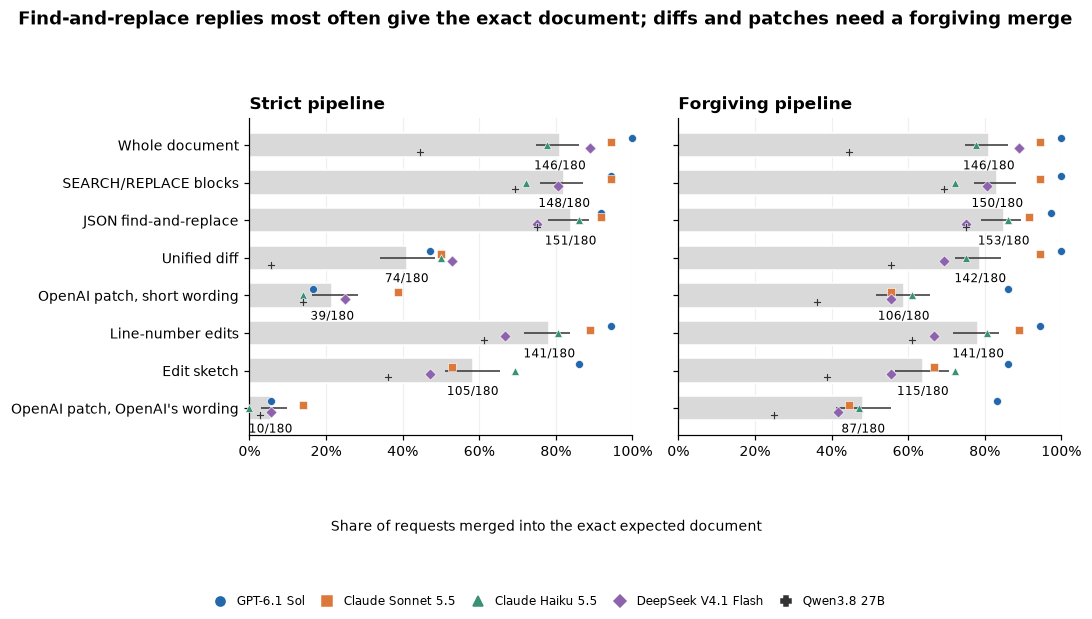

In [15]:
def fig_formats(merges, title='Exact documents by reply format and pipeline', path=None):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), sharey=True)
    table, ys = results_by_format(merges), np.arange(len(FORMATS))
    for ax, pipeline in zip(axes, ['strict', 'forgiving']):
        d = table.loc[table.pipeline.eq(pipeline)].set_index('format').reindex(FORMATS)
        ax.barh(ys, d.exact_rate, height=0.65, color=COLORS['light'], edgecolor='white')
        ax.hlines(ys, d.ci_low, d.ci_high, color=COLORS['dark'], linewidth=1)
        for y, row in zip(ys, d.itertuples()):
            ax.annotate(f'{row.exact}/{row.n}', (row.exact_rate if row.n else 0, y),
                        xytext=(0, -16), textcoords='offset points', ha='center', fontsize=8,
                        annotation_clip=False)
        selected = pipeline_rows(merges, pipeline)
        for j, model in enumerate(MODEL_ORDER):
            rates = selected.loc[selected.model.eq(model)].groupby('format').exact.mean().reindex(FORMATS)
            ax.scatter(rates, ys + (j - 2) * 0.09, color=MODEL_COLORS[model], marker=MODEL_MARKERS[model],
                       s=27, edgecolors='white', linewidths=0.4, zorder=3, clip_on=False)
        ax.set(title=pipeline.capitalize() + ' pipeline', xlim=(0, 1), yticks=ys,
               yticklabels=[FORMAT_LABELS[f] for f in FORMATS])
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(axis='y', visible=False)
    axes[0].invert_yaxis()
    fig.supxlabel('Share of requests merged into the exact expected document', y=0.13, fontsize=9)
    model_legend(fig, merges.model.unique())
    return finish_figure(fig, title, path, 'formats_by_model.png', bottom=0.18)


if not MERGES.empty:
    display(fig_formats(MERGES, title=TITLES['formats']))
    plt.close()

The markers show that the model mattered more than the format. GPT-6.1 Sol was at or near 100% in five formats: all 36
whole rewrites, all 36 SEARCH/REPLACE replies after a retry (34 without), all 36 diffs with the fuzzy method, 35 JSON
replies after a retry and 34 line-number edits. That is the test's ceiling, so for GPT-6.1 Sol the order of those
formats is not a finding. Claude Sonnet 5.5 was 89% to 94% in the top formats. The ranking is decided by the other
three models: Claude Haiku 5.5 was 78% as a whole rewrite and 86% with JSON pairs, DeepSeek V4.1 Flash 89% and 75%,
and Qwen3.8 27B 44% and 75%. For Claude Haiku 5.5 and Qwen3.8 27B, asking for JSON pairs instead of a rewrite was worth
8 and 31 points; for DeepSeek V4.1 Flash the rewrite was better by 14 points.

The two panels differ most for diffs and patches, where the forgiving pipeline nearly doubles the exact share, and not
at all for the whole rewrite, which has nothing to forgive. GPT-6.1 Sol was not helped by OpenAI's own patch format,
the one it is trained to write: under the reference rules it was exact on 6 of 36 requests with the study's wording
and 2 of 36 with OpenAI's, against 36 of 36 as a whole rewrite.

The next figure takes each format with more than one merge method and shows, for the same 180 replies, how each method
splits them into exact (green), wrong (red, hatched) and unreadable (grey, dotted) documents. Methods are listed from
strict to forgiving, then the retry pipelines, then the merge model.

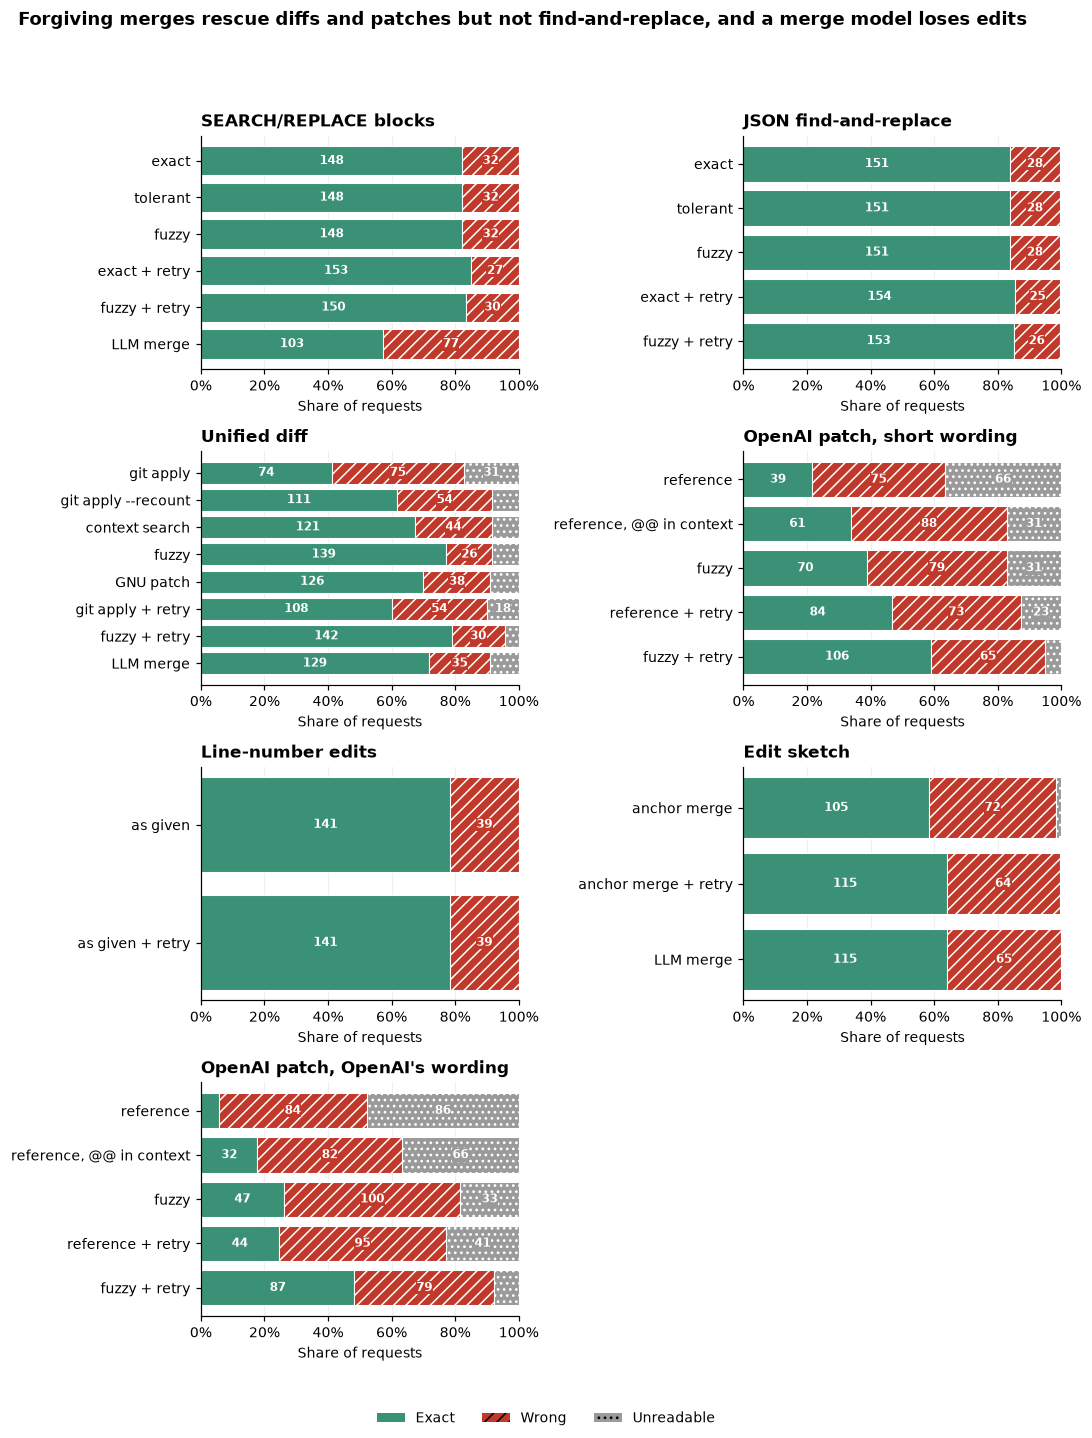

In [16]:
def fig_methods(merges, title='Merge outcomes by method', path=None):
    formats = [f for f in FORMATS if f != 'full']
    nrows = (len(formats) + 1) // 2
    fig, axes = plt.subplots(nrows, 2, figsize=(10, 3.3 * nrows), squeeze=False)
    for ax, fmt in zip(axes.flat, formats):
        d = merges.loc[merges['format'].eq(fmt)]
        methods = [m for m in METHOD_ORDER[fmt] if m in set(d.method)]
        counts = pd.crosstab(d.method, d.status).reindex(index=methods, columns=list(STATUS_COLORS), fill_value=0)
        n = counts.sum(axis=1)
        left = np.zeros(len(methods))
        for status in STATUS_COLORS:
            values = counts[status].div(n.replace(0, np.nan)).fillna(0).to_numpy()
            ax.barh(np.arange(len(methods)), values, left=left, color=STATUS_COLORS[status],
                    edgecolor='white', hatch=STATUS_HATCHES[status], linewidth=0.7)
            for i, (width, count) in enumerate(zip(values, counts[status])):
                if width >= 0.09:
                    ax.text(left[i] + width / 2, i, str(count), ha='center', va='center', color='white',
                            fontweight='bold', fontsize=8, bbox={'facecolor': STATUS_COLORS[status], 'edgecolor': 'none', 'pad': 0.3})
            left += values
        ax.set(title=FORMAT_LABELS[fmt], yticks=range(len(methods)), yticklabels=methods, xlim=(0, 1),
               xlabel='Share of requests')
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.invert_yaxis()
        ax.grid(axis='y', visible=False)
    for ax in axes.flat[len(formats):]:
        ax.set_axis_off()
    fig.legend(handles=[Patch(facecolor=STATUS_COLORS[s], hatch=STATUS_HATCHES[s], label=s.capitalize())
                        for s in STATUS_COLORS], loc='lower center', ncol=3, frameon=False)
    return finish_figure(fig, title, path, 'merge_methods.png', bottom=0.04)


if not MERGES.empty:
    display(fig_methods(MERGES, title=TITLES['methods']))
    plt.close()

For SEARCH/REPLACE and JSON the three matching rules gave identical results (148 and 151 exact): the models quoted the
document character for character. The 32 SEARCH/REPLACE failures were search texts occurring more than once (7 blocks),
search texts not in the document (10 blocks, from Claude Haiku 5.5 and Qwen3.8 27B) and, most often, edits with no
block at all, which no matching rule can rescue. Nine SEARCH/REPLACE replies were retried, and the retry turned 5 of
them into exact documents.

For diffs the merge method decided the result: from the same 180 replies, plain `git apply` produced 74 exact
documents, `git apply --recount` 111, GNU `patch` 126, context search 121 and the fuzzy method 139. Much of the gap is
one habit: a hunk's last line is usually a blank context line, models often leave it out, and the hunk is then one line
shorter than its header says. Plain `git apply` calls that a corrupt patch (in 57 of the 180 replies, 18 of them
GPT-6.1 Sol's); GNU `patch` and `--recount` accept it. A retry lifted plain `git apply` from 74 to 108, because git's
error names the hunk to fix.

For OpenAI's patch format the problem was the `@@` locator line. In prose the nearest heading is usually within the
three unchanged lines above a change, so the models named it in the `@@` line and also listed it as a context line.
OpenAI's reference rules look for the context only after the `@@` line, so the chunk cannot be placed although its
text is right (in 87% of the chunks written under OpenAI's wording the unchanged and removed lines occur exactly in the
document). Accepting a repeated `@@` line lifted the study wording from 39 to 61 exact, and the fuzzy method plus a
retry reached 106. OpenAI's own wording did worse (10 strict, 87 forgiving): its template shows an `@@` line in every
chunk, and 300 of 934 chunks repeated the heading in the context while 211 named it without its `#` marks.

The merge model was the weakest method for find-and-replace (103 exact against 148) and roughly equal to code for the
other two formats (diffs 129 against 139 for the fuzzy method; sketches 115 against 105 for the anchor merge). Of the 52
SEARCH/REPLACE replies that merged exactly in code but not through Haiku, 50 came back with edits missing; on
twenty-edit requests only 12 of 45 Haiku merges were exact. Given many short blocks and a long document, the merge
model wrote the document out and left some blocks unapplied: 14% of number changes and 10% of word changes sent to it
as SEARCH/REPLACE blocks were lost, against none through the exact match, and 2% to 4% when it merged diffs or
sketches.

The cost figure shows the median output tokens of a first reply (left, log scale, reasoning tokens included) and its
median time (right), by format and document length band. Retries and merges are counted separately in the table that
follows.

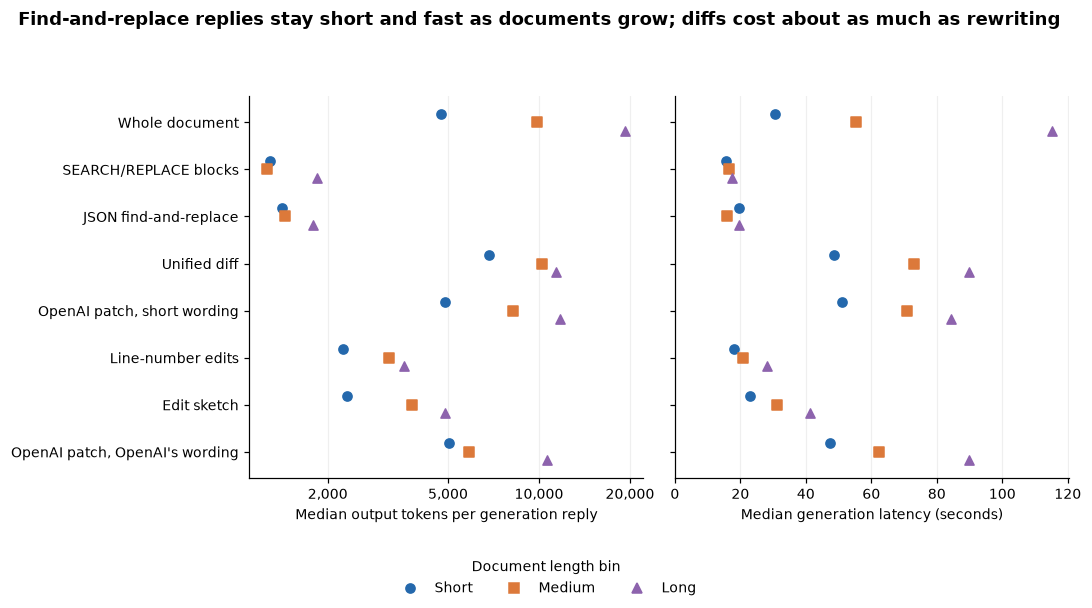

,stage,calls,input_tokens,input_tokens_missing,output_tokens,output_tokens_missing,latency_s,latency_s_missing
0,retry,439,4259144.0,0,5381058.0,0,38881.6049,0
1,merge,525,NaN,1,NaN,1,24595.7760,0


In [17]:
def spend_table(generations):
    rows = []
    for model in MODEL_ORDER:
        for stage in ['generation', 'retry', 'merge']:
            d = generations.loc[generations.model.eq(model) & generations.stage.eq(stage)]
            if d.empty:
                continue
            row = {'model': model, 'stage': stage, 'calls': len(d)}
            for col in ['input_tokens', 'output_tokens', 'list_cost_usd', 'latency_s']:
                values = pd.to_numeric(d[col], errors='coerce')
                # A partial sum must not look like a known total (e.g. Codex subscription cost).
                row[col] = values.sum() if values.notna().all() else np.nan
                row[col + '_missing'] = int(values.isna().sum())
            row['reported_list_cost_usd'] = pd.to_numeric(d.list_cost_usd, errors='coerce').sum(min_count=1)
            rows.append(row)
    return pd.DataFrame(rows)


def extra_call_totals(generations):
    rows = []
    for stage in ['retry', 'merge']:
        d = generations.loc[generations.stage.eq(stage)]
        row = {'stage': stage, 'calls': len(d)}
        for col in ['input_tokens', 'output_tokens', 'latency_s']:
            values = pd.to_numeric(d[col], errors='coerce')
            row[col] = values.sum() if values.notna().all() else np.nan
            row[col + '_missing'] = int(values.isna().sum())
        rows.append(row)
    return pd.DataFrame(rows)


def fig_cost(generations, title='Generation output and time by reply format', path=None):
    d = generations.loc[generations.stage.eq('generation')]
    medians = d.groupby(['format', 'length_bin'])[['output_tokens', 'latency_s']].median()
    fig, axes = plt.subplots(1, 2, figsize=(10, 5.5), sharey=True)
    ys = np.arange(len(FORMATS))
    for ax, measure, label in zip(axes, ['output_tokens', 'latency_s'],
                                  ['Median output tokens per generation reply', 'Median generation latency (seconds)']):
        for i, (length, color, marker) in enumerate(zip(LENGTH_ORDER, LENGTH_COLORS, LENGTH_MARKERS)):
            values = medians[measure].reindex(pd.MultiIndex.from_product([FORMATS, [length]])).to_numpy()
            if measure == 'output_tokens':
                values = np.where(values > 0, values, np.nan)
            ax.scatter(values, ys + (i - 1) * 0.18, color=color, marker=marker, s=36, clip_on=False)
        ax.set(yticks=ys, yticklabels=[FORMAT_LABELS[f] for f in FORMATS], xlabel=label)
        ax.grid(axis='y', visible=False)
    axes[0].set_xscale('log')
    lo, hi = axes[0].get_xlim()  # Autoscaled data range includes the usual plotting margin.
    axes[0].set_xticks([v for v in [1000, 2000, 5000, 10000, 20000] if lo <= v <= hi])
    axes[0].xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    axes[0].xaxis.set_minor_locator(NullLocator())
    axes[0].xaxis.set_minor_formatter(NullFormatter())
    axes[1].set_xlim(left=0)
    axes[0].invert_yaxis()
    length_legend(fig)
    return finish_figure(fig, title, path, 'output_and_time.png', bottom=0.11)


if not GENERATIONS.empty:
    GENERATION_COSTS = GENERATIONS.loc[GENERATIONS.stage.eq('generation')].copy()
    EXTRA_CALL_COSTS = extra_call_totals(GENERATIONS)
    display(fig_cost(GENERATIONS, title=TITLES['cost']))
    plt.close()
    display(EXTRA_CALL_COSTS)

Find-and-replace cost the same at every length: SEARCH/REPLACE replies took a median 1,290, 1,262 and 1,844 output
tokens and 16, 17 and 17 seconds on short, medium and long documents. The whole rewrite grew with the document, from
4,732 tokens and 31 seconds to 19,318 tokens and 115 seconds. Diffs and patches cost about as much as rewriting (a
median 6,858 to 11,350 tokens and 49 to 90 seconds for diffs), although their visible replies are much shorter (a
median 9,000 characters against 33,000): the models spent most of their tokens reasoning, counting lines and checking
context. Claude Haiku 5.5's median diff reply used about 16,000 reasoning tokens. In 15 of its 36 diff requests Qwen3.8
27B reasoned for around 17,000 tokens, listing the document line by line ("Line 144: (blank)"), and then stopped
without writing a diff; these are its 15 empty replies.

The 439 retries and 525 merges came on top of the 1,440 first replies. Only 15 of 360 find-and-replace replies needed a
retry, against 90 of 180 diffs under plain `git apply` and 133 and 167 of the patch replies.

The bundle heat maps break the exact share down by request type: a single change, six mixed changes, a rename
everywhere and twenty scattered changes. Each cell is 45 requests (9 documents by 5 models); the left map uses the
forgiving pipeline and the right the strict one.

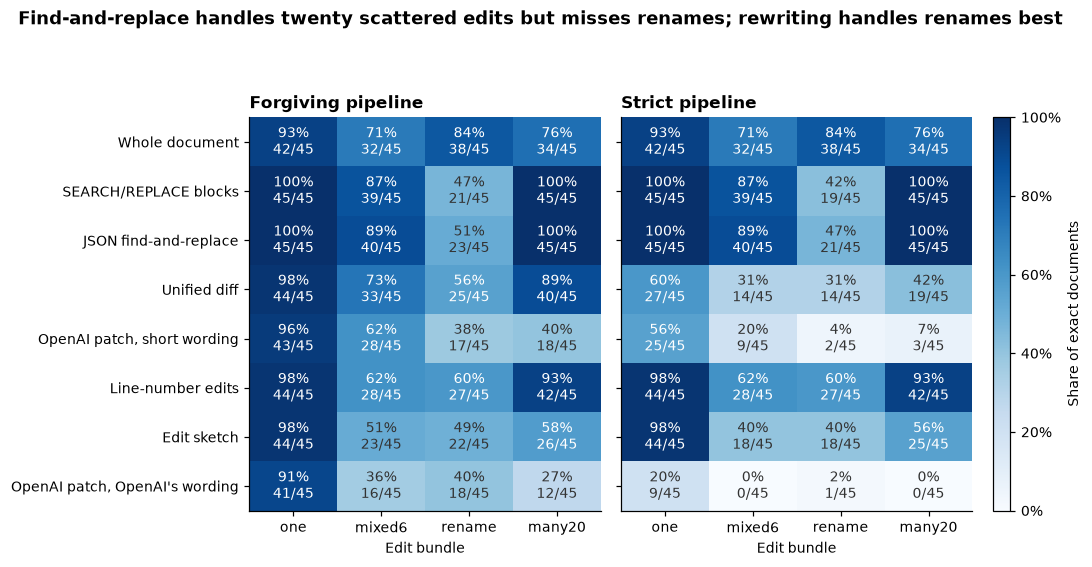

In [18]:
def fig_bundles(merges, title='Exact documents by edit bundle', path=None):
    fig, all_axes = plt.subplots(1, 3, figsize=(10, 5.2), gridspec_kw={'width_ratios': [1, 1, 0.05]})
    axes = all_axes[:2]
    axes[1].sharey(axes[0])
    axes[1].tick_params(labelleft=False)
    for ax, pipeline in zip(axes, ['forgiving', 'strict']):
        selected = pipeline_rows(merges, pipeline)
        rates = np.full((len(FORMATS), len(BUNDLES)), np.nan)
        for i, fmt in enumerate(FORMATS):
            for j, bundle in enumerate(BUNDLES):
                d = selected.loc[selected['format'].eq(fmt) & selected.bundle.eq(bundle)]
                k, n = int(d.exact.sum()), len(d)
                if n:
                    rates[i, j] = k / n
                ax.text(j, i, f'{k / n:.0%}\n{k}/{n}' if n else 'no data', ha='center', va='center',
                        color='white' if n and k / n >= 0.55 else COLORS['dark'], fontsize=9)
        im = ax.imshow(np.ma.masked_invalid(rates), cmap='Blues', vmin=0, vmax=1, aspect='auto')
        ax.set(title=pipeline.capitalize() + ' pipeline', xticks=range(len(BUNDLES)), xticklabels=BUNDLES,
               yticks=range(len(FORMATS)), yticklabels=[FORMAT_LABELS[f] for f in FORMATS], xlabel='Edit bundle')
        ax.grid(False)
    bar = fig.colorbar(im, cax=all_axes[2], format=PercentFormatter(1))
    bar.set_label('Share of exact documents')
    return finish_figure(fig, title, path, 'bundles.png')


if not MERGES.empty:
    display(fig_bundles(MERGES, title=TITLES['bundles']))
    plt.close()

Find-and-replace was perfect on single edits and twenty scattered edits (45 of 45 in both formats), 87% to 89% on six
mixed edits, and weak on renames (21 and 23 of 45). A rename means one block per occurrence, up to 39, each unique, and
models left occurrences out or quoted a bare abbreviation that occurs many times. The whole rewrite was best on renames
(38 of 45), since swapping a word throughout is easy for a model that copies well, and weakest of the top group on
twenty edits (34) and six mixed edits (32), where it left changes undone or altered untouched text. Line-number edits
did well on single and twenty-edit requests (98% and 93%) and badly on mixed edits (62%), where inserted and moved
paragraphs need the blank line the models left out.

The edit-type table counts individual edits rather than whole documents: for each format and kind of edit, the share
of edits whose own check passed, over readable replies, using the forgiving pipeline.

In [19]:
def edit_type_table(merges):
    tasks = {t['task_id']: t for t in TASKS}
    counts = Counter()
    replies = Counter()
    selected = pipeline_rows(merges, 'forgiving')
    names = ['number phrase', 'word phrase', 'sentence', 'delete', 'insert', 'move', 'rename']
    labels = {'rewrite_sentence': 'sentence', 'delete_paragraph': 'delete', 'insert_paragraph': 'insert',
              'move_paragraph': 'move', 'rename': 'rename'}
    for row in selected.loc[selected.status.ne('unreadable')].itertuples():
        checks = json.loads(row.edit_checks) if isinstance(row.edit_checks, str) else row.edit_checks
        edits = tasks[row.task_id]['edits']
        if len(checks) != len(edits):
            raise ValueError(f'edit_checks length mismatch: {row.task_id}')
        types_in_reply = set()
        for e, ok in zip(edits, checks):
            name = e['kind'] + ' phrase' if e['type'] == 'replace_phrase' else labels[e['type']]
            counts[(row.format, name, 'n')] += 1
            counts[(row.format, name, 'ok')] += int(ok)
            types_in_reply.add(name)
        replies.update((row.format, name) for name in types_in_reply)
    return pd.DataFrame([{'format': fmt, 'edit_type': name, 'edits_ok': counts[fmt, name, 'ok'],
                          'n_edits': counts[fmt, name, 'n'], 'readable_replies': replies[fmt, name],
                          'share_edits_done': counts[fmt, name, 'ok'] / counts[fmt, name, 'n']
                          if counts[fmt, name, 'n'] else np.nan}
                         for fmt in FORMATS for name in names])


if not MERGES.empty:
    EDIT_TYPE_RESULTS = edit_type_table(MERGES)
    display(EDIT_TYPE_RESULTS.style.format({'share_edits_done': '{:.1%}'}, na_rep='not available'))

,format,edit_type,edits_ok,n_edits,readable_replies,share_edits_done
0,full,number phrase,620,630,115,98.4%
1,full,word phrase,349,350,105,99.7%
2,full,sentence,45,45,45,100.0%
3,full,delete,45,45,45,100.0%
4,full,insert,45,45,45,100.0%
5,full,move,44,45,45,97.8%
6,full,rename,43,45,45,95.6%
7,search_replace,number phrase,630,630,115,100.0%
8,search_replace,word phrase,350,350,105,100.0%
9,search_replace,sentence,45,45,45,100.0%


Edit by edit, the find-and-replace formats did 100% of the phrase changes, sentence replacements, deletions and
insertions and 98% of the moves, but only about half of the rename edits (49% and 51%). The whole rewrite did 96% of
renames and at least 98% of everything else. So find-and-replace fails on one kind of edit, and it fails by omission: a
check after merging that looks for every requested new text, or for the old abbreviation, would find nearly all of its
wrong documents.

## 11. Error analysis

The failure table counts, for each format's strict method and each model, the blocks that could not be placed, by
reason, and the share of replies with at least one failed block. A failed block does not always mean a wrong
document: a reply can carry an extra block that fails harmlessly.

In [20]:
def failure_table(merges):
    rows = []
    selected = pipeline_rows(merges, 'strict')
    for fmt in FORMATS:
        for model in MODEL_ORDER:
            d = selected.loc[selected['format'].eq(fmt) & selected.model.eq(model)]
            if d.empty:
                continue
            reasons, replies, failed_replies = Counter(), Counter(), 0
            for value in d.failures:
                failures = json.loads(value) if isinstance(value, str) else value
                failed_replies += bool(failures)
                # Block 0 denotes a whole-reply parse/transport failure, counted as one failure unit.
                reasons.update(reason for block, reason in {(f['block'], f['reason']) for f in failures})
                replies.update({f['reason'] for f in failures})
            for reason in sorted(reasons) or ['(no failed blocks)']:
                rows.append({'format': fmt, 'method': MAIN_PIPELINES[fmt][0], 'model': model, 'reason': reason,
                             'failed_blocks': reasons[reason], 'replies_with_reason': replies[reason],
                             'n_replies': len(d), 'replies_with_failed_block': failed_replies,
                             'share_replies_with_failed_block': failed_replies / len(d)})
    return pd.DataFrame(rows)


if not MERGES.empty:
    FAILURE_RESULTS = failure_table(MERGES)
    display(FAILURE_RESULTS.style.format({'share_replies_with_failed_block': '{:.1%}'}))

,format,method,model,reason,failed_blocks,replies_with_reason,n_replies,replies_with_failed_block,share_replies_with_failed_block
0,full,as written,GPT-6.1 Sol,(no failed blocks),0,0,36,0,0.0%
1,full,as written,Claude Sonnet 5.5,(no failed blocks),0,0,36,0,0.0%
2,full,as written,Claude Haiku 5.5,(no failed blocks),0,0,36,0,0.0%
3,full,as written,DeepSeek V4.1 Flash,(no failed blocks),0,0,36,0,0.0%
4,full,as written,Qwen3.8 27B,(no failed blocks),0,0,36,0,0.0%
5,search_replace,exact,GPT-6.1 Sol,ambiguous,4,2,36,2,5.6%
6,search_replace,exact,Claude Sonnet 5.5,(no failed blocks),0,0,36,0,0.0%
7,search_replace,exact,Claude Haiku 5.5,ambiguous,2,1,36,2,5.6%
8,search_replace,exact,Claude Haiku 5.5,not_found,2,2,36,2,5.6%
9,search_replace,exact,DeepSeek V4.1 Flash,(no failed blocks),0,0,36,0,0.0%


Find-and-replace replies had failed blocks in 0% to 14% of replies per model, for two reasons: ambiguity and text not
found. Diff failures under plain `git apply` were mostly `corrupt_hunk` (git's "corrupt patch", the off-by-one hunk
length) and `context_mismatch`, and Qwen3.8 27B's include its 15 empty replies. Patch failures under the reference
rules were `context_mismatch` and `anchor_not_found`, the two faces of the `@@` problem. Line-number edits never failed
a block: their 39 wrong documents were all accepted by the merge, which is what makes them risky.

A common reason given for avoiding line-number formats is that models count lines badly. The next cell compares the
line number each diff hunk states with the line where its unchanged and removed lines actually start, and checks
whether each line-number edit names the lines of the edit it carries out.

,model,stage,hunks,unplaced_hunks,replies_with_no_parsed_hunks,share_exactly_right,share_within_3_lines,median_absolute_offset
0,GPT-6.1 Sol,generation,207,0,0,1.000000,1.000000,0.0
1,Claude Sonnet 5.5,generation,198,2,0,0.939394,0.989899,0.0
2,Claude Haiku 5.5,generation,180,6,0,0.783333,0.977778,0.0
3,DeepSeek V4.1 Flash,generation,248,4,0,0.931452,1.000000,0.0
4,Qwen3.8 27B,generation,101,34,15,0.990099,1.000000,0.0


,model,stage,edit_objects,matched_objects,unmatched_objects,right,share_right,share_right_matched,replies_with_no_parsed_objects
0,GPT-6.1 Sol,generation,306,306,0,306,1.000000,1.000000,0
1,Claude Sonnet 5.5,generation,305,305,0,304,0.996721,0.996721,0
2,Claude Haiku 5.5,generation,299,299,0,299,1.000000,1.000000,0
3,DeepSeek V4.1 Flash,generation,296,296,0,295,0.996622,0.996622,0
4,Qwen3.8 27B,generation,302,302,0,300,0.993377,0.993377,0


C:\Users\sandh\AppData\Local\Temp\ipykernel_61752\549121124.py:93: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, bottom, 1, 0.96 - title_height))


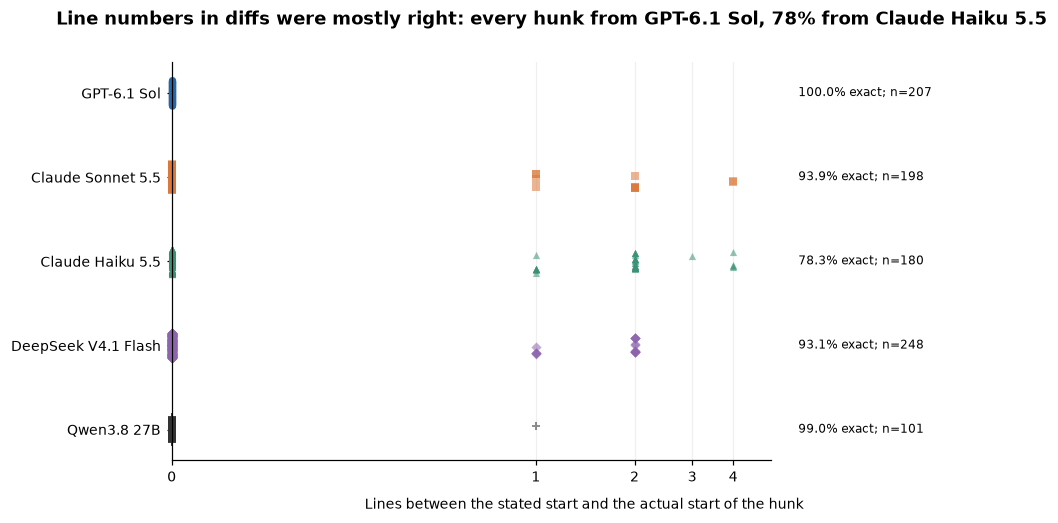

In [21]:
def line_edit_targets(task, original):
    """Semantic original-line targets used only for analysis, never for applying or retrying replies."""
    lines, targets = document_lines(original), []
    for index, e in enumerate(task['edits']):
        kind = e['type']
        if kind == 'rename':
            for i, value in enumerate(lines):
                changed = re.sub(rename_pattern(e['old']), lambda m: e['new'], value)
                if changed != value:
                    targets.append({'edit': index, 'action': 'replace', 'line': i, 'old': value,
                                    'signal': changed, 'desired': changed})
        elif kind in {'replace_phrase', 'rewrite_sentence'}:
            i = e['line']
            desired = lines[i][:e['start']] + e['new'] + lines[i][e['end']:]
            targets.append({'edit': index, 'action': 'replace', 'line': i, 'old': lines[i],
                            'signal': e['new'], 'desired': desired})
        elif kind == 'delete_paragraph':
            targets.append({'edit': index, 'action': 'delete', 'line': e['line'],
                            'old': lines[e['line']], 'signal': '', 'desired': ''})
        elif kind == 'insert_paragraph':
            targets.append({'edit': index, 'action': 'insert_after', 'line': e['line'],
                            'old': lines[e['line']], 'signal': e['new'], 'desired': e['new']})
        elif kind == 'move_paragraph':
            targets.extend([
                {'edit': index, 'action': 'delete', 'line': e['line'], 'old': lines[e['line']],
                 'signal': '', 'desired': ''},
                {'edit': index, 'action': 'insert_after', 'line': e['anchor_line'],
                 'old': lines[e['anchor_line']], 'signal': lines[e['line']], 'desired': lines[e['line']]},
            ])
    return targets


def analyse_line_object(obj, targets, lines):
    """Count unmatched objects in the denominator; do not infer off-range deletion intentions."""
    if not isinstance(obj, dict):
        return {'matched': False, 'right': False, 'requested_edits': [], 'reason': 'not an object'}
    action, text = obj.get('action'), obj.get('text', '')
    text = text if isinstance(text, str) else ''
    if action == 'insert_after':
        a = obj.get('line')
        valid = type(a) is int and 0 <= a <= len(lines)
        covered = set()
    else:
        a, b = obj.get('start'), obj.get('end')
        valid = (action in {'replace', 'delete'} and type(a) is int and type(b) is int
                 and 1 <= a <= b <= len(lines))
        covered = {i for i in range(a - 1, b) if lines[i].strip()} if valid else set()
    candidates = []
    for target in targets:
        if target['action'] != action:
            continue
        # New text identifies the intended paragraph even when the stated line is wrong.
        by_new_text = bool(target['signal']) and target['signal'] in text
        by_original = (target['old'] in text or any(lines[i] == target['old'] for i in covered))
        if by_new_text or (action != 'insert_after' and by_original):
            candidates.append(target)
    if action == 'insert_after':
        previous = next((i for i in range(a - 1, -1, -1) if lines[i].strip()), None) if valid else None
        right = bool(candidates) and valid and {t['line'] for t in candidates} == {previous}
    else:
        right = bool(candidates) and valid and covered == {t['line'] for t in candidates}
    return {'matched': bool(candidates), 'right': bool(right),
            'requested_edits': sorted({t['edit'] for t in candidates}),
            'reason': 'matched' if right else 'wrong range' if candidates else 'no text correspondence'}


def line_number_accuracy(stages=('generation',)):
    """Initial replies by default. Pass stages=('generation', 'retry') for separate retry summaries.

    Every hunk is located independently in the unchanged original. Repeated old sides use the context
    search method's nearest-position rule. Insertion-only old sides have no independently verifiable line.
    Line-edit ranges may include adjoining blank separators, but no other nonblank original lines.
    """
    tasks = {t['task_id']: t for t in TASKS}
    hunk_rows, object_rows, reply_rows = [], [], []
    sources = {'generation': GEN_RESPONSES, 'retry': RETRY_RESPONSES}
    for stage in stages:
        for (model, fmt, task_id), response in sources[stage].items():
            if fmt not in {'udiff', 'line_edits'}:
                continue
            task = tasks[task_id]
            original = DOCUMENTS[task['document']]['text']
            lines = document_lines(original)
            reply = response.get('text') or ''
            if fmt == 'udiff':
                hunks, parsed = parse_udiff(reply)
                reply_rows.append({'model': model, 'stage': stage, 'format': fmt, 'task_id': task_id,
                                   'parsed_objects': len(hunks), 'parse_failures': len(parsed.failures)})
                for h in hunks:
                    locations = sequence_locations(lines, h.old) if h.old else []
                    at = min(locations, key=lambda i: (abs(i - (h.old_start - 1)), i)) if locations else None
                    actual = at + 1 if at is not None else np.nan
                    offset = actual - h.old_start
                    hunk_rows.append({'model': model, 'stage': stage, 'task_id': task_id, 'block': h.block,
                                      'stated_line': h.old_start, 'actual_line': actual, 'offset': offset,
                                      'absolute_offset': abs(offset), 'placed': at is not None,
                                      'candidate_locations': len(locations),
                                      'reason': 'located' if locations else 'no old-side text' if not h.old else 'old side not found'})
            else:
                blocks, parsed = parse_json_edits(reply)
                targets = line_edit_targets(task, original)
                reply_rows.append({'model': model, 'stage': stage, 'format': fmt, 'task_id': task_id,
                                   'parsed_objects': len(blocks), 'parse_failures': len(parsed.failures)})
                for block, obj in blocks:
                    object_rows.append({'model': model, 'stage': stage, 'task_id': task_id, 'block': block,
                                        'object': canonical(obj), **analyse_line_object(obj, targets, lines)})
    hunks = pd.DataFrame(hunk_rows, columns=['model', 'stage', 'task_id', 'block', 'stated_line', 'actual_line',
                                          'offset', 'absolute_offset', 'placed', 'candidate_locations', 'reason'])
    objects = pd.DataFrame(object_rows, columns=['model', 'stage', 'task_id', 'block', 'object', 'matched',
                                               'right', 'requested_edits', 'reason'])
    replies = pd.DataFrame(reply_rows, columns=['model', 'stage', 'format', 'task_id', 'parsed_objects', 'parse_failures'])
    diff_summary, line_summary = [], []
    for model in MODEL_ORDER:
        for stage in stages:
            dh = hunks.loc[hunks.model.eq(model) & hunks.stage.eq(stage)]
            do = objects.loc[objects.model.eq(model) & objects.stage.eq(stage)]
            dr = replies.loc[replies.model.eq(model) & replies.stage.eq(stage)]
            if dr.loc[dr['format'].eq('udiff')].shape[0]:
                placed = dh.loc[dh.placed.eq(True), 'absolute_offset']
                diff_summary.append({'model': model, 'stage': stage, 'hunks': len(placed),
                                     'unplaced_hunks': len(dh) - len(placed),
                                     'replies_with_no_parsed_hunks': int(dr.loc[dr['format'].eq('udiff'), 'parsed_objects'].eq(0).sum()),
                                     'share_exactly_right': placed.eq(0).mean() if len(placed) else np.nan,
                                     'share_within_3_lines': placed.le(3).mean() if len(placed) else np.nan,
                                     'median_absolute_offset': placed.median()})
            if dr.loc[dr['format'].eq('line_edits')].shape[0]:
                matched = do.loc[do.matched.eq(True)]
                line_summary.append({'model': model, 'stage': stage, 'edit_objects': len(do),
                                     'matched_objects': len(matched), 'unmatched_objects': len(do) - len(matched),
                                     'right': int(do.right.sum()),
                                     'share_right': do.right.mean() if len(do) else np.nan,
                                     'share_right_matched': matched.right.mean() if len(matched) else np.nan,
                                     'replies_with_no_parsed_objects': int(dr.loc[dr['format'].eq('line_edits'), 'parsed_objects'].eq(0).sum())})
    return {'hunks': hunks, 'edit_objects': objects, 'reply_counts': replies,
            'udiff': pd.DataFrame(diff_summary), 'line_edits': pd.DataFrame(line_summary)}


def fig_line_numbers(accuracy, title='Stated line offsets in unified diff replies', path=None):
    fig, (ax, text_ax) = plt.subplots(1, 2, figsize=(10, 4.7), sharey=True,
                                      gridspec_kw={'width_ratios': [3.6, 1.4], 'wspace': 0.05})
    text_ax.set_axis_off()
    placed = accuracy['hunks'].loc[accuracy['hunks'].placed.eq(True)]
    for i, model in enumerate(MODEL_ORDER):
        offsets = placed.loc[placed.model.eq(model), 'absolute_offset'].to_numpy(dtype=float)
        # Deterministic vertical spread, no random state or dependence on observed scores.
        jitter = np.linspace(-0.15, 0.15, len(offsets)) if len(offsets) else []
        ax.scatter(offsets, i + np.asarray(jitter), color=MODEL_COLORS[model], marker=MODEL_MARKERS[model],
                   s=22, alpha=0.55, linewidths=0, clip_on=False)
        label = f'{(offsets == 0).mean():.1%} exact; n={len(offsets)}' if len(offsets) else 'no placeable hunks'
        text_ax.text(0.03, i, label, transform=text_ax.get_yaxis_transform(),
                     ha='left', va='center', fontsize=8)
    ax.set_xscale('symlog', linthresh=1)
    maximum = float(placed.absolute_offset.max()) if not placed.empty else 0
    ax.set(yticks=range(len(MODEL_ORDER)), yticklabels=MODEL_ORDER,
           xlim=(0, max(3, maximum * 1.3)))
    ax.set_xticks(list(range(int(maximum) + 1)) if maximum <= 10 else
                  [v for v in [0, 1, 2, 5, 10, 20, 50, 100] if v <= maximum])
    ax.xaxis.set_major_formatter(StrMethodFormatter('{x:.0f}'))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_minor_formatter(NullFormatter())
    fig.supxlabel('Lines between the stated start and the actual start of the hunk', fontsize=9)
    ax.invert_yaxis()
    ax.grid(axis='y', visible=False)
    return finish_figure(fig, title, path, 'line_numbers.png', bottom=0.06)


if not GENERATIONS.empty:
    LINE_NUMBER_RESULTS = line_number_accuracy()
    display(LINE_NUMBER_RESULTS['udiff'])
    display(LINE_NUMBER_RESULTS['line_edits'])
    display(fig_line_numbers(LINE_NUMBER_RESULTS, title=TITLES['line_numbers']))
    plt.close()

Here the models mostly counted correctly. The stated start line was exact for all 207 of GPT-6.1 Sol's hunks, 94% of
Claude Sonnet 5.5's, 93% of DeepSeek V4.1 Flash's, 99% of the 101 hunks Qwen3.8 27B wrote (its other replies were
empty or unparseable) and 78% of Claude Haiku 5.5's, and at least 98% were within three lines for every model. In
line-number edits 99% to 100% of edit objects named the right lines. With one paragraph per line even the longest
document has 537 lines; files with many short lines, such as code, may be harder. In these documents the diff failures
came from hunk lengths and blank lines, not from line numbers.

Collateral changes are paragraphs the request did not touch that came back altered, missing or added. The figure
shows, for readable merged documents, how often there was any (left) and how many paragraphs when there was (right),
for whole rewrites, the three merge-model pipelines and the deterministic forgiving methods pooled, by length band.

,method,length_bin,n_readable,n_with_collateral,share_with_collateral_readable,mean_collateral_paragraphs_when_any
0,Whole document,short,60,6,0.100000,2.333333
1,Whole document,medium,60,7,0.116667,2.857143
2,Whole document,long,60,12,0.200000,26.250000
3,SEARCH/REPLACE blocks: LLM merge,short,60,5,0.083333,1.000000
4,SEARCH/REPLACE blocks: LLM merge,medium,60,6,0.100000,1.166667
5,SEARCH/REPLACE blocks: LLM merge,long,60,13,0.216667,1.230769
6,Unified diff: LLM merge,short,57,4,0.070175,2.250000
7,Unified diff: LLM merge,medium,57,7,0.122807,6.285714
8,Unified diff: LLM merge,long,50,5,0.100000,45.600000
9,Edit sketch: LLM merge,short,60,13,0.216667,1.846154


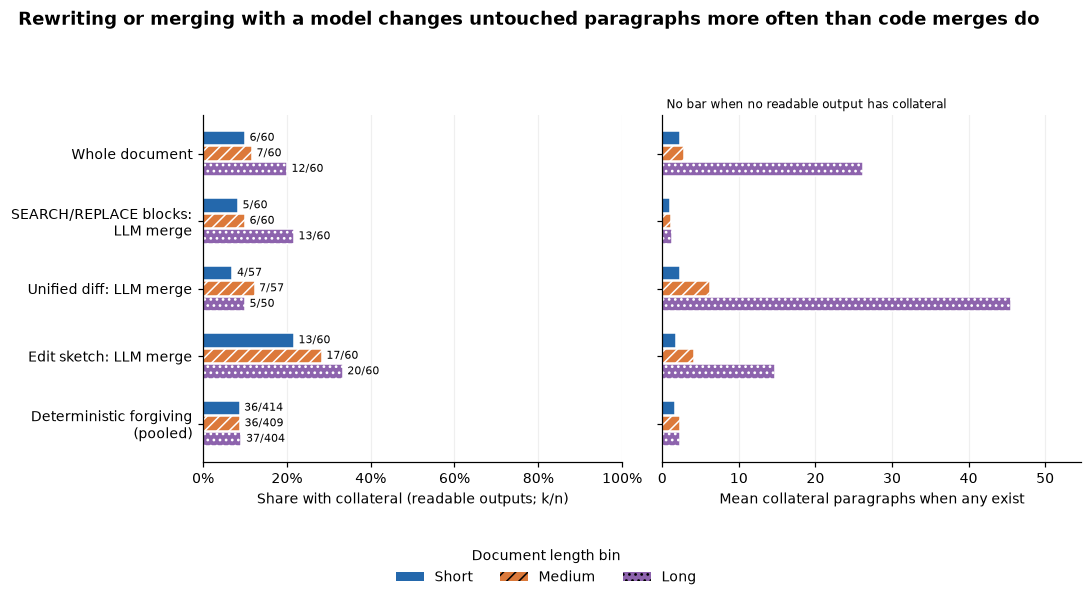

In [22]:
def collateral_table(merges):
    selections = [('Whole document', merges.loc[merges['format'].eq('full') & merges.method.eq('as written')])]
    selections += [(FORMAT_LABELS[fmt] + ': LLM merge', merges.loc[merges['format'].eq(fmt) & merges.method.eq('LLM merge')])
                   for fmt in FORMATS if merges.loc[merges['format'].eq(fmt)].method.eq('LLM merge').any()]
    forgiving = pipeline_rows(merges, 'forgiving')
    selections.append(('Deterministic forgiving (pooled)', forgiving.loc[forgiving['format'].ne('full')]))
    rows = []
    for method, selected in selections:
        for length in LENGTH_ORDER:
            d = selected.loc[selected.length_bin.eq(length) & selected.status.ne('unreadable')]
            positive = d.loc[d.collateral_paragraphs.gt(0), 'collateral_paragraphs']
            rows.append({'method': method, 'length_bin': length, 'n_readable': len(d), 'n_with_collateral': len(positive),
                         'share_with_collateral_readable': len(positive) / len(d) if len(d) else np.nan,
                         'mean_collateral_paragraphs_when_any': positive.mean()})
    return pd.DataFrame(rows)


def fig_collateral(merges, title='Collateral changes on readable merged documents', path=None):
    table = collateral_table(merges)
    methods = list(table.method.drop_duplicates())
    ys = np.arange(len(methods))
    fig, axes = plt.subplots(1, 2, figsize=(10, 5.4), sharey=True)
    for i, (length, color, hatch) in enumerate(zip(LENGTH_ORDER, LENGTH_COLORS, LENGTH_HATCHES)):
        d = table.loc[table.length_bin.eq(length)].set_index('method').reindex(methods)
        axes[0].barh(ys + (i - 1) * 0.23, d.share_with_collateral_readable, height=0.21,
                     color=color, hatch=hatch, edgecolor='white')
        axes[1].barh(ys + (i - 1) * 0.23, d.mean_collateral_paragraphs_when_any, height=0.21,
                     color=color, hatch=hatch, edgecolor='white')
        for y, row in zip(ys + (i - 1) * 0.23, d.itertuples()):
            axes[0].annotate(f'{row.n_with_collateral}/{row.n_readable}',
                             (row.share_with_collateral_readable if row.n_readable else 0, y),
                             xytext=(3, 0), textcoords='offset points', va='center', fontsize=7, annotation_clip=False)
    labels = [textwrap.fill(m, 24) for m in methods]
    for ax in axes:
        ax.set(yticks=ys, yticklabels=labels)
        ax.grid(axis='y', visible=False)
    axes[0].set(xlim=(0, 1), xlabel='Share with collateral (readable outputs; k/n)')
    axes[0].xaxis.set_major_formatter(PercentFormatter(1))
    axes[1].set(xlim=(0, max(1, table.mean_collateral_paragraphs_when_any.max() * 1.2)
                          if table.mean_collateral_paragraphs_when_any.notna().any() else 1),
                xlabel='Mean collateral paragraphs when any exist')
    axes[1].text(0.01, 1.02, 'No bar when no readable output has collateral', transform=axes[1].transAxes, fontsize=8)
    axes[0].invert_yaxis()
    fig.legend(handles=[Patch(facecolor=c, hatch=h, label=length.capitalize())
                        for length, c, h in zip(LENGTH_ORDER, LENGTH_COLORS, LENGTH_HATCHES)],
               loc='lower center', ncol=3, frameon=False, title='Document length bin')
    return finish_figure(fig, title, path, 'collateral.png', bottom=0.12)


if not MERGES.empty:
    COLLATERAL_RESULTS = collateral_table(MERGES)
    display(COLLATERAL_RESULTS)
    display(fig_collateral(MERGES, title=TITLES['collateral']))
    plt.close()

Code merges changed untouched text in about 9% of readable documents at every length, usually one or two paragraphs (a
paragraph run into its neighbour for lack of a blank line, a paragraph deleted along with a neighbour). Whole rewrites
did so in 10% of short documents and 20% of long ones, and on long documents the damage averaged 26 paragraphs when
there was any: Qwen3.8 27B straightened the curly quotation marks throughout (20 of its 36 rewrites altered untouched
text, against 0 to 3 of 36 for the other models). The merge model did the same kind of damage, most of all to
sketches: 33% of its merged sketches of long documents had collateral changes.

### Worked examples

The examples below were chosen to show each kind of outcome: an end-to-end merge with a retry, a typical success, and
the main failure kinds, most of them silent. Each is identified by model, format, request and merge method; the helper
functions defined next print the instructions, the reply, any merge failures, the score and a diff between the
expected and merged documents. The text after each example says how common its behaviour was.

In [23]:
def find_cases(**filters):
    d = MERGES.copy()
    for key, value in filters.items():
        key = 'format' if key == 'fmt' else key
        if key == 'reason':
            d = d.loc[d.failures.str.contains(str(value), case=False, regex=False, na=False)]
        elif key == 'collateral':
            d = d.loc[d.collateral_paragraphs.eq(0) if value is False else
                      d.collateral_paragraphs.gt(0 if value is True else float(value))]
        elif key in {'status', 'format', 'method', 'model', 'bundle', 'task_id'}:
            values = value if isinstance(value, (list, tuple, set)) else [value]
            d = d.loc[d[key].isin(values)]
        else:
            raise ValueError(f'Unknown case filter: {key}')
    return d.sort_values(['task_id', 'format', 'method', 'model'], kind='stable').reset_index(drop=True)


def case(model, fmt, task_id, method):
    rows = find_cases(model=model, fmt=fmt, task_id=task_id, method=method)
    if len(rows) != 1:
        raise ValueError(f'Expected one scored case, found {len(rows)}: {(model, fmt, task_id, method)}')
    row = rows.iloc[0]
    task = next(t for t in TASKS if t['task_id'] == task_id)
    original = DOCUMENTS[task['document']]['text']
    expected = dict(expected_answers(task))[row.matched_answer]
    identity = (model, fmt, task_id)
    generation = GEN_RESPONSES[identity]
    used = generation if row.reply_stage == 'generation' else (
        RETRY_RESPONSES[identity] if row.reply_stage == 'retry' else MERGE_RESPONSES[identity])
    base_method = method.removesuffix(' + retry')
    applier = ((lambda o, r: apply_full(o, r, 'merged_document')) if row.reply_stage == 'merge' else
               APPLIERS[fmt][MAIN_PIPELINES[fmt][0] if method == 'LLM merge' else base_method])
    result = response_application(original, used, applier)
    merged = result.text
    diff = list(difflib.unified_diff(expected.splitlines(), (merged or '').splitlines(),
                                     fromfile='expected', tofile='merged', n=3, lineterm=''))
    wrapped = [part for line in diff for part in (textwrap.wrap(line, width=110, replace_whitespace=False,
                                                               drop_whitespace=False) or [''])]
    if len(wrapped) > 60:
        wrapped = wrapped[:59] + [f'... diff truncated ({len(wrapped)} wrapped lines in full)']
    replies_used = {'generation': generation.get('text') or ''}
    if row.reply_stage != 'generation':
        replies_used[row.reply_stage] = used.get('text') or ''
    first_result, retry_message = None, None
    if method.endswith(' + retry'):
        first_result = response_application(original, generation, APPLIERS[fmt][STRICT[fmt]])
        if row.reply_stage == 'retry':
            retry_request = next(job['request'] for job in RETRY_JOBS if job['id'] == identity)
            prompt, original_prompt = retry_request['prompt'], make_prompt(task, fmt)
            retry_message = prompt[len(original_prompt):] if prompt.startswith(original_prompt) else prompt
    return {'model': model, 'format': fmt, 'task_id': task_id, 'method': method,
            'instructions': task['instructions'], 'raw_reply': generation.get('text') or '',
            'retry_reply': (RETRY_RESPONSES.get(identity) or {}).get('text'),
            'merge_reply': (MERGE_RESPONSES.get(identity) or {}).get('text') if row.reply_stage == 'merge' else None,
            'first_failures': first_result.failures if first_result is not None else [],
            'first_notes': first_result.notes if first_result is not None else [],
            'retry_message': retry_message,
            'replies_used': replies_used, 'failures': result.failures, 'notes': result.notes,
            'score': row.to_dict(), 'expected': expected, 'got': merged, 'original': original,
            'diff': '\n'.join(wrapped), 'diff_truncated': len(diff) > 0 and len(wrapped) == 60 and wrapped[-1].startswith('...')}


def fenced(text, language='text'):
    fence = '`' * max(3, max((len(m.group()) + 1 for m in re.finditer(r'`+', text)), default=3))
    return fence + language + '\n' + text + '\n' + fence


def show_case(model, fmt, task_id, method):
    item = case(model, fmt, task_id, method)
    row = item['score']
    parts = [f'### {task_id}: {model}, {FORMAT_LABELS[fmt]}, {method}', item['instructions'],
             f'Status: {row["status"]}; edits completed {row["edits_ok"]}/{row["n_edits"]}; '
             f'failed blocks {row["n_failed"]}; reply used: {row["reply_stage"]}.']
    for stage, raw in item['replies_used'].items():
        if stage == 'retry':
            parts.extend(['First application failures and notes:', fenced(json.dumps(
                {'failures': item['first_failures'], 'notes': item['first_notes']}, ensure_ascii=False, indent=2)),
                'Corrective message received by the model (after the original prompt):',
                fenced(item['retry_message'])])
        parts.extend([f'{stage.capitalize()} reply ({len(raw):,} characters' +
                      ('; first 2,500 shown):' if len(raw) > 2500 else '):'), fenced(raw[:2500])])
    if item['failures'] or item['notes']:
        parts.extend(['Application failures and notes:', fenced(json.dumps(
            {'failures': item['failures'], 'notes': item['notes']}, ensure_ascii=False, indent=2))])
    parts.extend([f'Final status: {row["status"]}; edits completed {row["edits_ok"]}/{row["n_edits"]}.',
                  'Expected versus merged (up to 60 wrapped lines):', fenced(item['diff'] or '(No differences.)', 'diff')])
    markdown = Markdown('\n\n'.join(parts))
    display(markdown)
    return markdown


def highlighted_lines(text, flags, width=37):
    """Wrap without losing character positions, so highlighting follows the exact differing span."""
    output, position = [], 0
    for raw in text.split('\n'):
        start = 0
        if not raw:
            output.append([])
        while start < len(raw):
            end = min(len(raw), start + width)
            if end < len(raw):
                space = raw.rfind(' ', start + width // 2, end)
                if space != -1:
                    end = space + 1
            value, mask = raw[start:end], flags[position + start:position + end]
            spans, left = [], 0
            while left < len(value):
                right = left + 1
                while right < len(value) and mask[right] == mask[left]:
                    right += 1
                spans.append((left, value[left:right], bool(mask[left])))
                left = right
            output.append(spans)
            start = end
        position += len(raw) + 1
    return output


def fig_case_panel(cases, path, title='Selected document editing examples'):
    if not cases:
        raise ValueError('fig_case_panel needs at least one case.')
    prepared = []
    for item in cases:
        expected, got = item['expected'].expandtabs(4), item['got'].expandtabs(4)
        exp_mask, got_mask = [False] * len(expected), [False] * len(got)
        for tag, a, b, c, d in difflib.SequenceMatcher(None, expected, got, autojunk=False).get_opcodes():
            if tag != 'equal':
                exp_mask[a:b], got_mask[c:d] = [True] * (b - a), [True] * (d - c)
        right = ('Expected:\n' + expected + '\n\nMerged:\n' + got)
        mask = [False] * len('Expected:\n') + exp_mask + [False] * len('\n\nMerged:\n') + got_mask
        columns = [highlighted_lines(item['input'].expandtabs(4), [False] * len(item['input'].expandtabs(4))),
                   highlighted_lines(item['reply'].expandtabs(4), [False] * len(item['reply'].expandtabs(4))),
                   highlighted_lines(right, mask)]
        prepared.append((item['label'], columns, max(map(len, columns))))
    heights = [max(2.0, n * 0.16 + 0.65) for _, _, n in prepared]
    fig, axes = plt.subplots(len(cases), 3, figsize=(11, sum(heights) + 0.5), squeeze=False, dpi=150,
                             gridspec_kw={'height_ratios': heights})
    for row_axes, (label, _, _) in zip(axes, prepared):
        for i, (ax, heading) in enumerate(zip(row_axes, ['Instruction / input', 'Model reply', 'Expected / merged'])):
            ax.set_axis_off()
            ax.set(xlim=(0, 1), ylim=(0, 1))
            ax.set_title((textwrap.fill(label, 39) + '\n' if i == 0 else '') + heading, fontsize=9)
    # Lay out first, then measure the font on the final axes. Character spans must join exactly.
    wrapped_title = textwrap.fill(title, width=int(fig.get_figwidth() * 11))
    fig.suptitle(wrapped_title, x=0.02, ha='left', fontsize=12, fontweight='bold')
    title_height = (wrapped_title.count('\n') + 1) * 0.23 / fig.get_figheight()
    fig.tight_layout(rect=(0, 0, 1, 0.96 - title_height))
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    font = FontProperties(family='monospace', size=8)
    glyph_width = renderer.get_text_width_height_descent('M', font, ismath=False)[0]
    text_height = renderer.get_text_width_height_descent('Mg', font, ismath=False)[1]
    for row_axes, (label, columns, n) in zip(axes, prepared):
        for ax, lines in zip(row_axes, columns):
            extent = ax.get_window_extent(renderer)
            step, dx = 0.90 / max(n, 1), glyph_width / extent.width
            ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes,
                                       facecolor='#f7f7f7', edgecolor=COLORS['light']))
            for j, spans in enumerate(lines):
                y = 0.96 - j * step
                for left, value, changed in spans:
                    x = 0.02 + left * dx
                    ax.text(x, y, value, fontproperties=font, va='top', transform=ax.transAxes, parse_math=False,
                            bbox={'facecolor': '#f6d5ce', 'edgecolor': 'none', 'pad': 0.1} if changed else None)
                    if changed:
                        ax.plot([x, x + len(value) * dx], [y - (text_height + 1.5) / extent.height] * 2,
                                color=COLORS['dark'], linewidth=0.8, transform=ax.transAxes)
    return finish_figure(fig, title, path, 'case_panel.png', layout=False)


def first_differing_lines(item):
    """Return the first unequal expected/merged line pair, before display truncation."""
    expected, got = item['expected'].splitlines(), (item['got'] or '').splitlines()
    for tag, a, b, c, d in difflib.SequenceMatcher(None, expected, got, autojunk=False).get_opcodes():
        if tag != 'equal':
            return (expected[a] if a < b else '', got[c] if c < d else '')
    return '', ''


def difference_excerpt(expected, got, radius=30):
    """Keep about 60 characters around the first mismatch in each line."""
    first = next((op for op in difflib.SequenceMatcher(None, expected, got, autojunk=False).get_opcodes()
                  if op[0] != 'equal'), None)
    if first is None:
        return expected[:2 * radius], got[:2 * radius]
    _, a, b, c, d = first
    def clip(text, start):
        lo, hi = max(0, start - radius), min(len(text), start + radius)
        return ('…' if lo else '') + text[lo:hi] + ('…' if hi < len(text) else '')
    return clip(expected, a), clip(got, c)


def character_change_counts(item):
    """Count all deviations from the expected document, pairing changed lines before characters."""
    counts = {'Curly to straight double quote': 0, 'Curly to straight single quote': 0, 'Other': 0}
    exp, got = item['expected'].splitlines(keepends=True), (item['got'] or '').splitlines(keepends=True)
    for tag, a, b, c, d in difflib.SequenceMatcher(None, exp, got, autojunk=False).get_opcodes():
        if tag == 'equal':
            continue
        left, right = ''.join(exp[a:b]), ''.join(got[c:d])
        for kind, i, j, k, l in difflib.SequenceMatcher(None, left, right, autojunk=False).get_opcodes():
            if kind == 'equal':
                continue
            old, new = left[i:j], right[k:l]
            for offset in range(max(len(old), len(new))):
                x, y = old[offset:offset + 1], new[offset:offset + 1]
                label = ('Curly to straight double quote' if x in {'“', '”'} and y == '"' else
                         'Curly to straight single quote' if x in {'‘', '’'} and y == "'" else 'Other')
                counts[label] += 1
    return pd.DataFrame([{'Change from expected text': label, 'Characters': count} for label, count in counts.items()])


def uncovered_rename_lines(item):
    task = next(t for t in TASKS if t['task_id'] == item['task_id'])
    edit = next(e for e in task['edits'] if e['type'] == 'rename')
    blocks, _ = parse_search(item['raw_reply'])
    covered = []
    for _, block in blocks:
        if block['old']:
            covered.extend((m.start(), m.start() + len(block['old']))
                           for m in re.finditer(re.escape(block['old']), item['original']))
    rows, offset = [], 0
    for i, line in enumerate(item['original'].splitlines(keepends=True), 1):
        occurrences = list(re.finditer(rename_pattern(edit['old']), line))
        missing = [m for m in occurrences if not any(a <= offset + m.start() and offset + m.end() <= b
                                                    for a, b in covered)]
        if missing:
            rows.append({'Original line': i, 'Uncovered occurrences': len(missing), 'Original text': line.rstrip('\r\n')})
        offset += len(line)
    return pd.DataFrame(rows)


def repeated_sketch_anchor(item):
    """Select the first segment whose literal opening anchor has multiple original locations."""
    raw, _ = unwrap(item['raw_reply'])
    segments, current = [], []
    for line in raw.splitlines():
        if SKIP_MARKER.match(line):
            if any(s.strip() for s in current):
                segments.append([s for s in current if s.strip()])
            current = []
        else:
            current.append(line)
    if any(s.strip() for s in current):
        segments.append([s for s in current if s.strip()])
    for index, segment in enumerate(segments, 1):
        locations = [i for i, line in enumerate(item['original'].splitlines(), 1) if line == segment[0]]
        if len(locations) > 1:
            return {'segment': index, 'anchor': segment[0], 'original_lines': locations, 'lines': segment}
    raise ValueError('This sketch has no repeated first anchor line.')


def silent_error_panel_items(items):
    labels = ['Whole document (Qwen3.8 27B)', 'Edit sketch, anchor merge (GPT-6.1 Sol)',
              "SEARCH/REPLACE, LLM merge (Claude Haiku 5.5 merging GPT-6.1 Sol's reply)"]
    panels = []
    for item, label in zip(items, labels):
        expected, got = difference_excerpt(*first_differing_lines(item))
        input_text = item['instructions']
        if item['format'] == 'full':
            reply = got  # This line is taken from the parsed whole-document reply.
        elif item['format'] == 'sketch':
            anchor = repeated_sketch_anchor(item)
            input_text = ('First anchor in segment ' + str(anchor['segment']) + ':\n' + anchor['anchor'] +
                          '\nOriginal lines: ' + ', '.join(map(str, anchor['original_lines'])))
            reply = '\n'.join(anchor['lines'][:2])
        else:
            reply = item['raw_reply']
        panels.append({'label': label, 'input': input_text[:230], 'reply': reply[:230],
                       'expected': expected, 'got': got or '(this paragraph is missing from the merged document)'})
    return panels

#### A diff rejected, explained and fixed

GPT-6.1 Sol's diff for the single change in the Coast Guard notice (`2026-21949_one`) has the right line number and
the right text, but its last blank context line is missing, so the hunk header promises 7 old lines and the hunk has 6.

In [24]:
if not MERGES.empty:
    show_case('GPT-6.1 Sol', 'udiff', '2026-21949_one', 'git apply + retry')

### 2026-21949_one: GPT-6.1 Sol, Unified diff, git apply + retry

1. In the paragraph that begins "This proposed rule will not call for a", change "of 1995 (44" to "of 2000 (44".

Status: exact; edits completed 1/1; failed blocks 0; reply used: retry.

Generation reply (413 characters):

```text
--- a/document.md
+++ b/document.md
@@ -68,7 +68,7 @@
 
 ### B. Collection of Information
 
-This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 1995 (44 U.S.C. 3501-3520).
+This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520).
 
 ### C. Federalism and Indian Tribal Governments

```

First application failures and notes:

```text
{
  "failures": [
    {
      "block": 1,
      "reason": "corrupt_hunk",
      "detail": "error: corrupt patch at line 11"
    }
  ],
  "notes": [
    "git version 2.45.1.windows.1",
    "fatal_diff_retried_per_hunk"
  ]
}
```

Corrective message received by the model (after the original prompt):

```text


Your previous reply was:
<previous_reply>
--- a/document.md
+++ b/document.md
@@ -68,7 +68,7 @@
 
 ### B. Collection of Information
 
-This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 1995 (44 U.S.C. 3501-3520).
+This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520).
 
 ### C. Federalism and Indian Tribal Governments

</previous_reply>

It could not be applied to the document:
Block 1: error: corrupt patch at line 11

Reply again with the complete set of edits in the same format, corrected. The edits will be applied to the original document.
```

Retry reply (415 characters):

```text
--- a/document.md
+++ b/document.md
@@ -68,7 +68,7 @@
 
 ### B. Collection of Information
 
-This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 1995 (44 U.S.C. 3501-3520).
+This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520).
 
 ### C. Federalism and Indian Tribal Governments
 

```

Application failures and notes:

```text
{
  "failures": [],
  "notes": [
    "git version 2.45.1.windows.1"
  ]
}
```

Final status: exact; edits completed 1/1.

Expected versus merged (up to 60 wrapped lines):

```diff
(No differences.)
```

Plain `git apply` replied `error: corrupt patch at line 11` and applied nothing (unreadable). The retry prompt repeated
the request, quoted the reply and gave that error line; the second reply was the same diff with the missing blank
context line added, and `git apply` accepted it. The fuzzy method, which ignores header counts, merged the first reply
exactly, as it did all 36 of GPT-6.1 Sol's diffs.

#### Twenty edits in a 12,762-word document

The typical success of the find-and-replace formats: twenty phrase changes across the OPM rule (`2026-22093_many20`).

In [25]:
if not MERGES.empty:
    show_case('GPT-6.1 Sol', 'search_replace', '2026-22093_many20', 'exact')
    REPLY_LENGTHS = []
    for fmt in ['search_replace', 'full']:
        response = GEN_RESPONSES[('GPT-6.1 Sol', fmt, '2026-22093_many20')]
        generation = GENERATIONS.loc[GENERATIONS.model.eq('GPT-6.1 Sol') & GENERATIONS['format'].eq(fmt) &
                                     GENERATIONS.task_id.eq('2026-22093_many20') & GENERATIONS.stage.eq('generation')].iloc[0]
        REPLY_LENGTHS.append({'Reply format': FORMAT_LABELS[fmt], 'Characters': len(response['text']),
                             'Output tokens': generation.output_tokens})
    display(pd.DataFrame(REPLY_LENGTHS))

### 2026-22093_many20: GPT-6.1 Sol, SEARCH/REPLACE blocks, exact

1. In the paragraph that begins "The Civil Service Reform Act (CSRA) of 1978", change "Government. Pursuant to" to "Government. Under".
2. In the paragraph that begins "On July 2, 2026, OPM published a proposed", change "proposed to: (1)" to "proposed to: (3)".
3. In the paragraph that begins "In response to the proposed rule, OPM received", change "during the 30-day" to "during the 35-day".
4. In the paragraph that begins "Comments 0002 and 0005 expressed broad opposition to", change "0002 argued the rule lacks the" to "0004 argued the rule lacks the".
5. In the paragraph that begins "Comment 0006 recommended that the final rule delineate", change "conflation. Comment 0006" to "conflation. Comment 0013".
6. In the paragraph that begins "Comments 0003, 0005, and 0002 raised concerns about", change "benefits of additional" to "benefits of more".
7. In the paragraph that begins "The Expected Impact section of this preamble addresses", change "of 2010 performance" to "of 2018 performance".
8. In the paragraph that begins "OPM has considered these comments carefully and does", change "planning (§ 250.205(b)(2))," to "planning (§ 250.205(b)(8)),".
9. In the paragraph that begins "Finally, OPM notes that Annual Staffing Plans must", change "to comment 0009's" to "to comment 0013's".
10. In the paragraph that begins "Comment 0010 expressed general support for the proposed rule and", change "are finalized; (2)" to "are finalized; (6)".
11. In the paragraph that begins "Agencies must obtain OPM's approval before appointing a", change "U.S.C. 2301 (merit" to "U.S.C. 2304 (merit".
12. In the paragraph that begins "Recommendation (5) is outside the scope of this", change "5 U.S.C. 3341" to "11 U.S.C. 3341".
13. In the paragraph that begins "In 2026, after serious consideration, OPM decided to", change "actionable insights sufficient" to "actionable insights enough".
14. In the paragraph that begins "Commenters contended that the proposed survey items do", change "the statute regarding" to "the statute about".
15. In the paragraph that begins "As to the technical concerns about item wording", change "determine that additional" to "determine that more".
16. In the paragraph that begins "In fact, it was this need for customization", change "years prior to" to "years before".
17. In the paragraph that begins "This final rule affects Federal agencies subject to", change "of approximately $15,630" to "of about $15,630".
18. In the paragraph that begins "OPM has also estimated ongoing costs. Preparing the", change "year, or approximately" to "year, or about".
19. In the paragraph that begins "If any provision of this rule is held", change "sections and shall" to "sections and must".
20. In the paragraph that begins "This regulation will not have substantial direct effects", change "not have sufficient" to "not have enough".

Status: exact; edits completed 20/20; failed blocks 0; reply used: generation.

Generation reply (1,624 characters):

```text
<<<<<<< SEARCH
Government. Pursuant to
=======
Government. Under
>>>>>>> REPLACE

<<<<<<< SEARCH
proposed to: (1)
=======
proposed to: (3)
>>>>>>> REPLACE

<<<<<<< SEARCH
during the 30-day
=======
during the 35-day
>>>>>>> REPLACE

<<<<<<< SEARCH
0002 argued the rule lacks the
=======
0004 argued the rule lacks the
>>>>>>> REPLACE

<<<<<<< SEARCH
conflation. Comment 0006
=======
conflation. Comment 0013
>>>>>>> REPLACE

<<<<<<< SEARCH
benefits of additional
=======
benefits of more
>>>>>>> REPLACE

<<<<<<< SEARCH
of 2010 performance
=======
of 2018 performance
>>>>>>> REPLACE

<<<<<<< SEARCH
planning (§ 250.205(b)(2)),
=======
planning (§ 250.205(b)(8)),
>>>>>>> REPLACE

<<<<<<< SEARCH
to comment 0009's
=======
to comment 0013's
>>>>>>> REPLACE

<<<<<<< SEARCH
are finalized; (2)
=======
are finalized; (6)
>>>>>>> REPLACE

<<<<<<< SEARCH
U.S.C. 2301 (merit
=======
U.S.C. 2304 (merit
>>>>>>> REPLACE

<<<<<<< SEARCH
5 U.S.C. 3341
=======
11 U.S.C. 3341
>>>>>>> REPLACE

<<<<<<< SEARCH
actionable insights sufficient
=======
actionable insights enough
>>>>>>> REPLACE

<<<<<<< SEARCH
the statute regarding
=======
the statute about
>>>>>>> REPLACE

<<<<<<< SEARCH
determine that additional
=======
determine that more
>>>>>>> REPLACE

<<<<<<< SEARCH
years prior to
=======
years before
>>>>>>> REPLACE

<<<<<<< SEARCH
of approximately $15,630
=======
of about $15,630
>>>>>>> REPLACE

<<<<<<< SEARCH
year, or approximately
=======
year, or about
>>>>>>> REPLACE

<<<<<<< SEARCH
sections and shall
=======
sections and must
>>>>>>> REPLACE

<<<<<<< SEARCH
not have sufficient
=======
not have enough
>>>>>>> REPLACE
```

Final status: exact; edits completed 20/20.

Expected versus merged (up to 60 wrapped lines):

```diff
(No differences.)
```

,Reply format,Characters,Output tokens
0,SEARCH/REPLACE blocks,1624,542.0
1,Whole document,88578,17342.0


GPT-6.1 Sol's 20 blocks, 1,624 characters and 542 output tokens, each matched once and the document was exact. Its
whole rewrite of the same request was also exact, at 88,578 characters and 17,342 tokens. Both find-and-replace formats
were exact on all 90 twenty-edit replies.

#### A rename with two occurrences left out

Claude Haiku 5.5's SEARCH/REPLACE reply for "replace every occurrence of the abbreviation COTP with COTA"
(`2026-21949_rename`, 10 occurrences).

In [26]:
if not MERGES.empty:
    show_case('Claude Haiku 5.5', 'search_replace', '2026-21949_rename', 'exact')
    RENAME_CASE = case('Claude Haiku 5.5', 'search_replace', '2026-21949_rename', 'exact')
    display(Markdown('Original lines with abbreviation occurrences absent from every SEARCH block:'))
    display(uncovered_rename_lines(RENAME_CASE))

### 2026-21949_rename: Claude Haiku 5.5, SEARCH/REPLACE blocks, exact

1. Replace every occurrence of the abbreviation "COTP" with "COTA".

Status: wrong; edits completed 0/1; failed blocks 0; reply used: generation.

Generation reply (621 characters):

```text
<<<<<<< SEARCH
COTP Captain of the Port
=======
COTA Captain of the Port
>>>>>>> REPLACE
<<<<<<< SEARCH
Miami (COTP) is issuing
=======
Miami (COTA) is issuing
>>>>>>> REPLACE
<<<<<<< SEARCH
Port (COTP) Sector Miami
=======
Port (COTA) Sector Miami
>>>>>>> REPLACE
<<<<<<< SEARCH
contact the COTP or the COTP's representative
=======
contact the COTA or the COTA's representative
>>>>>>> REPLACE
<<<<<<< SEARCH
by the COTP or the COTP's designated representative
=======
by the COTA or the COTA's designated representative
>>>>>>> REPLACE
<<<<<<< SEARCH
The COTP will provide
=======
The COTA will provide
>>>>>>> REPLACE
```

Final status: wrong; edits completed 0/1.

Expected versus merged (up to 60 wrapped lines):

```diff
--- expected
+++ merged
@@ -50,7 +50,7 @@
 
 ## III. Discussion of the Proposed Rule
 
-This proposed rule would establish a special regulated area on November 11, 2026, from 8 a.m. to 2 p.m., 
November 12, 2026, from 8 a.m. to 3:30 p.m., and November 13 through November 14, 2026, from 8 a.m. to 2 p.m. 
Designated times for public transit through the regulated area on November 11, 2026, will be from 10 a.m. to 
10:30 a.m., on November 12, 2026, from 11:35 a.m. to 11:55 a.m., November 13-14, 2026, from 11:10 a.m. to 
11:50 p.m., and again from 12:10 p.m. to 12:40 p.m. The regulated area would cover all navigable waters within
 the Port Miami Main Shipping Channel beginning offshore from Terminal F and continuing northwest to 
approximately 400 meters offshore from the Kaseya Center. The regulated area extends approximately 1 mile in 
length. No vessel or person will be permitted to enter the regulated area outside of the one designated window
 on November 11 and 12, 2026, and two designated windows on November 13 and 14, 2026, without obtaining 
permission from the COTA or a designated representative. The regulatory text we are proposing appears at the 
end of this document.
+This proposed rule would establish a special regulated area on November 11, 2026, from 8 a.m. to 2 p.m., 
November 12, 2026, from 8 a.m. to 3:30 p.m., and November 13 through November 14, 2026, from 8 a.m. to 2 p.m. 
Designated times for public transit through the regulated area on November 11, 2026, will be from 10 a.m. to 
10:30 a.m., on November 12, 2026, from 11:35 a.m. to 11:55 a.m., November 13-14, 2026, from 11:10 a.m. to 
11:50 p.m., and again from 12:10 p.m. to 12:40 p.m. The regulated area would cover all navigable waters within
 the Port Miami Main Shipping Channel beginning offshore from Terminal F and continuing northwest to 
approximately 400 meters offshore from the Kaseya Center. The regulated area extends approximately 1 mile in 
length. No vessel or person will be permitted to enter the regulated area outside of the one designated window
 on November 11 and 12, 2026, and two designated windows on November 13 and 14, 2026, without obtaining 
permission from the COTP or a designated representative. The regulatory text we are proposing appears at the 
end of this document.
 
 ## IV. Regulatory Analyses
 
@@ -60,7 +60,7 @@
 
 The Regulatory Flexibility Act of 1980, 5 U.S.C. 601-612, as amended, requires Federal agencies to consider 
the potential impact of regulations on small entities during rulemaking. The term “small entities” comprises 
small businesses, not-for-profit organizations that are independently owned and operated and are not dominant 
in their fields, and governmental jurisdictions with populations of less than 50,000. The Coast Guard 
certifies under 5 U.S.C. 605(b) that this proposed rule would not have a significant economic impact on a 
substantial number of small entities for the following reasons.
 
-Vessel traffic will be able to safely transit around this regulated area. This regulation will only impact a 
small area for a few hours. The enforcement period is during a time when vessel traffic is normally low. In 
addition, the Coast Guard will issue a Broadcast Notice to Marines via VHF FM marine channel 16, which will 
allow small entities to adjust their transit plans, and the rule allows vessels to request permission to enter
 the regulated area from the COTA or designated representative.
+Vessel traffic will be able to safely transit around this regulated area. This regulation will only impact a 
small area for a few hours. The enforcement period is during a time when vessel traffic is normally low. In 
addition, the Coast Guard will issue a Broadcast Notice to Marines via VHF FM marine channel 16, which will 
allow small entities to adjust their transit plans, and the rule allows vessels to request permission to enter
 the regulated area from the COTP or designated representative.
 
 If you think that your business, organization, or governmental jurisdiction qualifies as a small entity and 
that this proposed rule would have a significant economic impact on it, please submit a comment (see ADDRESSES
 ) explaining why you think it qualifies and how and to what degree this proposed rule would economically 
affect it.
 
```

Original lines with abbreviation occurrences absent from every SEARCH block:

,Original line,Uncovered occurrences,Original text
0,53,1,This proposed rule would establish a special r...
1,63,1,Vessel traffic will be able to safely transit ...


Every block applied and no error was raised, but the reply had no block for two occurrences ("without obtaining
permission from the COTP or a designated representative"), so the document came back wrong. Renames account for 24 of
the 30 wrong SEARCH/REPLACE documents in the forgiving pipeline. A merge program cannot catch this, because nothing
fails; a check afterwards (search for the old abbreviation) would.

#### A rewrite that straightened the quotation marks

Qwen3.8 27B's whole rewrite of the OPM rule for a single phrase change (`2026-22093_one`).

In [27]:
if not MERGES.empty:
    show_case('Qwen3.8 27B', 'full', '2026-22093_one', 'as written')
    QUOTE_CASE = case('Qwen3.8 27B', 'full', '2026-22093_one', 'as written')
    display(Markdown('Character changes relative to the expected document, over the whole document:'))
    display(character_change_counts(QUOTE_CASE))

### 2026-22093_one: Qwen3.8 27B, Whole document, as written

1. In the paragraph that begins "In fact, it was this need for customization", change "prior to 2025—National" to "prior to 2030—National".

Status: wrong; edits completed 1/1; failed blocks 0; reply used: generation.

Generation reply (88,628 characters; first 2,500 shown):

```text


<edited_document>
# Personnel Management in Agencies: Strategic Human Capital Management

## AGENCY:

Office of Personnel Management.

## ACTION:

Final rule.

## SUMMARY:

The Office of Personnel Management (OPM) is issuing a final rule to modernize the framework governing personnel management and strategic human capital management in Federal agencies. This rule amends the regulatory framework for personnel management in Federal agencies to streamline human capital planning and reporting requirements, strengthen the authority of agency Chief Human Capital Officers (CHCOs), update employee survey requirements, and align the regulatory framework with Executive branch priorities for a high-performing Federal workforce. OPM carefully considered all public comments received on the proposed rule and has made targeted revisions in response.

## DATES:

Effective November 30, 2026.

## FOR FURTHER INFORMATION CONTACT:

Jeanne Jacobson, Acting Deputy Associate Director, Center for Workforce Strategy, Design, and Insights, Office of Personnel Management, 1900 E Street NW, Washington, DC 20415; email: workforce@opm.gov; phone (202) 606-1800.

## SUPPLEMENTARY INFORMATION:

## Background

The Civil Service Reform Act (CSRA) of 1978 established the foundational framework for merit-based personnel management in the Federal Government. Pursuant to the CSRA and subsequent statutory authority, OPM is responsible for promulgating Governmentwide regulations governing Federal human capital management, including the systems and standards by which agencies plan, implement, and evaluate their human capital strategies.

Part 250 of title 5 of the Code of Federal Regulations establishes the regulatory framework for personnel management in Federal agencies. Subpart A sets standards for agency personnel actions and delegation agreements. Subpart B—Strategic Human Capital Management-defines the systems, standards, and metrics agencies must use to manage human capital, currently organized around the Human Capital Framework (HCF) and the Human Capital Operating Plan (HCOP), Human Capital Reviews (HCR), and HRStat quarterly reviews. Subpart C—Employee Surveys—governs the administration and public disclosure of annual Federal employee surveys and establishes a core set of 16 required survey questions.

On July 2, 2026, OPM published a proposed rule (91 FR 40435) to amend 5 CFR part 250 to modernize strategic human capital management across the Federal Government. The proposed rule pro
```

Final status: wrong; edits completed 1/1.

Expected versus merged (up to 60 wrapped lines):

```diff
--- expected
+++ merged
@@ -32,7 +32,7 @@
 
 In response to public comments, OPM has made targeted revisions to the proposed rule. Key changes from the 
proposed rule include: (1) clarifying the terminology distinguishing strategic human capital planning from 
operational staffing planning and tying Annual Staffing Plan development to the budget formulation cycle under
 the annual Office of Management and Budget (OMB) Circular A-11, Preparation, Submission, and Execution of the
 Budget, Part 6 (OMB, Circular No. A-11, Preparation, Submission, and Execution of the Budget (Aug. 29, 2025),
 https://www.whitehouse.gov/wp-content/uploads/2025/08/a11.pdf ); (2) adding an annual agency-head-
certification requirement to ensure CHCO visibility, oversight, and control; and (3) permitting agencies to 
integrate Quarterly Staffing Plan Performance Reviews into existing performance review processes. Each of 
these changes is discussed in detail in the comment-response section below.
 
-In response to comments, OPM also clarifies several matters that do not change the regulatory text, including
 the effect of the removal of nonstatutory references to a “diverse” workforce and the scope of the Strategic 
Hiring Committee's role; those clarifications are addressed in the same section.
+In response to comments, OPM also clarifies several matters that do not change the regulatory text, including
 the effect of the removal of nonstatutory references to a "diverse" workforce and the scope of the Strategic 
Hiring Committee's role; those clarifications are addressed in the same section.
 
 ## Digest of Public Comments
 
@@ -40,23 +40,23 @@
 
 ## General Comments
 
-Comment 0010 expressed general support for the proposed rule, noting it “will strengthen accountability, 
improve hiring practices, and enhance morale and recruitment across the federal workforce.” Comment 0010 
offered additional recommendations to strengthen protections against political-to-career conversions 
(“burrowing in”), discussed further below.
+Comment 0010 expressed general support for the proposed rule, noting it "will strengthen accountability, 
improve hiring practices, and enhance morale and recruitment across the federal workforce." Comment 0010 
offered additional recommendations to strengthen protections against political-to-career conversions 
("burrowing in"), discussed further below.
 
 Comments 0002 and 0005 expressed broad opposition to the rule. Comment 0002 argued the rule lacks the 
required cost-benefit analysis and would negatively affect employee retention and hiring quality. Comment 0005
 urged OPM to abandon the rule, citing concerns about administrative burden, potential for politicization of 
the civil service, and anticipated harm to scientific, diversity, equity, and inclusion-related roles, to 
include harmful impacts to sexual and gender orientation focused roles.
 
-Comment 0002 argued that the proposed rule “does not seem to be in compliance with various regulatory 
requirements” because it lacks a cost-benefit analysis. OPM disagrees. The Office of Information and 
Regulatory Affairs designated this rulemaking a significant regulatory action under section 3(f) of Executive 
Order 12866, Regulatory Planning and Review, 58 FR 51735 (Oct. 4, 1993), and OPM has assessed its costs and 
benefits accordingly. A full regulatory impact analysis is required only for an action with an annual effect 
on the economy of $100 million or more, or one that otherwise materially and adversely affects the economy or 
a sector of it. This rule governs the internal planning, review, and survey processes agencies use to manage 
their own workforces; it does not regulate the public or the private sector, and its estimated Governmentwide 
implementation cost, set out in the Costs section of this preamble, falls well below that threshold.
+Comment 0002 argued that the proposed rule "does not seem to be in compliance with various regulatory 
requirements" because it lacks a cost-benefit analysis. OPM disagrees. The Office of Information and 
Regulatory Affairs designated this rulemaking a significant regulatory action under section 3(f) of Executive 
Order 12866, Regulatory Planning and Review, 58 FR 51735 (Oct. 4, 1993), and OPM has assessed its costs and 
benefits accordingly. A full regulatory impact analysis is required only for an action with an annual effect 
on the economy of $100 million or more, or one that otherwise materially and adversely affects the economy or 
a sector of it. This rule governs the internal planning, review, and survey processes agencies use to manage 
their own workforces; it does not regulate the public or the private sector, and its estimated Governmentwide 
... diff truncated (829 wrapped lines in full)
```

Character changes relative to the expected document, over the whole document:

,Change from expected text,Characters
0,Curly to straight double quote,104
1,Curly to straight single quote,0
2,Other,0


The requested change is there, but every curly double quotation mark in the document, 104 of them in 38 paragraphs,
came back straight. A reader would not notice, but a document system would record 38 changed paragraphs for a
one-number edit. Qwen did this in 20 of its 36 rewrites; the other four models altered untouched text in 0 to 3 of 36.

#### A sketch placed on a repeated line

GPT-6.1 Sol's edit sketch for twenty changes in the FAA correction (`2026-21686_many20`), merged by the anchor method.

In [28]:
if not MERGES.empty:
    show_case('GPT-6.1 Sol', 'sketch', '2026-21686_many20', 'anchor merge')
    SKETCH_CASE = case('GPT-6.1 Sol', 'sketch', '2026-21686_many20', 'anchor merge')
    REPEATED_ANCHOR = repeated_sketch_anchor(SKETCH_CASE)
    display(Markdown(f'Segment {REPEATED_ANCHOR["segment"]}, first anchor line:\n\n' +
                     fenced(REPEATED_ANCHOR['anchor']) + '\n\nAll exact original line numbers (1-based): ' +
                     ', '.join(map(str, REPEATED_ANCHOR['original_lines'])) + '.'))

### 2026-21686_many20: GPT-6.1 Sol, Edit sketch, anchor merge

1. In the paragraph that begins "The FAA is correcting an airworthiness directive (AD)", change "787-9, and 787-10 airplanes. As" to "792-9, and 787-10 airplanes. As".
2. In the paragraph that begins "AD Docket: You may examine the AD docket", change "No. FAA-2026-2712; or" to "No. FAA-2028-2712; or".
3. In the paragraph that begins "AD Docket: You may examine the AD docket", change "a.m. and 5" to "a.m. and 14".
4. In the paragraph that begins "• You may view this material at the", change "call 206-231-3195. It" to "call 207-231-3195. It".
5. In the paragraph that begins "• You may view this material at the", change "Docket No. FAA-2026-2712." to "Docket No. FAA-2031-2712.".
6. In the paragraph that begins "As published, a paragraph reference specified in the", change "AD 2026-20-10 is" to "AD 2028-20-10 is".
7. In the paragraph that begins "As published, a paragraph reference specified in the", change "AD 2026-20-10 inadvertently" to "AD 2026-28-10 inadvertently".
8. In the paragraph that begins "This AD also requires Boeing Alert Requirements Bulletin", change "reference as of October 11, 2019" to "reference as of October 11, 2026".
9. In the paragraph that begins "Since this action only corrects a paragraph reference,", change "imposes no additional" to "imposes no more".
10. In the paragraph that begins "This AD applies to The Boeing Company Model", change "and 787-10 airplanes," to "and 793-10 airplanes,".
11. In the paragraph that begins "Note 1 to paragraph (g): Guidance for accomplishing", change "Service Bulletin B787-81205-SB270051-00," to "Service Bulletin B787-81210-SB270051-00,".
12. In the paragraph that begins "Note 1 to paragraph (g): Guidance for accomplishing", change "in Boeing Alert Requirements Bulletin B787-81205-SB270051-00" to "in Boeing Alert Requirements Bulletin B787-81211-SB270051-00".
13. In the paragraph that begins "This paragraph restates the requirements of paragraph (i)", change "in figure 1" to "in figure 9".
14. In the paragraph that begins "This paragraph restates the requirements of paragraph (i)", change "of figure 1" to "of figure 10".
15. In the paragraph that begins "This paragraph restates the requirements of paragraph (k)", change "2019-20-07, with no changes. After" to "2019-26-07, with no changes. After".
16. In the paragraph that begins "Note 2 to paragraph (l): Guidance for accomplishing", change "Service Bulletin B787-81205-SB270055-00," to "Service Bulletin B787-81209-SB270055-00,".
17. In the paragraph that begins "This paragraph provides credit for the actions specified", change "B787-81205-SB270055-00 RB, Issue 001," to "B787-81205-SB270055-06 RB, Issue 001,".
18. In the paragraph that begins "(1) For more information about this AD, contact", change "98198; phone: 562-627-5350; email: emanuel.chaves.torres@faa.gov ." to "98203; phone: 562-627-5350; email: emanuel.chaves.torres@faa.gov .".
19. In the paragraph that begins "(1) The Director of the Federal Register approved", change "552(a) and 1" to "552(a) and 5".
20. In the paragraph that begins "(5) For Boeing material identified in this AD,", change "90740-5600; telephone 562-797-1717; website myboeingfleet.com ." to "90740-5604; telephone 562-797-1717; website myboeingfleet.com .".

Status: wrong; edits completed 20/20; failed blocks 0; reply used: generation.

Generation reply (7,895 characters; first 2,500 shown):

```text
[... unchanged ...]
## SUMMARY:

The FAA is correcting an airworthiness directive (AD) that was published in the Federal Register . That AD applies to certain The Boeing Company Model 787-8, 792-9, and 787-10 airplanes. As published, a paragraph reference specified in the regulatory text is incorrect. This document corrects that error. In all other respects, the original document remains the same.

## DATES:
[... unchanged ...]
## ADDRESSES:

AD Docket: You may examine the AD docket at regulations.gov by searching for and locating Docket No. FAA-2028-2712; or in person at Docket Operations between 9 a.m. and 14 p.m., Monday through Friday, except Federal holidays. The AD docket contains this final rule; correction, any comments received, and other information. The street address for Docket Operations is U.S. Department of Transportation, Docket Operations, M-30, West Building Ground Floor, Room W12-140, 1200 New Jersey Avenue SE, Washington, DC 20590.

Material Incorporated by Reference:

• For Boeing material identified in this AD, contact Boeing Commercial Airplanes, Attention: Contractual & Data Services (C&DS), 2600 Westminster Blvd., MC 110-SK57, Seal Beach, CA 90740-5600; telephone 562-797-1717; website myboeingfleet.com.

• You may view this material at the FAA, Airworthiness Products Section, Operational Safety Branch, 2200 South 216th St., Des Moines, WA. For information on the availability of this material at the FAA, call 207-231-3195. It is also available at regulations.gov under Docket No. FAA-2031-2712.

## FOR FURTHER INFORMATION CONTACT:
[... unchanged ...]
## Need for Correction

As published, a paragraph reference specified in the regulatory text of AD 2028-20-10 is incorrect. Paragraph (l) of AD 2026-28-10 inadvertently references paragraph (i) of the AD instead of paragraph (n) of the AD.

## Material Incorporated by Reference Under 1 CFR Part 51

The FAA reviewed Boeing Alert Requirements Bulletin B787-81205-SB270055-00 RB, Issue 002, dated November 25, 2024. This material specifies procedures for replacing the LE outboard GRA with a LEOLA at leading edge slat 2 and slat 11 outboard locations and revising the operator's maintenance program to incorporate CMR document item 27-CMR-14, “Functionally check the Leading Edge Power Drive Unit Half System Torque Brake.”

This AD also requires Boeing Alert Requirements Bulletin B787-81205-SB270051-00 RB, Issue 001, dated July 5, 2019, which the Director of the Federal Register approved for inco
```

Final status: wrong; edits completed 20/20.

Expected versus merged (up to 60 wrapped lines):

```diff
--- expected
+++ merged
@@ -182,12 +182,6 @@
 
 (ii) [Reserved]
 
-(4) The following material was approved for IBR on October 11, 2019 (84 FR 54765, October 11, 2019).
-
-(i) Boeing Alert Requirements Bulletin B787-81205-SB270051-00 RB, Issue 001, dated July 5, 2019.
-
-(ii) [Reserved]
-
 (5) For Boeing material identified in this AD, contact Boeing Commercial Airplanes, Attention: Contractual & 
Data Services (C&DS), 2600 Westminster Blvd., MC 110-SK57, Seal Beach, CA 90740-5604; telephone 562-797-1717; 
website myboeingfleet.com .
 
 (6) You may view this material at the FAA, Airworthiness Products Section, Operational Safety Branch, 2200 
South 216th St., Des Moines, WA. For information on the availability of this material at the FAA, call 
206-231-3195.
```

Segment 11, first anchor line:

```text
(ii) [Reserved]
```

All exact original line numbers (1-based): 183, 189.

One passage of the sketch begins with the line `(ii) [Reserved]`, which occurs twice in the document, at lines 183 and
189. The anchor merge took the first occurrence, so the passage replaced lines 183 to 189 instead of starting at 189,
and three paragraphs of incorporation-by-reference text disappeared. All twenty edits were done and no error was
raised. The merge model placed the same sketch correctly. Short repeated lines ("[Reserved]", a bare "(a)") are the
anchor merge's weak point; 72 of its 180 documents were wrong.

#### A patch with the right text and the wrong locator

GPT-6.1 Sol's patch for the single change in the Coast Guard notice, under OpenAI's reference rules and then with a
repeated `@@` line accepted.

In [29]:
if not MERGES.empty:
    show_case('GPT-6.1 Sol', 'apply_patch', '2026-21949_one', 'reference')
    show_case('GPT-6.1 Sol', 'apply_patch', '2026-21949_one', 'reference, @@ in context')

### 2026-21949_one: GPT-6.1 Sol, OpenAI patch, short wording, reference

1. In the paragraph that begins "This proposed rule will not call for a", change "of 1995 (44" to "of 2000 (44".

Status: unreadable; edits completed 0/1; failed blocks 1; reply used: generation.

Generation reply (455 characters):

```text
*** Begin Patch
*** Update File: document.md
@@ ### B. Collection of Information
 
 ### B. Collection of Information
 
-This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 1995 (44 U.S.C. 3501-3520).
+This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520).
 
 ### C. Federalism and Indian Tribal Governments
 
*** End Patch
```

Application failures and notes:

```text
{
  "failures": [
    {
      "block": 1,
      "reason": "context_mismatch",
      "detail": "The context and removed lines do not match after the cursor."
    }
  ],
  "notes": []
}
```

Final status: unreadable; edits completed 0/1.

Expected versus merged (up to 60 wrapped lines):

```diff
--- expected
+++ merged
@@ -1,127 +0,0 @@
-# Special Local Regulation; Port Miami Main Shipping Channel, Miami FL
-
-## AGENCY:
-
-Coast Guard, Department of Homeland Security.
-
-## ACTION:
-
-Notice of proposed rulemaking.
-
-## SUMMARY:
-
-The Coast Guard is proposing to establish a temporary special local regulation (SLR) for certain navigable 
waters of the Miami Shipping Channel offshore of Port Miami, Miami, FL in connection with the E1 Miami Grand 
Prix. The SLR is needed to protect personnel, vessels, and the marine environment from potential hazards 
created by high-speed powerboat racing. This proposed rulemaking would prohibit persons and vessels from being
 in or loitering around the regulated area unless specifically authorized by the Captain of the Port, Sector 
Miami. We invite your comments on this proposed rulemaking.
-
-## DATES:
-
-Comments and related material must be received by the Coast Guard on or before November 4, 2026.
-
-## ADDRESSES:
-
-To submit comments and view available documents, go to the Federal Docket Management System at 
https://www.regulations.gov and search for USCG-2026-1152.
-
-## FOR FURTHER INFORMATION CONTACT:
-
-If you have questions about this proposed rule, contact MST2 Elliot Cortes Waterways Management Division, 
U.S. Coast Guard; telephone 786-295-9051, or email SectorMiamiWaterways@uscg.mil.
-
-## SUPPLEMENTARY INFORMATION:
-
-## I. Table of Abbreviations
-
-CFR Code of Federal Regulations
-
-COTP Captain of the Port
-
-DHS Department of Homeland Security
-
-FR Federal Register
-
-NPRM Notice of proposed rulemaking
-
-§ Section
-
-U.S.C. United States Code
-
-## II. Background and Authority
-
-On July 22, 2026, Electric Sea Racing Limited notified the Coast Guard that it will be conducting the E1 
Miami Grand Prix race on November 11, 2026, from 8 a.m. to 2 p.m., November 12, 2026, from 8 a.m. to 3:30 
p.m., and November 13 through November 14, 2026, from 8 a.m. to 2 p.m. The race will take place in the Main 
... diff truncated (211 wrapped lines in full)
```

### 2026-21949_one: GPT-6.1 Sol, OpenAI patch, short wording, reference, @@ in context

1. In the paragraph that begins "This proposed rule will not call for a", change "of 1995 (44" to "of 2000 (44".

Status: exact; edits completed 1/1; failed blocks 0; reply used: generation.

Generation reply (455 characters):

```text
*** Begin Patch
*** Update File: document.md
@@ ### B. Collection of Information
 
 ### B. Collection of Information
 
-This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 1995 (44 U.S.C. 3501-3520).
+This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520).
 
 ### C. Federalism and Indian Tribal Governments
 
*** End Patch
```

Application failures and notes:

```text
{
  "failures": [],
  "notes": [
    "hunk_1:anchor_in_context"
  ]
}
```

Final status: exact; edits completed 1/1.

Expected versus merged (up to 60 wrapped lines):

```diff
(No differences.)
```

The patch names `### B. Collection of Information` in its `@@` line and then lists the same heading as its second
context line. The reference rules find the heading, start looking for the context on the next line, and never find a
context that begins one line earlier: unreadable. Accepting the repeated line places the chunk, and the document is
exact. This pattern is why OpenAI's patch format was the weakest in the study.

#### A merge model that kept the old year

Claude Haiku 5.5 merging GPT-6.1 Sol's single SEARCH/REPLACE block for the Coast Guard notice, which changes "of 1995
(44" to "of 2000 (44".

In [30]:
if not MERGES.empty:
    show_case('GPT-6.1 Sol', 'search_replace', '2026-21949_one', 'LLM merge')
    MERGE_CASE = case('GPT-6.1 Sol', 'search_replace', '2026-21949_one', 'LLM merge')
    expected_line, merged_line = first_differing_lines(MERGE_CASE)
    display(Markdown('Expected line:\n\n' + fenced(expected_line) + '\n\nMerged line:\n\n' + fenced(merged_line)))

### 2026-21949_one: GPT-6.1 Sol, SEARCH/REPLACE blocks, LLM merge

1. In the paragraph that begins "This proposed rule will not call for a", change "of 1995 (44" to "of 2000 (44".

Status: wrong; edits completed 0/1; failed blocks 0; reply used: merge.

Generation reply (62 characters):

```text
<<<<<<< SEARCH
of 1995 (44
=======
of 2000 (44
>>>>>>> REPLACE
```

Merge reply (11,876 characters; first 2,500 shown):

```text
<merged_document>
# Special Local Regulation; Port Miami Main Shipping Channel, Miami FL

## AGENCY:

Coast Guard, Department of Homeland Security.

## ACTION:

Notice of proposed rulemaking.

## SUMMARY:

The Coast Guard is proposing to establish a temporary special local regulation (SLR) for certain navigable waters of the Miami Shipping Channel offshore of Port Miami, Miami, FL in connection with the E1 Miami Grand Prix. The SLR is needed to protect personnel, vessels, and the marine environment from potential hazards created by high-speed powerboat racing. This proposed rulemaking would prohibit persons and vessels from being in or loitering around the regulated area unless specifically authorized by the Captain of the Port, Sector Miami. We invite your comments on this proposed rulemaking.

## DATES:

Comments and related material must be received by the Coast Guard on or before November 4, 2026.

## ADDRESSES:

To submit comments and view available documents, go to the Federal Docket Management System at https://www.regulations.gov and search for USCG-2026-1152.

## FOR FURTHER INFORMATION CONTACT:

If you have questions about this proposed rule, contact MST2 Elliot Cortes Waterways Management Division, U.S. Coast Guard; telephone 786-295-9051, or email SectorMiamiWaterways@uscg.mil.

## SUPPLEMENTARY INFORMATION:

## I. Table of Abbreviations

CFR Code of Federal Regulations

COTP Captain of the Port

DHS Department of Homeland Security

FR Federal Register

NPRM Notice of proposed rulemaking

§ Section

U.S.C. United States Code

## II. Background and Authority

On July 22, 2026, Electric Sea Racing Limited notified the Coast Guard that it will be conducting the E1 Miami Grand Prix race on November 11, 2026, from 8 a.m. to 2 p.m., November 12, 2026, from 8 a.m. to 3:30 p.m., and November 13 through November 14, 2026, from 8 a.m. to 2 p.m. The race will take place in the Main Shipping Channel, offshore of Port Miami, Miami, FL, and involve approximately 12 electric high-speed powerboats 24 feet in length with no more than 5 racing at a time.

The Captain of the Port Miami (COTP) is issuing this Special Local Regulation (SLR) under the authority in 46 U.S.C. 70041. The purpose of this rulemaking is to protect event participants, spectators, and vessels on certain navigable waters of the Main Shipping Channel, offshore of Port Miami, Miami, FL before, during, and after the scheduled event.

## III. Discussion of the Proposed Rule

This proposed rule w
```

Final status: wrong; edits completed 0/1.

Expected versus merged (up to 60 wrapped lines):

```diff
--- expected
+++ merged
@@ -68,7 +68,7 @@
 
 ### B. Collection of Information
 
-This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 
2000 (44 U.S.C. 3501-3520).
+This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 
1995 (44 U.S.C. 3501-3520).
 
 ### C. Federalism and Indian Tribal Governments
 
```

Expected line:

```text
This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520).
```

Merged line:

```text
This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 1995 (44 U.S.C. 3501-3520).
```

The merge model wrote out all 127 lines with "Paperwork Reduction Act of 1995" unchanged. The edit is deliberately
odd, since the statute is the Paperwork Reduction Act of 1995, and the merge model kept the real name. A code merge has
no knowledge to override an edit with; a model does.

#### A near miss that differs only in blank lines

DeepSeek V4.1 Flash's line-number edits for the six mixed changes in the Coast Guard notice (`2026-21949_mixed6`). The
cell shows the inserted text with its line breaks made visible.

In [31]:
if not MERGES.empty:
    show_case('DeepSeek V4.1 Flash', 'line_edits', '2026-21949_mixed6', 'as given')
    LINE_EDIT_CASE = case('DeepSeek V4.1 Flash', 'line_edits', '2026-21949_mixed6', 'as given')
    blocks, _ = parse_json_edits(LINE_EDIT_CASE['raw_reply'])
    display(Markdown('Inserted text as a quoted string: each supplied line break appears as \\n; no leading or trailing \\n means no blank separator was supplied.'))
    for block, edit in blocks:
        if edit.get('action') == 'insert_after':
            visible = json.dumps(edit['text'], ensure_ascii=False)
            display(Markdown(f'Block {block}, after original line {edit["line"]}:\n\n' + fenced(visible)))

### 2026-21949_mixed6: DeepSeek V4.1 Flash, Line-number edits, as given

1. Move the paragraph that begins "The Coast Guard is proposing to establish a" so that it comes immediately after the paragraph that begins "Personal information. We accept anonymous comments. Comments we".
2. In the paragraph that begins "On July 22, 2026, Electric Sea Racing Limited", change "and involve approximately" to "and involve about".
3. Replace the sentence "Below we summarize our analyses based on a number of these statutes and Executive orders." with this sentence: "(i) Boeing Special Attention Requirements Bulletin 757-25-0320 RB, Revision 1, dated August 6, 2025."
4. Delete the paragraph that begins "Under section 213(a) of the Small Business Regulatory".
5. Immediately after the paragraph that begins "Also, this proposed rule does not have tribal", insert this new paragraph: "Description of action #5: Inseason action #5 modified the ocean salmon troll commercial fishery. The area between the United States/Canada border and Cape Falcon, OR was reopened Fridays through Tuesdays only, closed Wednesdays and Thursdays with a landing and possession limit of 50 Chinook salmon per vessel."
6. In the paragraph that begins "We have analyzed this proposed rule under Department", change "Security Directive 023-01," to "Security Directive 027-01,".

Status: wrong; edits completed 6/6; failed blocks 0; reply used: generation.

Generation reply (2,408 characters):

```text
{"edits":[{"action":"delete","start":13,"end":13},{"action":"replace","start":47,"end":47,"text":"On July 22, 2026, Electric Sea Racing Limited notified the Coast Guard that it will be conducting the E1 Miami Grand Prix race on November 11, 2026, from 8 a.m. to 2 p.m., November 12, 2026, from 8 a.m. to 3:30 p.m., and November 13 through November 14, 2026, from 8 a.m. to 2 p.m. The race will take place in the Main Shipping Channel, offshore of Port Miami, Miami, FL, and involve about 12 electric high-speed powerboats 24 feet in length with no more than 5 racing at a time."},{"action":"replace","start":57,"end":57,"text":"We developed this proposed rule after considering numerous statutes and Executive orders related to rulemaking. (i) Boeing Special Attention Requirements Bulletin 757-25-0320 RB, Revision 1, dated August 6, 2025."},{"action":"delete","start":67,"end":67},{"action":"insert_after","line":77,"text":"Description of action #5: Inseason action #5 modified the ocean salmon troll commercial fishery. The area between the United States/Canada border and Cape Falcon, OR was reopened Fridays through Tuesdays only, closed Wednesdays and Thursdays with a landing and possession limit of 50 Chinook salmon per vessel."},{"action":"replace","start":85,"end":85,"text":"We have analyzed this proposed rule under Department of Homeland Security Directive 027-01, Rev. 1, associated implementing instructions, and Environmental Planning COMDTINST 5090.1 (series), which guide the Coast Guard in complying with the National Environmental Policy Act of 1969 (42 U.S.C. 4321 et seq. ), and have determined that this action is one of a category of actions that do not individually or cumulatively have a significant effect on the human environment."},{"action":"insert_after","line":97,"text":"The Coast Guard is proposing to establish a temporary special local regulation (SLR) for certain navigable waters of the Miami Shipping Channel offshore of Port Miami, Miami, FL in connection with the E1 Miami Grand Prix. The SLR is needed to protect personnel, vessels, and the marine environment from potential hazards created by high-speed powerboat racing. This proposed rulemaking would prohibit persons and vessels from being in or loitering around the regulated area unless specifically authorized by the Captain of the Port, Sector Miami. We invite your comments on this proposed rulemaking."}]}
```

Final status: wrong; edits completed 6/6.

Expected versus merged (up to 60 wrapped lines):

```diff
--- expected
+++ merged
@@ -9,6 +9,7 @@
 Notice of proposed rulemaking.
 
 ## SUMMARY:
+
 
 ## DATES:
 
@@ -62,6 +63,7 @@
 
 If you think that your business, organization, or governmental jurisdiction qualifies as a small entity and 
that this proposed rule would have a significant economic impact on it, please submit a comment (see ADDRESSES
 ) explaining why you think it qualifies and how and to what degree this proposed rule would economically 
affect it.
 
+
 ### B. Collection of Information
 
 This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 
1995 (44 U.S.C. 3501-3520).
@@ -71,7 +73,6 @@
 We have analyzed this proposed rule under Executive Order 13132, Federalism, and have determined that it is 
consistent with the fundamental federalism principles and preemption requirements described in that Order.
 
 Also, this proposed rule does not have tribal implications under Executive Order 13175, Consultation and 
Coordination with Indian Tribal Governments, because it does not have a substantial direct effect on one or 
more Indian tribes, on the relationship between the Federal Government and Indian tribes, or on the 
distribution of power and responsibilities between the Federal Government and Indian tribes.
-
 Description of action #5: Inseason action #5 modified the ocean salmon troll commercial fishery. The area 
between the United States/Canada border and Cape Falcon, OR was reopened Fridays through Tuesdays only, closed
 Wednesdays and Thursdays with a landing and possession limit of 50 Chinook salmon per vessel.
 
 ### D. Unfunded Mandates Reform Act
@@ -93,7 +94,6 @@
 Viewing material in the docket. To view available documents, find the docket as described in the previous 
paragraph, and then select “Supporting & Related Material” in the Document Type column. We will post public 
comments in our online docket. Additional information is on the https://www.regulations.gov Frequently Asked 
Questions web page.
 
 Personal information. We accept anonymous comments. Comments we post to https://www.regulations.gov will 
include any personal information you have provided. For more about privacy and submissions to the docket in 
response to this document, see DHS's eRulemaking System of Records notice (85 FR 14226, March 11, 2020).
-
 The Coast Guard is proposing to establish a temporary special local regulation (SLR) for certain navigable 
waters of the Miami Shipping Channel offshore of Port Miami, Miami, FL in connection with the E1 Miami Grand 
Prix. The SLR is needed to protect personnel, vessels, and the marine environment from potential hazards 
created by high-speed powerboat racing. This proposed rulemaking would prohibit persons and vessels from being
 in or loitering around the regulated area unless specifically authorized by the Captain of the Port, Sector 
Miami. We invite your comments on this proposed rulemaking.
 
 ## List of Subjects in 33 CFR Part 100
```

Inserted text as a quoted string: each supplied line break appears as \n; no leading or trailing \n means no blank separator was supplied.

Block 5, after original line 77:

```text
"Description of action #5: Inseason action #5 modified the ocean salmon troll commercial fishery. The area between the United States/Canada border and Cape Falcon, OR was reopened Fridays through Tuesdays only, closed Wednesdays and Thursdays with a landing and possession limit of 50 Chinook salmon per vessel."
```

Block 7, after original line 97:

```text
"The Coast Guard is proposing to establish a temporary special local regulation (SLR) for certain navigable waters of the Miami Shipping Channel offshore of Port Miami, Miami, FL in connection with the E1 Miami Grand Prix. The SLR is needed to protect personnel, vessels, and the marine environment from potential hazards created by high-speed powerboat racing. This proposed rulemaking would prohibit persons and vessels from being in or loitering around the regulated area unless specifically authorized by the Captain of the Port, Sector Miami. We invite your comments on this proposed rulemaking."
```

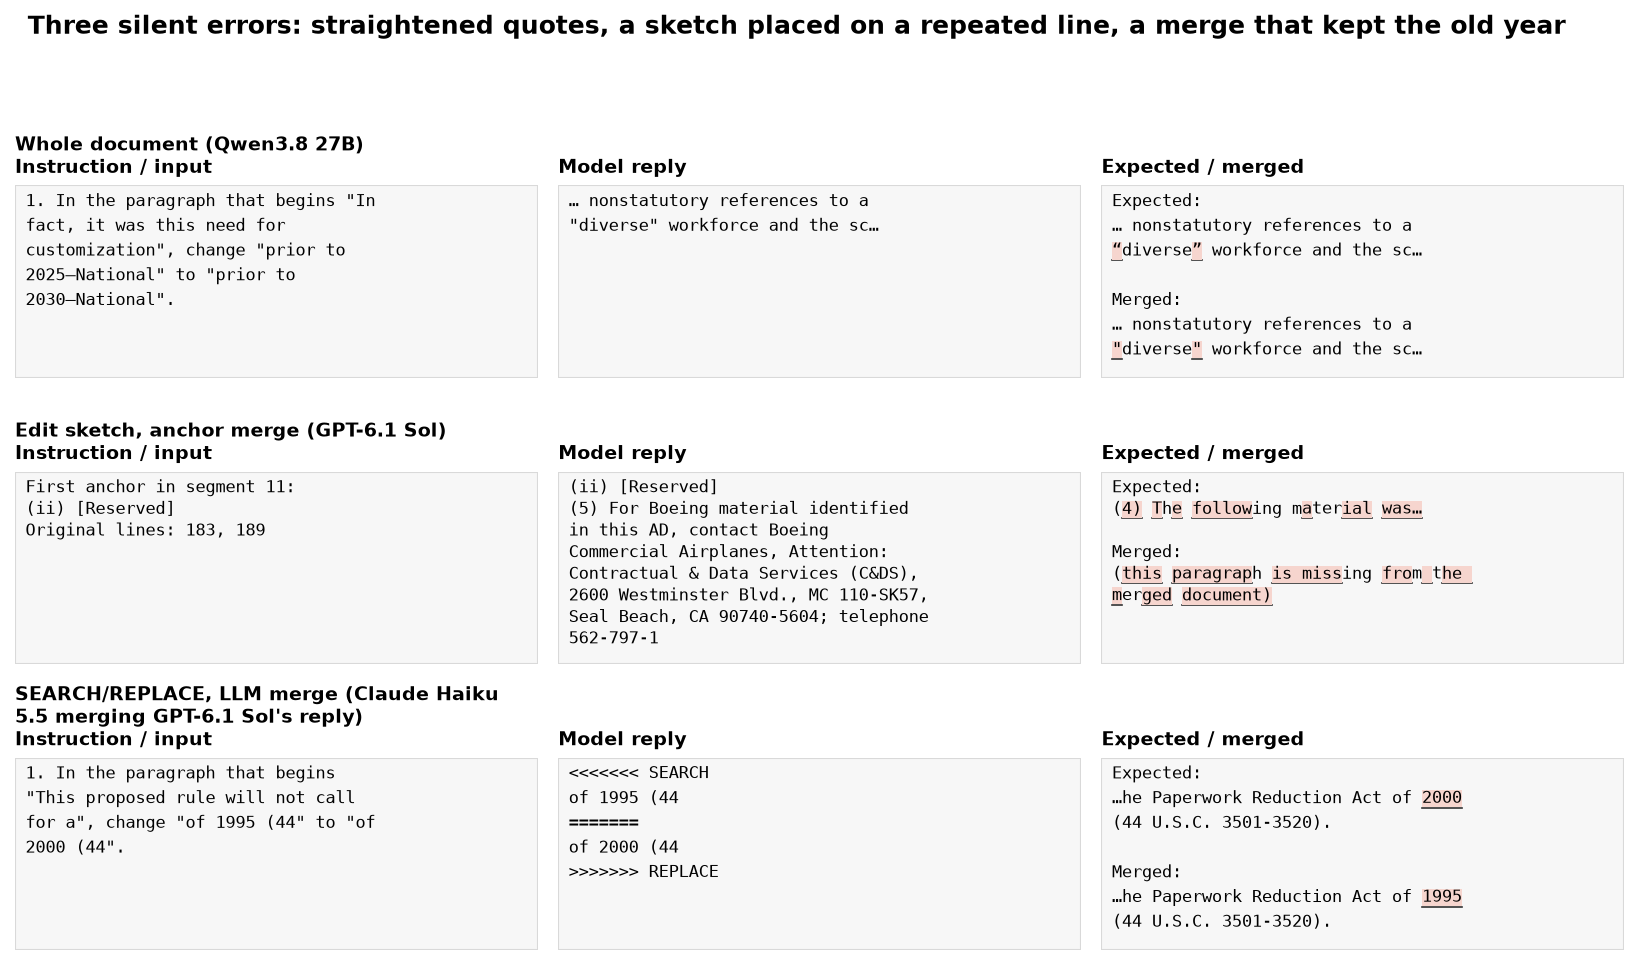

In [32]:
if not MERGES.empty:
    SILENT_ERROR_CASES = silent_error_panel_items([QUOTE_CASE, SKETCH_CASE, MERGE_CASE])
    display(fig_case_panel(SILENT_ERROR_CASES, ROOT / 'figures' / 'examples_silent_errors.png', title=TITLES['examples']))
    plt.close()

All six edits were made, but the inserted paragraph and the moved one were written without a blank line before them,
so in Markdown each runs into the paragraph above. The document is exact if blank lines are ignored. Twelve of the 39
wrong line-number documents are of this kind; asking for the blank separator in inserted text, or normalising
paragraph breaks after merging, would recover them.

The figure above puts three of these silent errors side by side. Each row shows the instruction or the relevant input,
what the model wrote, and the expected text against the merged text, with the differing characters highlighted and
underlined. In the first row the only difference is the shape of the quotation marks; in the second, a paragraph that
should be there is missing; in the third, the year is the one the edit asked to remove.

## 12. Spend

The spend table gives calls, tokens, list cost and model time by model and stage. Claude cost is the list price the
Claude CLI reports; OpenRouter cost is what OpenRouter charged; GPT-6.1 Sol ran under a Codex subscription whose CLI
reports tokens but no cost, so its cost is blank.

In [33]:
if not GENERATIONS.empty:
    SPEND_RESULTS = spend_table(GENERATIONS)
    display(SPEND_RESULTS)

,model,stage,calls,input_tokens,input_tokens_missing,output_tokens,output_tokens_missing,list_cost_usd,list_cost_usd_missing,latency_s,latency_s_missing,reported_list_cost_usd
0,GPT-6.1 Sol,generation,288,4851599.0,0,854993.0,0,NaN,288,12032.0740,0,NaN
1,GPT-6.1 Sol,retry,88,1765630.0,0,297752.0,0,NaN,88,4514.7954,0,NaN
2,Claude Sonnet 5.5,generation,288,576.0,0,1391709.0,0,31.242670,0,8497.9941,0,31.242670
3,Claude Sonnet 5.5,retry,72,144.0,0,506026.0,0,11.084352,0,2989.3399,0,11.084352
4,Claude Haiku 5.5,generation,288,606.0,0,3700338.0,0,2.791145,0,14392.3214,0,2.791145
5,Claude Haiku 5.5,retry,84,192.0,0,1897020.0,0,1.331515,0,7540.7360,0,1.331515
6,Claude Haiku 5.5,merge,525,NaN,1,NaN,1,NaN,1,24595.7760,0,5.464338
7,DeepSeek V4.1 Flash,generation,288,2586608.0,0,2390541.0,0,0.736424,0,29017.7768,0,0.736424
8,DeepSeek V4.1 Flash,retry,80,1027165.0,0,894125.0,0,0.296126,0,12477.9066,0,0.296126
9,Qwen3.8 27B,generation,288,2849600.0,0,2655844.0,0,3.673626,0,16426.3847,0,3.673626


The study made 2,404 model calls: 1,440 first replies, 439 retries and 525 merges. Claude list price was $51.91
(Claude Sonnet 5.5 $42.33, Claude Haiku 5.5 $9.59 including $5.46 of merging) and OpenRouter spend $7.17 (Qwen3.8 27B
$6.14, DeepSeek V4.1 Flash $1.03). GPT-6.1 Sol used 6.6 million input and 1.2 million output tokens. One merge call
failed four times and is recorded as an error; no first reply or retry failed in transport.

The last check runs the result tables and figures on synthetic replies built from the known answers, with deliberate
corruptions so that every outcome occurs. It tests the analysis code, not the models: its numbers are not results.

In [34]:
PIPELINE_TESTS = run_pipeline_table_tests()

### 2026-21949_one: GPT-6.1 Sol, SEARCH/REPLACE blocks, fuzzy + retry

1. In the paragraph that begins "This proposed rule will not call for a", change "of 1995 (44" to "of 2000 (44".

Status: exact; edits completed 1/1; failed blocks 0; reply used: retry.

Generation reply (28 characters):

```text
An invalid local fake reply.
```

First application failures and notes:

```text
{
  "failures": [
    {
      "block": 0,
      "reason": "no_blocks",
      "detail": "No SEARCH/REPLACE blocks were found."
    }
  ],
  "notes": []
}
```

Corrective message received by the model (after the original prompt):

```text
local retry
```

Retry reply (310 characters):

```text
<<<<<<< SEARCH

This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 1995 (44 U.S.C. 3501-3520).

=======

This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 2000 (44 U.S.C. 3501-3520).

>>>>>>> REPLACE
```

Final status: exact; edits completed 1/1.

Expected versus merged (up to 60 wrapped lines):

```diff
(No differences.)
```

### 2026-21949_one: GPT-6.1 Sol, Whole document, as written

1. In the paragraph that begins "This proposed rule will not call for a", change "of 1995 (44" to "of 2000 (44".

Status: wrong; edits completed 0/1; failed blocks 0; reply used: generation.

Generation reply (11,840 characters; first 2,500 shown):

```text
# Special Local Regulation; Port Miami Main Shipping Channel, Miami FL

## AGENCY:

Coast Guard, Department of Homeland Security.

## ACTION:

Notice of proposed rulemaking.

## SUMMARY:

The Coast Guard is proposing to establish a temporary special local regulation (SLR) for certain navigable waters of the Miami Shipping Channel offshore of Port Miami, Miami, FL in connection with the E1 Miami Grand Prix. The SLR is needed to protect personnel, vessels, and the marine environment from potential hazards created by high-speed powerboat racing. This proposed rulemaking would prohibit persons and vessels from being in or loitering around the regulated area unless specifically authorized by the Captain of the Port, Sector Miami. We invite your comments on this proposed rulemaking.

## DATES:

Comments and related material must be received by the Coast Guard on or before November 4, 2026.

## ADDRESSES:

To submit comments and view available documents, go to the Federal Docket Management System at https://www.regulations.gov and search for USCG-2026-1152.

## FOR FURTHER INFORMATION CONTACT:

If you have questions about this proposed rule, contact MST2 Elliot Cortes Waterways Management Division, U.S. Coast Guard; telephone 786-295-9051, or email SectorMiamiWaterways@uscg.mil.

## SUPPLEMENTARY INFORMATION:

## I. Table of Abbreviations

CFR Code of Federal Regulations

COTP Captain of the Port

DHS Department of Homeland Security

FR Federal Register

NPRM Notice of proposed rulemaking

§ Section

U.S.C. United States Code

## II. Background and Authority

On July 22, 2026, Electric Sea Racing Limited notified the Coast Guard that it will be conducting the E1 Miami Grand Prix race on November 11, 2026, from 8 a.m. to 2 p.m., November 12, 2026, from 8 a.m. to 3:30 p.m., and November 13 through November 14, 2026, from 8 a.m. to 2 p.m. The race will take place in the Main Shipping Channel, offshore of Port Miami, Miami, FL, and involve approximately 12 electric high-speed powerboats 24 feet in length with no more than 5 racing at a time.

The Captain of the Port Miami (COTP) is issuing this Special Local Regulation (SLR) under the authority in 46 U.S.C. 70041. The purpose of this rulemaking is to protect event participants, spectators, and vessels on certain navigable waters of the Main Shipping Channel, offshore of Port Miami, Miami, FL before, during, and after the scheduled event.

## III. Discussion of the Proposed Rule

This proposed rule would establish a s
```

Application failures and notes:

```text
{
  "failures": [],
  "notes": [
    "no_tags"
  ]
}
```

Final status: wrong; edits completed 0/1.

Expected versus merged (up to 60 wrapped lines):

```diff
--- expected
+++ merged
@@ -68,7 +68,7 @@
 
 ### B. Collection of Information
 
-This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 
2000 (44 U.S.C. 3501-3520).
+This proposed rule will not call for a new collection of information under the Paperwork Reduction Act of 
1995 (44 U.S.C. 3501-3520).
 
 ### C. Federalism and Indian Tribal Governments
 
```

C:\Users\sandh\AppData\Local\Temp\ipykernel_61752\549121124.py:93: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, bottom, 1, 0.96 - title_height))


C:\Users\sandh\AppData\Local\Temp\ipykernel_61752\549121124.py:93: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, bottom, 1, 0.96 - title_height))


Pipeline/scoring/analysis local-fake checks: 158 passed; 9 figures tested in a temporary folder; no experimental data/results or production figures written.


## 13. Limitations

- The edits are mechanical. Every request gives the exact new text, so the study measures whether the format and the
  merge put the right text in the right place, not whether a model writes good prose or understands a vague request
  ("tighten this section"). Inserted text comes from other documents and does not fit its context, and some number
  changes make the text factually wrong, which may push a model (or the merge model, as in the 1995 example) to
  resist an edit.
- Some instructions can be read two ways. In the OPM rule, the paragraph to delete introduces a two-item list, and
  several replies (mostly DeepSeek V4.1 Flash and Qwen3.8 27B) deleted the list too; the instruction names one
  paragraph, so these count as wrong. Two rename answers were widened after the replies were seen, for the plural
  `ORVs` and for `FEVS` inside a link; both versions are reported in section 10.
- The sample is small: 9 documents, 36 requests, 5 models, one reply each. Intervals on 180 requests are about ±6
  points and do not account for requests sharing documents. Differences of a few requests between the top formats are
  not findings, and GPT-6.1 Sol is at the ceiling in three formats.
- One kind of document: formal prose with one paragraph per line and few repeated lines. Code, hard-wrapped text or
  documents with many identical lines may change the line-number and anchor results.
- Each format has one prompt, apart from the two patch wordings, which show how much wording can matter. The
  find-and-replace formats had no "replace all" option, which would likely fix their rename failures.
- The study corrected its own instruments three times after seeing replies: a second patch wording and a merge rule for
  repeated `@@` lines, the diff tools receiving the raw diff with a final newline, and the two rename answers. Each is
  recorded in `data/PROTOCOL.md` with its counts, and the results without it are reported, but none was fixed in
  advance.
- The models ran through their CLIs or one provider each, at medium reasoning effort; other harnesses, providers or
  settings may behave differently.

### What the evidence supports

For edits whose new text is known, ask for find-and-replace pairs (JSON or marked blocks), apply them with an exact
match, and send any failed block back once with the error. For every model here except DeepSeek V4.1 Flash, that
pipeline was the most accurate or tied for it; it was also the cheapest and fastest, and its failures were mostly
omissions, so add a check after merging that each requested new text is present (and, for a rename, that the old term
is gone). Do not add fuzzy matching; it rescued nothing here and can misplace an edit. For a rename across a long
document, give the format a replace-all option or let a strong model rewrite the document. If you use diffs, apply
them with GNU `patch`, `git apply --recount` or a context search, not plain `git apply`. Do not use a small model to
merge short find-and-replace blocks into a long document. The uncertainty that most needs another experiment is
whether this holds for free-form edits, where the model writes the new text itself.

## 14. How to reproduce

Run the notebook from its folder: `python -m nbconvert --to notebook --execute --inplace 38_long_text_edits.ipynb`.
It reads every reply from the compressed caches `data/cache_cli.jsonl.gz` and `data/cache_openrouter.jsonl.gz`
(new calls append to the plain `.jsonl` files beside them), re-runs every merge method (it
needs `git`, and GNU `patch` for that method; Git for Windows includes both) and checks the frozen documents, requests
and answers against their hashes. Set `NB_LIVE=1` to allow new calls (`claude`, `codex` and `OPENROUTER_API_KEY`);
`NB_N_DOCS` and `NB_MODELS` set the size, and the budget guards stop at 3,000 CLI calls, USD 80 of Claude list price
and USD 15 of OpenRouter spend. `data/PROTOCOL.md` records the run history. The code was written by GPT-6.1 Sol through the Codex CLI from the
specifications in `data/protocol/`, which also holds its implementation notes; the prose was written separately. The last cell prints what the cached calls cost.

In [35]:
def print_spend():
    rows = [row for cache in [CLI_CACHE, OR_CACHE] for row in cache.rows.values()
            if row['request'].get('protocol') == PROTOCOL]
    calls = Counter()
    costs = Counter()
    for row in rows:
        backend, response = row['request']['backend'], row['response']
        calls[backend] += response.get('attempts', 1)
        costs[backend] += float(response.get('list_cost_usd') or 0)
    print(f'Claude list price: ${costs["claude"]:.4f}; OpenRouter: ${costs["openrouter"]:.4f}; '
          f'cached call counts by backend: {dict(calls)}')
    if spend['unreported_claude_usd_bound'] or spend['unreported_or_usd_bound']:
        print('Unreported transport-attempt cost upper bounds:',
              {k: v for k, v in spend.items() if k.startswith('unreported')})
    print('Codex subscription cost is not reported by its CLI; it is left blank in generations.csv.')


print_spend()

Claude list price: $51.9140; OpenRouter: $7.1716; cached call counts by backend: {'codex': 379, 'claude': 1260, 'openrouter': 771}
Unreported transport-attempt cost upper bounds: {'unreported_claude_usd_bound': 2.0, 'unreported_or_usd_bound': 0.0}
Codex subscription cost is not reported by its CLI; it is left blank in generations.csv.


## 15. Future work and further reading

### Future work

- Free-form edits. Replace the given new text with requests such as "make this paragraph shorter", scored by a judge
  for the edited passage and by the collateral measure for the rest. The find-and-replace result depends on knowing the
  new text; this would test it when the model writes the text.
- A replace-all option. Add `"replace_all": true` to the JSON format and re-run the 9 rename requests, where
  find-and-replace reached 47% to 51% and the whole rewrite 84%.
- Other kinds of text. Repeat the comparison on code files, hard-wrapped Markdown and documents with many repeated
  lines, where line numbers, anchors and unique quotes are harder than in Federal Register prose.
- A merge model that only places edits. Ask the second model for the location of each block and let code apply it, to
  keep its help with sketches (27 replies it placed better than the anchor merge) without its omissions.
- Three samples per request and model, to separate the top formats, which differ by a few requests here.

### Further reading

Links checked on 30 October 2026.

- [Diff-XYZ: A Benchmark for Evaluating Diff Understanding](https://arxiv.org/abs/2510.12487) (Glukhov et al., 2025).
  Tests models on applying, reversing and generating code diffs in several formats and finds search-replace best for
  large models, the closest published comparison to this study.
- [Can It Edit? Evaluating the Ability of Large Language Models to Follow Code Editing Instructions](https://arxiv.org/abs/2312.12450)
  (Cassano et al., 2023). A benchmark of instructed code edits, which measures whether an edit is right rather than how
  it is written and merged.
- [Fuzzy Patch](https://neil.fraser.name/writing/patch/) (Fraser, 2006). Why line-based context matching can apply a
  patch in the wrong place, and a fuzzy alternative weighted by expected location.
- [An O(ND) difference algorithm and its variations](https://doi.org/10.1007/BF01840446) (Myers, 1986). The algorithm
  behind `diff` and `git diff`, which produced the expected diffs in this study's self-test.
- [Unified diffs make GPT-4 Turbo 3X less lazy](https://aider.chat/docs/unified-diffs.html) (Gauthier, 2023). Aider's
  account of moving a model from SEARCH/REPLACE blocks to simplified diffs applied flexibly, ignoring line numbers.
- [Editing files at 1000 tokens per second](https://cursor.com/blog/instant-apply) (Sanger, 2024). Why one code editor
  has a model rewrite the whole file and speeds that up with speculative decoding instead of asking for diffs.